# Sales Forecasting with Machine Learning: Daily Units and Orders

## Objective
The goal of this notebook is to build a **machine learning model** that forecasts Parfois' daily sales volume and to assess whether it improves on a simple baseline. The main business use case, as described by the client, is **warehouse management**: estimating how many people will be needed to fulfil incoming orders.

Since warehouse workload depends on both the number of items handled and the number of orders processed, we forecast two targets:

- **Orders** – the number of distinct orders (`ORDER_ID`).
- **Units** – the number of items sold (`PROD_QTY`).

This notebook covers the machine learning approach. The **baseline and statistical models** are developed in a separate notebook by a teammate, and their results are used here as the benchmark.

## Scope
| Item | Decision |
|---|---|
| **Targets** | Units and orders |
| **Granularity** | One row per order (`ORDER_ID`), product (`PROD_SFK`) and transaction type (`TYPE`) |
| **Markets** | Portugal and Spain only. The client noted that including other markets could dilute the information. Markets are identified using [Online PT] and [Online ES] |
| **Forecast horizon** | One month ahead (about 30 days) |
| **Data available** | Orders from January 2024 to December 2025 |

## Approach
1. **Build the base table (`base_ml`):** join `order_det`, `order_cab`, `product` and `events` into one table with one row per order, product and transaction type (`TYPE`). It keeps only the markets in scope, adds the product category (`CAT_DES_EN`) and counts the campaigns running on each order date (`n_events`).
2. **Create features** that give the model context beyond the series itself:
   - calendar features (day of the week, month, holidays);
   - past values of the target (for example, lags);
   - external information, such as campaigns (`events`) and paid media investment (`paid_media`), when it is known in advance.
3. **Define a time-based validation**, training on the past and testing, with one month of interval, on the following 30 days, repeated over several windows. Random splits are not used, as they would leak future information.
4. **Choose the forecasting strategy.** Since the horizon is 30 days, lag features must only use information that would be available at the time of the forecast.
5. **Train established machine learning models** from existing libraries, such as tree-based models, rather than building models from scratch.
6. **Compare the models** with the baseline on the same windows and metrics, and keep a model only if it consistently beats the baseline.

## Error metrics
Models are compared using four metrics, all computed on the test windows (data the model has not seen):

- **WAPE (Weighted Absolute Percentage Error):** the sum of all absolute errors divided by the sum of the actual values. It reads as "overall, the forecast is off by X% of actual volume". Unlike MAPE, it remains stable on days with very low volume.

  $$\text{WAPE} = \frac{\sum |y_t - \hat{y}_t|}{\sum y_t} \times 100$$

- **Bias:** the sum of the forecast errors, keeping their sign, divided by the sum of the actual values. It shows whether the model systematically overestimates (positive bias) or underestimates (negative bias) the volume. A model can have a low WAPE and still be biased; for warehouse planning this matters, as a persistent underestimate leads to understaffing and a persistent overestimate to idle staff.

  $$\text{Bias} = \frac{\sum (\hat{y}_t - y_t)}{\sum y_t} \times 100$$

- **RMSE (Root Mean Squared Error):** the square root of the average squared error, expressed in the same unit as the target (orders or units per day). Because errors are squared before averaging, large errors weigh much more than small ones. This makes RMSE suitable for this use case, where a few days with large misses are more costly for staffing than many days with small errors.

  $$\text{RMSE} = \sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$$

- **R² (coefficient of determination):** the share of the day-to-day variation in the actual values that the forecast explains. A value of 1 means a perfect forecast, 0 means the forecast is no better than predicting the average of the test period, and negative values mean it is worse than that average. As it is computed over short test windows, R² depends on how much the volume varies within each window, so it is used as a complementary metric rather than the main criterion.

  $$R^2 = 1 - \frac{\sum (y_t - \hat{y}_t)^2}{\sum (y_t - \bar{y})^2}$$

where $y_t$ is the actual value on day $t$, $\hat{y}_t$ is the forecast, $\bar{y}$ is the average of the actual values in the test window, and $n$ is the number of days.


## Known limitations
- The data covers only **two years**, so yearly seasonality can be observed only by comparing 2025 with 2024. Complex models, in particular deep learning, are unlikely to be justified with so little history.
- External variables (campaigns, paid media) are only useful if their future values are known at forecast time.
- Order dates reflect when the order was placed, which may differ from when the warehouse processes it.

## 1. Data source

This project is based on a **static historical dataset**, not on continuously updated data. The analysis covers orders from January 2024 to December 2025, and no new data is expected to arrive while the models are developed and evaluated.

For this reason, the notebook connects **directly to the Parquet file(s) built locally**, instead of querying the source database or the data platform on every run. This has three practical advantages:
- **Reproducibility:** every run uses exactly the same data, so results can be compared across models and over time.
- **Speed and stability:** reading a local Parquet file is faster than running queries on the shared database, which cut long-running queries during exploration.
- **Independence:** the notebook does not depend on the data platform being up or on database access.

The trade-off is that the local file does not reflect any later changes in the source system. If the data were refreshed, the extraction would need to be repeated and the results re-run.

In [1]:
import mlflow
import pandas as pd

from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()   # bucket names and credentials come from the vault
con = connect()                # in-memory DuckDB already wired to the data lake

print('MLflow tracking server:', mlflow.get_tracking_uri())
print('Gold datasets available in the lake:')
con.sql(f"SELECT file FROM glob('{lake.uri('gold')}/*.parquet')").show()

MLflow tracking server: http://mlflow:5000
Gold datasets available in the lake:
┌─────────┐
│  file   │
│ varchar │
└─────────┘
  0 rows 



## 2. Building the base table (`base_ml`)

### Purpose
This section describes how `base_ml` is built from the source tables. Its grain is **one row per order (`ORDER_ID`), product (`PROD_SFK`) and transaction type (`TYPE`)**.

### Steps
1. **Setup and column checks.** The source tables are read directly from the Parquet files in the data lake. The code looks up three columns by name, ignoring upper and lower case: the product key in `product`, the category `CAT_DES_EN` and the product key in `order_det`. It stops with a clear message if any is missing. The market column of `events` is detected automatically only if `COL_EV_MARKET` is set to `None`; otherwise the name given is used as it is.
2. **Order lines with product and category.** Each line of `order_det` is linked to `product` (`order_det.PROD_SFK = product.PROD_SPK`) to get the category `CAT_DES_EN`. `product` is first reduced to one category per product key, so the join cannot duplicate order lines. Products without a category are labelled `WO_CAT` instead of being dropped.
3. **One row per order from `order_cab`.** The header table repeats an order's information for each of its lines, so it is reduced to a single row per `ORDER_ID` before joining. Without this step, every `order_det` line would be duplicated.
4. **Grouping the lines.** Lines are grouped by order, product and `TYPE`, and `PROD_QTY` and both amounts are summed. `TYPE` is part of the grouping so that a sale and a return of the same product are never netted into a single row. The category is carried along, but it depends only on the product, so it does not add rows.
5. **Events.** For each distinct pair (order day, market), the code counts the events of the same market whose period (`Start_date` to `End_date`, both included) contains that day. The result is `n_events` (the number of matching event records) and `events_list` (their names). A day can fall within several events, so `events_list` can hold a combination such as `Event A; Event B`.
6. **Final join and filters.** The grouped lines are joined to the order data and to the event information. The result is filtered to the markets in `MARKETS`, with values compared after trimming spaces and ignoring case, and to orders dated `BEGINING_DATE` or later. Orders without a valid date are excluded by this filter.
7. **Grouped events (helper view).** The code also creates `events_grouped_v`, with one row per campaign family, market and continuous period. Event names are cleaned and mapped to families with the same rules used in the baseline notebook, and overlapping or consecutive records of the same family are merged (for example, "Last Days" and "Last Hours" of Valentines become a single Valentines period). This view is not used in `base_ml`; it is used later to build the campaign features.

### Output columns
`TYPE`, `ORDER_ID`, `PROD_SFK`, `CAT_DES_EN`, `PROD_QTY`, `AMOUNT_FIXED_RATE_W_DISC_WO_VAT`, `AMOUNT_FIXED_RATE_WO_DISC_WO_VAT`, `ORDER_DATE`, `ORDER_ORIGIN`, `ORDER_CHANEL_TYPE`, `CUSTOMER_ID_FK`, `MARK_COD`, `n_events` and `events_list`.

### Design choices
- **Views, not files.** `det_cat_v` and `base_ml` are temporary views kept in memory: nothing is written to disk, and the data is recalculated each time the view is queried.
- **Market matching.** `MARK_COD` identifies the market in both `order_cab` and `events`, so it is the column used to match events to orders.
- **Order data.** Where an order's header information is repeated, the minimum value is kept. This assumes that the header data is consistent within an order.
- **Date column.** The model works with `ORDER_DATE`. The movement date of each line (`MOV_DATE_SFK`) is not kept, as `TYPE` already separates sales from returns.

### Validation checks
The code runs nine checks:
1. how many products used in `base_ml` have more than one category in `product`;
2. how many `order_det` lines in scope have no category;
3. whether any quantity or amount value is lost in the numeric conversion;
4. reconciliation of `order_det` in scope with `base_ml` (orders, units and amounts; the difference must be 0);
5. how many `order_det` lines have no header in `order_cab`;
6. rows, quantity and amount by `TYPE`;
7. the distribution of `n_events`;
8. the quality of the event data (missing or invalid dates, duplicates);
9. that the key (`ORDER_ID`, `PROD_SFK`, `TYPE`) is unique, which means the number of rows equals the number of distinct keys.

### Limitations
- `events_list` is text. For modelling, `n_events` or one indicator column per relevant event will be used instead.
- `n_events` counts event records, so duplicated records in `events` would be counted more than once.
- Events are matched on `ORDER_DATE`, not on the movement date.
- Lines of the same order, product and `TYPE` that occurred on different dates are summed together, because the movement date is not kept.
- If a product has more than one category in `product`, the first one in alphabetical order is used.

In [2]:
import pandas as pd
from lakehouse import LakeConfig, connect

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

lake = LakeConfig.from_env()
con_b = connect()

# ---------- Configuration ----------
BEGINING_DATE = "2024-01-01"          # None to disable the date filter
COL_EV_MARKET = "Mark_cod"           # None = detect automatically; or write "MARK_COD"
PRODUCT_KEY = "PROD_SPK"          # Product ID in product table
ORDER_DET_KEY = "PROD_SFK"        # matching key in order_det
WO_CAT = "WO_CAT"     # label for products without a category
MARKETS = ["online pt", "online es"]     # markets to keep (case-insensitive)
# ----------------------------------

def source(table):
    p = lake.uri("bronze", f"mysql/{table}/**/*.parquet")
    return f"read_parquet('{p}', union_by_name=true)"

def get_columns(src):
    return con_b.sql(f"DESCRIBE SELECT * FROM {src}").df()["column_name"].tolist()

def find_column(cols, name):
    for c in cols:
        if c.lower() == name.lower():
            return c
    raise ValueError(f"Column '{name}' not found. Available columns: {cols}")

hdr_src, det_src, ev_src, prod_src = source("order_cab"), source("order_det"), source("events"), source("product")

# 0. Required columns
cols_prod = get_columns(prod_src)
COL_PROD_KEY = find_column(cols_prod, PRODUCT_KEY)
COL_CAT = find_column(cols_prod, "CAT_DES_EN")
COL_DET_KEY = find_column(get_columns(det_src), ORDER_DET_KEY)
print(f"product.{COL_PROD_KEY} links to order_det.{COL_DET_KEY}; category = product.{COL_CAT}")

cols_ev = get_columns(ev_src)
if COL_EV_MARKET is None:
    cand = [c for c in cols_ev if "mark" in c.lower()]
    if len(cand) != 1:
        raise ValueError(f"Could not choose the market column in events. Candidates: {cand}.")
    COL_EV_MARKET = cand[0]
print("events: market column =", COL_EV_MARKET)

# 1. order_det lines with product key and category (helper view, in memory)
con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW det_cat_v AS
    WITH prod_t AS (
        SELECT CAST("{COL_PROD_KEY}" AS VARCHAR) AS prod_key,
               MIN(CAST("{COL_CAT}" AS VARCHAR)) AS prod_cat
        FROM {prod_src}
        GROUP BY 1
    )
    SELECT CAST(d.ORDER_ID AS VARCHAR) AS order_id_str,
           d.ORDER_ID AS order_id_raw,
           d."{COL_DET_KEY}" AS prod_id,
           d."TYPE" AS line_type,
           COALESCE(p.prod_cat, '{WO_CAT}') AS category,
           TRY_CAST(d.PROD_QTY AS DOUBLE) AS qty,
           TRY_CAST(d.AMOUNT_FIXED_RATE_W_DISC_WO_VAT AS DOUBLE) AS amt_w_disc,
           TRY_CAST(d.AMOUNT_FIXED_RATE_WO_DISC_WO_VAT AS DOUBLE) AS amt_wo_disc
    FROM {det_src} d
    LEFT JOIN prod_t p ON p.prod_key = CAST(d."{COL_DET_KEY}" AS VARCHAR)
""")

# 2. Grouped events: one row per campaign family, market and continuous period (helper view, in memory)
#     - event names are cleaned and mapped to families with the same rules used in the baseline notebook
#     - overlapping or consecutive records of the same family in the same market are merged
#       (e.g. "Last Days" + "Last Hours" Valentines -> one Valentines period)
con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW events_grouped_v AS
    WITH ev_raw AS (
        SELECT UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS market,
               REGEXP_REPLACE(TRIM(CAST(Event AS VARCHAR)), '\\s+', ' ', 'g') AS clean_name,
               TRY_CAST(Start_date AS DATE) AS s,
               TRY_CAST(End_date AS DATE) AS e
        FROM {ev_src}
    ),
    ev_named AS (
        SELECT market, s, e,
               CASE
                   WHEN clean_name ILIKE 'Black Friday%'            THEN 'Black Friday'
                   WHEN clean_name ILIKE 'Clearance%'               THEN 'Clearance'
                   WHEN clean_name ILIKE 'Special Prices%'          THEN 'Special prices'
                   WHEN clean_name ILIKE 'Free Shipping%'           THEN 'Free shipping'
                   WHEN clean_name ILIKE '%Valentines%'             THEN 'Valentines'
                   WHEN clean_name ILIKE '%Mothers Day%'            THEN 'Mothers Day'
                   WHEN clean_name ILIKE '%Christmas%'              THEN 'Christmas'
                   WHEN clean_name ILIKE '%Reyes%'                  THEN 'Reyes'
                   WHEN clean_name IN ('Easter Weeks', 'Holy Week') THEN 'Easter and Holy Week'
                   WHEN clean_name = 'Get your basket ready'        THEN 'Get your basket ready'
                   WHEN clean_name = 'Stock 1'                      THEN 'Stock 1'
                   WHEN clean_name ILIKE 'Apag%'                    THEN 'Iberian blackout'
                   ELSE 'Other'
               END AS campaign
        FROM ev_raw
        WHERE s IS NOT NULL AND e IS NOT NULL AND e >= s          -- valid periods only
    ),
    ordered AS (
        SELECT *,
               MAX(e) OVER (PARTITION BY market, campaign ORDER BY s, e
                            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS prev_max_end
        FROM ev_named
    ),
    islands AS (
        SELECT *,
               SUM(CASE WHEN prev_max_end IS NULL OR s > prev_max_end + 1 THEN 1 ELSE 0 END)
                   OVER (PARTITION BY market, campaign ORDER BY s, e ROWS UNBOUNDED PRECEDING) AS period_id
        FROM ordered
    )
    SELECT market, campaign,
           MIN(s) AS start_date,
           MAX(e) AS end_date,
           COUNT(*) AS n_source_records
    FROM islands
    GROUP BY market, campaign, period_id
""")

# 3. Base table: one row per order, product and TYPE
markets_sql = ", ".join("'" + m.lower() + "'" for m in MARKETS)
conditions = [f"LOWER(TRIM(CAST(hdr.o_market AS VARCHAR))) IN ({markets_sql})"]
if BEGINING_DATE:
    conditions.append(f"hdr.o_date >= TIMESTAMP '{BEGINING_DATE}'")
where_clause = "WHERE " + " AND ".join(conditions)

con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW base_ml AS
    WITH hdr AS (
        -- one row per order (order_cab repeats the header for each line)
        SELECT CAST(ORDER_ID AS VARCHAR) AS order_id_str,
               MIN(TRY_CAST(ORDER_DATE AS TIMESTAMP)) AS o_date,
               MIN(ORDER_ORIGIN) AS o_origin,
               MIN(ORDER_CHANEL_TYPE) AS o_channel,
               MIN(CAST(CUSTOMER_ID_FK AS VARCHAR)) AS o_customer,
               MIN(MARK_COD) AS o_market
        FROM {hdr_src}
        GROUP BY 1
    ),
    det_g AS (
        -- sum quantities and amounts per order, product and TYPE
        SELECT order_id_str, MIN(order_id_raw) AS order_g, prod_id, category,
               line_type AS type_g,
               SUM(qty) AS qty_sum, SUM(amt_w_disc) AS amt_w_disc_sum, SUM(amt_wo_disc) AS amt_wo_disc_sum
        FROM det_cat_v
        GROUP BY order_id_str, prod_id, category, line_type
    ),
    ev_t AS (
        SELECT UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS ev_market,
               CAST(Event AS VARCHAR) AS ev_name,
               TRY_CAST(Start_date AS DATE) AS ev_start,
               TRY_CAST(End_date AS DATE) AS ev_end
        FROM {ev_src}
    ),
    pairs AS (
        -- distinct (order day, market) pairs
        SELECT DISTINCT CAST(o_date AS DATE) AS order_day,
               UPPER(TRIM(CAST(o_market AS VARCHAR))) AS market_norm
        FROM hdr
    ),
    ev_pairs AS (
        -- events of the same market whose period contains the order day
        SELECT p.order_day, p.market_norm,
               COUNT(e.ev_market) AS n_events,
               STRING_AGG(DISTINCT e.ev_name, '; ') AS events_list
        FROM pairs p
        LEFT JOIN ev_t e
               ON e.ev_market = p.market_norm AND p.order_day BETWEEN e.ev_start AND e.ev_end
        GROUP BY p.order_day, p.market_norm
    )
    SELECT dg.type_g AS "TYPE",
           dg.order_g AS ORDER_ID,
           dg.prod_id AS PROD_SFK,
           dg.category AS CAT_DES_EN,
           dg.qty_sum AS PROD_QTY,
           dg.amt_w_disc_sum AS AMOUNT_FIXED_RATE_W_DISC_WO_VAT,
           dg.amt_wo_disc_sum AS AMOUNT_FIXED_RATE_WO_DISC_WO_VAT,
           hdr.o_date AS ORDER_DATE,
           hdr.o_origin AS ORDER_ORIGIN,
           hdr.o_channel AS ORDER_CHANEL_TYPE,
           hdr.o_customer AS CUSTOMER_ID_FK,
           hdr.o_market AS MARK_COD,
           COALESCE(evp.n_events, 0) AS n_events,
           evp.events_list AS events_list
    FROM det_g dg
    JOIN hdr ON hdr.order_id_str = dg.order_id_str
    LEFT JOIN ev_pairs evp
           ON evp.order_day = CAST(hdr.o_date AS DATE)
          AND evp.market_norm = UPPER(TRIM(CAST(hdr.o_market AS VARCHAR)))
    {where_clause}
""")

# 4. Validation checks (scope: markets in MARKETS, orders since BEGINING_DATE)
date_cond = f"AND o_date >= TIMESTAMP '{BEGINING_DATE}'" if BEGINING_DATE else ""
con_b.sql(f"""
    CREATE OR REPLACE TEMP VIEW scope_orders_v AS
    SELECT order_id_str
    FROM (
        SELECT CAST(ORDER_ID AS VARCHAR) AS order_id_str,
               MIN(TRY_CAST(ORDER_DATE AS TIMESTAMP)) AS o_date,
               MIN(MARK_COD) AS o_market
        FROM {hdr_src}
        GROUP BY 1
    )
    WHERE LOWER(TRIM(CAST(o_market AS VARCHAR))) IN ({markets_sql})
    {date_cond}
""")
in_scope = "order_id_str IN (SELECT order_id_str FROM scope_orders_v)"

print("1. Products in base_ml with more than one category in product:")
display(con_b.sql(f"""
    WITH prod_cats AS (
        SELECT CAST("{COL_PROD_KEY}" AS VARCHAR) AS k, COUNT(DISTINCT "{COL_CAT}") AS n_cat
        FROM {prod_src} GROUP BY 1
    ),
    used AS (SELECT DISTINCT CAST(PROD_SFK AS VARCHAR) AS k FROM base_ml)
    SELECT COUNT(*) AS products_in_base_ml,
           COUNT(*) FILTER (WHERE pc.n_cat > 1) AS with_several_categories
    FROM used u LEFT JOIN prod_cats pc USING (k)
""").df())

print("2. order_det lines in scope without a category:")
display(con_b.sql(f"""
    SELECT COUNT(*) AS lines_in_scope,
           COUNT(*) FILTER (WHERE category = '{WO_CAT}') AS lines_without_category,
           COALESCE(SUM(qty) FILTER (WHERE category = '{WO_CAT}'), 0) AS qty_without_category
    FROM det_cat_v WHERE {in_scope}
""").df())

print("3. Values lost in numeric conversion (non-null in source, NULL after TRY_CAST), in scope:")
display(con_b.sql(f"""
    SELECT
      COUNT(*) FILTER (WHERE PROD_QTY IS NOT NULL
                         AND TRY_CAST(PROD_QTY AS DOUBLE) IS NULL) AS qty_not_numeric,
      COUNT(*) FILTER (WHERE AMOUNT_FIXED_RATE_W_DISC_WO_VAT IS NOT NULL
                         AND TRY_CAST(AMOUNT_FIXED_RATE_W_DISC_WO_VAT AS DOUBLE) IS NULL) AS amt_w_disc_not_numeric,
      COUNT(*) FILTER (WHERE AMOUNT_FIXED_RATE_WO_DISC_WO_VAT IS NOT NULL
                         AND TRY_CAST(AMOUNT_FIXED_RATE_WO_DISC_WO_VAT AS DOUBLE) IS NULL) AS amt_wo_disc_not_numeric
    FROM {det_src}
    WHERE CAST(ORDER_ID AS VARCHAR) IN (SELECT order_id_str FROM scope_orders_v)
""").df())

print("4. Reconciliation: order_det in scope vs base_ml (difference must be 0):")
recon = con_b.sql(f"""
    SELECT 'order_det (in scope)' AS source,
           COUNT(DISTINCT order_id_str) AS n_orders,
           SUM(qty) AS sum_prod_qty,
           SUM(amt_w_disc) AS sum_amt_w_disc,
           SUM(amt_wo_disc) AS sum_amt_wo_disc
    FROM det_cat_v WHERE {in_scope}
    UNION ALL
    SELECT 'base_ml',
           COUNT(DISTINCT CAST(ORDER_ID AS VARCHAR)),
           SUM(PROD_QTY),
           SUM(AMOUNT_FIXED_RATE_W_DISC_WO_VAT),
           SUM(AMOUNT_FIXED_RATE_WO_DISC_WO_VAT)
    FROM base_ml
""").df().set_index("source")
recon.loc["difference"] = recon.iloc[0] - recon.iloc[1]
display(recon)
display(con_b.sql("""
    SELECT COUNT(*) AS n_rows, MIN(ORDER_DATE) AS first_date, MAX(ORDER_DATE) AS last_date
    FROM base_ml
""").df())

print("5. order_det lines without a header in order_cab (all markets - no market without a header):")
display(con_b.sql(f"""
    SELECT COUNT(*) AS orphan_lines, COALESCE(SUM(qty), 0) AS orphan_qty
    FROM det_cat_v d
    WHERE d.order_id_str NOT IN (SELECT DISTINCT CAST(ORDER_ID AS VARCHAR) FROM {hdr_src})
""").df())

print("6. By TYPE:")
display(con_b.sql("""
    SELECT "TYPE", COUNT(*) AS n_rows, SUM(PROD_QTY) AS sum_prod_qty,
           SUM(AMOUNT_FIXED_RATE_WO_DISC_WO_VAT) AS sum_amount_wo_disc
    FROM base_ml GROUP BY 1 ORDER BY 2 DESC
""").df())

print("7. Distribution of n_events:")
display(con_b.sql("""
    SELECT n_events, COUNT(*) AS n_rows, COUNT(DISTINCT ORDER_ID) AS n_orders
    FROM base_ml GROUP BY n_events ORDER BY n_events
""").df())

print("8. Event data quality (markets in scope):")
display(con_b.sql(f"""
    WITH ev AS (
        SELECT CAST(Event AS VARCHAR) AS name,
               UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS market,
               Start_date, End_date,
               TRY_CAST(Start_date AS DATE) AS s, TRY_CAST(End_date AS DATE) AS e
        FROM {ev_src}
        WHERE LOWER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) IN ({markets_sql})
    )
    SELECT COUNT(*) AS event_records,
           COUNT(*) FILTER (WHERE s IS NULL OR e IS NULL) AS missing_or_invalid_dates,
           COUNT(*) FILTER (WHERE e < s) AS end_before_start,
           COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT name, market, s, e FROM ev)) AS duplicated_records
    FROM ev
""").df())

print("9. Key (ORDER_ID, PROD_SFK, TYPE): rows vs distinct keys (must be equal):")
display(con_b.sql("""
    SELECT COUNT(*) AS n_rows,
           COUNT(DISTINCT (ORDER_ID, PROD_SFK, "TYPE")) AS distinct_keys
    FROM base_ml
""").df())

product.PROD_SPK links to order_det.PROD_SFK; category = product.CAT_DES_EN
events: market column = Mark_cod
1. Products in base_ml with more than one category in product:


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,products_in_base_ml,with_several_categories
0,63141,0


2. order_det lines in scope without a category:


,lines_in_scope,lines_without_category,qty_without_category
0,6449935,0,0.00


3. Values lost in numeric conversion (non-null in source, NULL after TRY_CAST), in scope:


... (15 outputs left out)

,event_records,missing_or_invalid_dates,end_before_start,duplicated_records
0,106,0,0,0


9. Key (ORDER_ID, PROD_SFK, TYPE): rows vs distinct keys (must be equal):


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_rows,distinct_keys
0,6438239,6438239


### Validation results

All checks passed: `base_ml` is complete, has no duplicated rows and matches the source data in scope.

- **Categories (checks 1 and 2).** Every product has a single category and every line in scope has one, so the join with `product` neither duplicates nor loses lines, and the `WO_CAT` label is not needed in this scope.
- **Numeric values (check 3).** The quantity and amount columns are already numeric in the source, so no value is lost in the conversion.
- **Completeness (checks 4 and 5).** Orders, units and both amounts in `base_ml` match `order_det` in scope exactly, and no line is dropped for lacking a header. The small negative zero in one amount is a floating-point rounding effect. The table covers the full period available, from January 2024 to December 2025.
- **Grain (check 9).** The number of rows equals the number of distinct keys, so the table has one row per order, product and `TYPE`, as intended. It has slightly fewer rows than the source lines in scope because lines sharing the same order, product and `TYPE` were summed.
- **Transaction types (check 6).** `TYPE` has three values, not two: `SALE`, `RETURN` and `CANCELLED`. Returns and cancellations are stored with negative quantities and amounts, so the total `PROD_QTY` is a net figure. Returns are a significant share of the volume, while cancellations are marginal. The targets therefore cannot simply be the sum of `PROD_QTY`; which types to include is defined in the feature engineering step.
- **Events (checks 7 and 8).** The event data has no missing or invalid dates and no duplicates, so `n_events` is reliable. Most orders were placed while at least one campaign was running, so a simple "event / no event" indicator may carry limited information; the number and type of events will be explored as features.

**Conclusion.** `base_ml` is a reliable starting point for the model: it contains all orders for Portugal and Spain in 2024–2025, with no loss or duplication of data. The next step is to aggregate it to one row per day and define the two targets (units and orders).

**Let's check the output table:**

In [42]:
display(con_b.sql("""
    SELECT * FROM base_ml
    ORDER BY ORDER_DATE, ORDER_ID, PROD_SFK, "TYPE"
    LIMIT 10
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,TYPE,ORDER_ID,PROD_SFK,CAT_DES_EN,PROD_QTY,AMOUNT_FIXED_RATE_W_DISC_WO_VAT,AMOUNT_FIXED_RATE_WO_DISC_WO_VAT,ORDER_DATE,ORDER_ORIGIN,ORDER_CHANEL_TYPE,CUSTOMER_ID_FK,MARK_COD,n_events,events_list
0,RETURN,900004330602,5779173,Sunglasses,-1.00,-9.91,-9.91,2024-01-01 00:00:58,PARFOIS,DESKTOP,159540434,Online ES,0,NaN
1,SALE,900004330602,5779173,Sunglasses,1.00,9.91,9.91,2024-01-01 00:00:58,PARFOIS,DESKTOP,159540434,Online ES,0,NaN
2,SALE,900004330602,5853219,Jewellery,1.00,2.47,2.47,2024-01-01 00:00:58,PARFOIS,DESKTOP,159540434,Online ES,0,NaN
3,SALE,900004330601,5790008,Hand Bag,1.00,11.60,12.89,2024-01-01 00:05:37,PARFOIS,DESKTOP,159540580,Online ES,0,NaN
4,SALE,900004330601,5791397,Hand Bag,1.00,11.60,12.89,2024-01-01 00:05:37,PARFOIS,DESKTOP,159540580,Online ES,0,NaN
5,SALE,900004330601,5812342,Hand Bag,1.00,11.60,12.89,2024-01-01 00:05:37,PARFOIS,DESKTOP,159540580,Online ES,0,NaN
6,SALE,900004330605,5803352,Hand Bag,1.00,13.88,13.88,2024-01-01 00:06:25,PARFOIS,DESKTOP,1710092,Online ES,0,NaN
7,SALE,900004330607,5811101,Silver,1.00,19.50,19.50,2024-01-01 00:10:39,PARFOIS,DESKTOP,159541331,Online PT,1,Clearance
8,SALE,900004330616,5781777,Watches,1.00,14.87,14.87,2024-01-01 00:19:43,PARFOIS,DESKTOP,159541500,Online ES,0,NaN
9,SALE,900004330617,5820608,Apparel,1.00,29.75,29.75,2024-01-01 00:20:25,PARFOIS,DESKTOP,159540972,Online ES,0,NaN


## A. Simple Machine Learning Models

### Incremental approach
Before adding features, a simple machine learning model is trained using only past values of the series itself, with no calendar, event, category or paid media information. This model serves as the machine learning benchmark: every feature added afterwards must improve on it to be kept.

Features are then added, and the model is evaluated. A feature is kept only if it brings a consistent improvement.

### Iteration 1: lagged values only

**Model.** A linear regression, the simplest machine learning model available, is used so that any improvement in later iterations can be attributed to the features and not to a more complex algorithm.

**Targets.** The model is trained separately for the two targets defined in the introduction: daily orders and daily units, both based on `SALE` lines only.

**Inputs.** The only inputs are the values of the target 62 to 68 days before the day being forecast. These seven consecutive lags cover a full week, so the model can pick up the weekly pattern without being told the day of the week.

**Forecasting rule.** The model forecasts with one month of anticipation: each month is forecast using data up to the last day of the month two months before. For example, September 2025 is forecast with data up to 31 July 2025, as August has not yet taken place at the time of the forecast. The shortest lag that is always available under this rule is 62 days, which is why the lags start there. A check in the code confirms that no value after the cutoff date is used.

**Validation.** The model is evaluated on each month from August to December 2025, the same months used for the baseline. For each month, it is trained only on the data available up to the corresponding cutoff date and then forecasts every day of the month. Results are reported with the four metrics defined in the introduction (WAPE, Bias, RMSE and R²), for each month and for all test days together.

In [4]:
# ============================================================
# Iteration 1 - Simple ML benchmark: Linear Regression with lagged values only
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
IT1_NAME = "A.1"
IT1_LAGS = list(range(62, 69))      # lags 62 to 68: one full week, always known one month in advance
TARGETS = ["orders", "units"]
TEST_MONTHS = [
    "2025-08",
    "2025-09",
    "2025-10",
    "2025-11",
    "2025-12",
]
# ----------------------------------

# 0. Check that base_ml exists (it is a temporary view, lost when the kernel restarts)
try:
    con_b.sql("SELECT 1 FROM base_ml LIMIT 1")
except Exception:
    raise RuntimeError("base_ml not found: run the cell that creates base_ml first.")

# 1. Daily series of the two targets (SALE lines only)
it1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
it1_daily["day"] = pd.to_datetime(it1_daily["day"])
it1_daily = it1_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(it1_daily)} days, from {it1_daily.index.min().date()} to {it1_daily.index.max().date()}")

# 2. Lag features: value of the target 62 to 68 days before
for t in TARGETS:
    for lag in IT1_LAGS:
        it1_daily[f"{t}_lag_{lag}"] = it1_daily[t].shift(lag)

# 3. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 4. Evaluation by calendar month
it1_results, it1_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = it1_daily[it1_daily.index <= cutoff]
    test = it1_daily[(it1_daily.index >= month_start) & (it1_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(IT1_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = [f"{t}_lag_{lag}" for lag in IT1_LAGS]
        train_t = train.dropna(subset=features)

        model = LinearRegression().fit(train_t[features], train_t[t])
        forecast = model.predict(test[features])
        actual = test[t].to_numpy()

        it1_results.append({
            "model": IT1_NAME,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            **error_metrics(actual, forecast),
        })
        it1_predictions.append(pd.DataFrame({
            "model": IT1_NAME, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

it1_results = pd.DataFrame(it1_results)
it1_predictions = pd.concat(it1_predictions, ignore_index=True)

# 5. Results
print("\nResults by month:")
display(it1_results)

print("Overall results (all test days pooled):")
it1_overall = pd.DataFrame([
    {"model": IT1_NAME, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in it1_predictions.groupby("target")
])
display(it1_overall)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,A.1,orders,2025-08,2025-06-30,2024-03-09,479,14.28,3.83,617.84,0.07
1,A.1,units,2025-08,2025-06-30,2024-03-09,479,16.76,0.13,"1,395.08",0.07
2,A.1,orders,2025-09,2025-07-31,2024-03-09,510,21.92,21.91,748.01,-4.13
3,A.1,units,2025-09,2025-07-31,2024-03-09,510,42.50,42.50,"2,156.91",-19.04
4,A.1,orders,2025-10,2025-08-31,2024-03-09,541,24.27,24.27,811.45,-4.15
5,A.1,units,2025-10,2025-08-31,2024-03-09,541,52.44,52.44,"2,544.28",-16.88
6,A.1,orders,2025-11,2025-09-30,2024-03-09,571,66.30,-50.94,"11,801.49",-0.12
7,A.1,units,2025-11,2025-09-30,2024-03-09,571,80.63,-56.25,"30,411.32",-0.10
8,A.1,orders,2025-12,2025-10-31,2024-03-09,602,33.74,-31.31,"2,172.07",-1.49
9,A.1,units,2025-12,2025-10-31,2024-03-09,602,25.58,-17.31,"2,585.08",-0.50


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,A.1,orders,38.48,-17.47,"5,346.51",-0.02
1,A.1,units,50.49,-14.45,"13,613.04",-0.00


A.1 | lags = [62, 63, 64, 65, 66, 67, 68] | model values from 2024-03-09


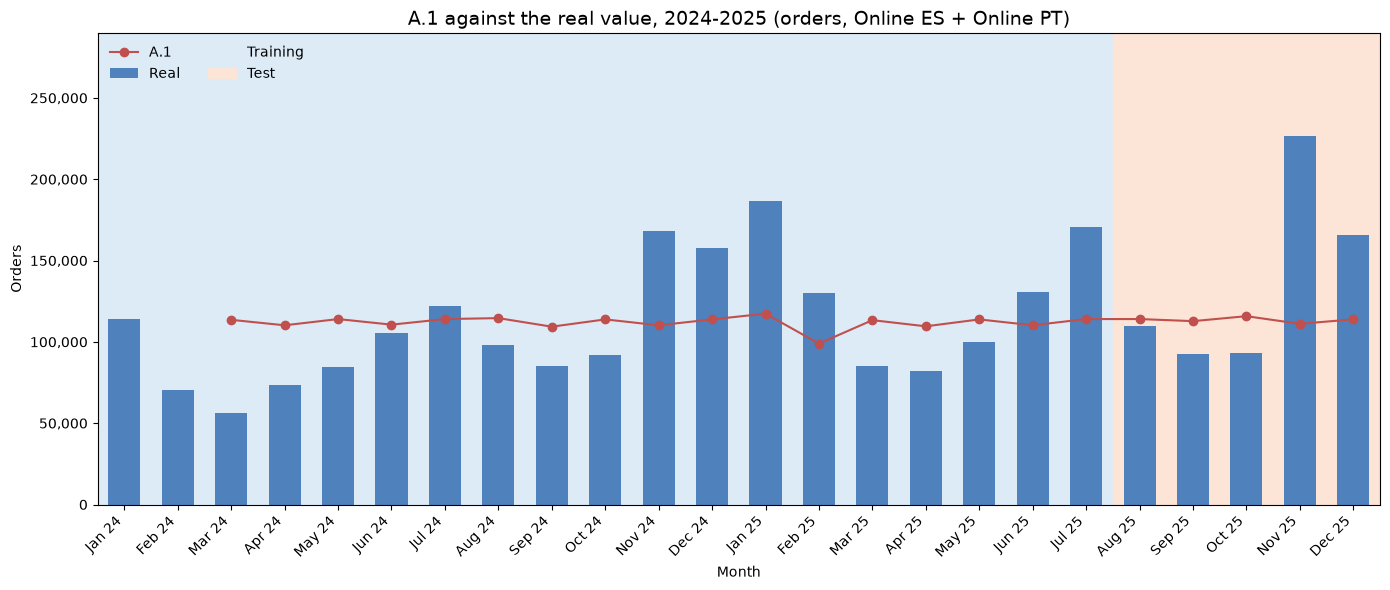

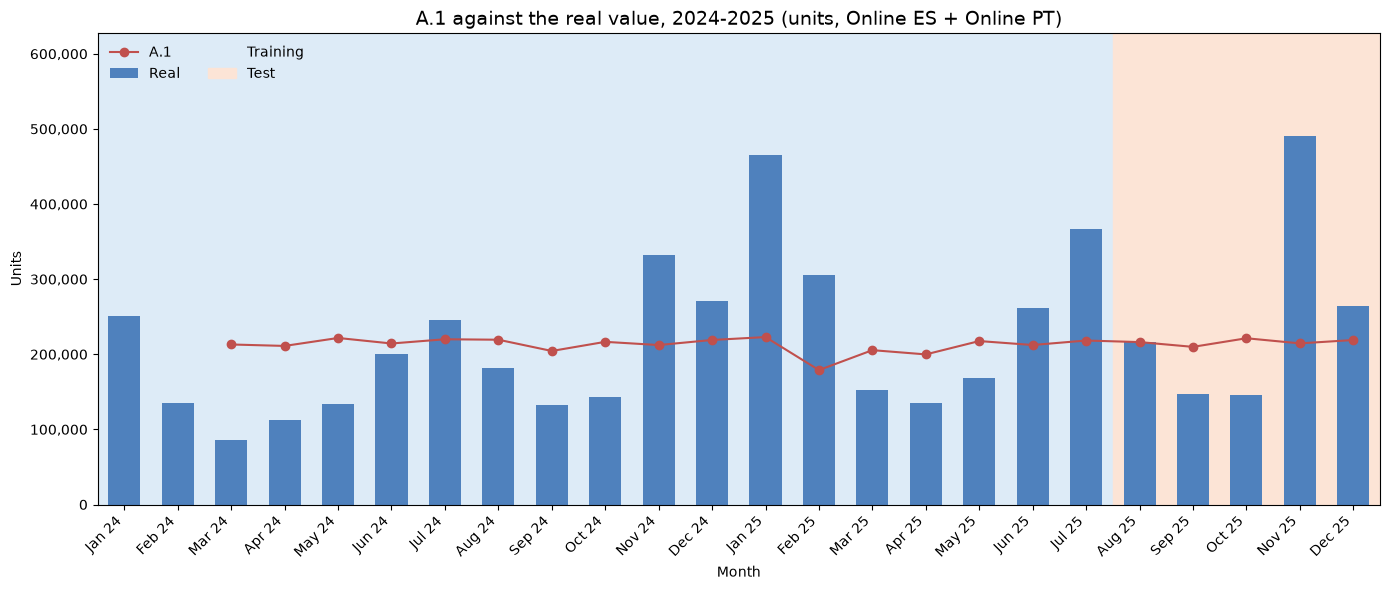

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

# ---------- Chart settings ----------
MIN_COVERAGE = 0.5      # a partly covered month is shown only if the model covers at least this share of its days
# ------------------------------------

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = it1_daily[it1_daily.index <= last_cutoff]

fitted = {}
for t in TARGETS:
    features = [f"{t}_lag_{lag}" for lag in IT1_LAGS]
    train_t = train.dropna(subset=features)
    model = LinearRegression().fit(train_t[features], train_t[t])
    fitted[t] = pd.Series(model.predict(train_t[features]), index=train_t.index)
fitted = pd.DataFrame(fitted)
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{IT1_NAME} | lags = {IT1_LAGS} | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = it1_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals (a partly covered month = daily average x days in the month, if coverage is enough)
model_mean = model_daily.resample("MS").mean()
coverage = model_daily.iloc[:, 0].resample("MS").count() / model_mean.index.days_in_month
monthly_model = model_mean.mul(model_mean.index.days_in_month, axis=0)[coverage >= MIN_COVERAGE]
tab_all = it1_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=IT1_NAME)      # NaN before the lags are available
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{IT1_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### Iteration 1: results

The model fails to capture the seasonality of the series. Its forecasts are almost flat, close to the historical average, while the actual volume has strong peaks around Black Friday, Christmas and the winter sales (November to January) and the summer sales (July), and clear troughs in spring and early autumn. An overall R² close to zero confirms that the model explains practically none of the variation: it performs no better than forecasting the average.

As a result, the error depends mainly on how far each month is from the average. August is forecast reasonably well, but only because its volume is close to the average. The quieter months, September and October, are overestimated, while the peak months, November and December, are strongly underestimated, with November showing the largest error of the test period. Units are forecast less accurately than orders because they vary more: during sales and Christmas, orders contain more items, so the peaks in units are proportionally larger.

The reason is that lags of 62 to 68 days carry little useful information for this series. Peaks and troughs alternate within a few months, so the volume two months earlier is weakly or even inversely related to the current volume, and the linear regression ends up giving little weight to the lags. The fitted values in the training period are also flat, which shows that the model is not overfitting but underfitting: it lacks the information needed to learn the pattern.

Since the peaks occur in the same months every year, they are predictable if the model is given that information. This motivates the next iterations: adding the value of the same day in the previous year (lag 364) and calendar features.

### Iteration 2: adding the value of the previous year (lag 364)

The results of iteration 1 show that the main source of error is seasonality: the volume peaks around Black Friday, Christmas and the sales periods, and these peaks occur in the same months every year. With lags of 62 to 68 days only, the model looks at the volume two months earlier, which carries little information about these peaks, so its forecasts stay close to the average.

To give the model information about the yearly pattern, the value of the target **364 days earlier** is added as an input. As 364 days correspond to exactly 52 weeks, this lag always falls on the same weekday of the previous year: a Saturday in November 2025, for example, is linked to the corresponding Saturday in November 2024. The model therefore combines two kinds of information:
- **recent level** (lags 62 to 68): the volume one week, two months earlier, as in iteration 1;
- **seasonal pattern** (lag 364): the volume on the equivalent day of the previous year.

The model still uses only past values of the series itself, so it remains a model without external features. Everything else is kept unchanged from iteration 1 – the linear regression, the forecasting rule with one month of anticipation, the test months and the metrics – so that any difference in the results can be attributed to the yearly lag alone.

**Trade-off.** As the data starts in January 2024, the yearly lag is only available from the end of December 2024. The training period therefore becomes shorter, starting at the end of 2024 instead of March 2024. The expectation is that the information about the seasonal peaks will more than compensate for the smaller amount of training data, especially in the peak months of November and December.

In [6]:
# ============================================================
# Iteration 2 (IT2) - Linear Regression with lagged values only
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Inputs: recent level (lags 62-68) + same weekday of the previous year (lag 364)
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
IT2_ID = "A.2"                                   # short name used in the result tables
IT2_NAME = "Iteration 2 (lags + yearly lag)"     # full name used in charts
IT2_RECENT_LAGS = list(range(62, 69))            # one full week, always known one month in advance
IT2_YEARLY_LAG = 364                             # 52 weeks: same weekday of the previous year
IT2_LAGS = IT2_RECENT_LAGS + [IT2_YEARLY_LAG]
TARGETS = ["orders", "units"]
TEST_MONTHS = [
    "2025-08",
    "2025-09",
    "2025-10",
    "2025-11",
    "2025-12",
]
# ----------------------------------

# 0. Check that base_ml exists (it is a temporary view, lost when the kernel restarts)
try:
    con_b.sql("SELECT 1 FROM base_ml LIMIT 1")
except Exception:
    raise RuntimeError("base_ml not found: run the cell that creates base_ml first.")

# 1. Daily series of the two targets (SALE lines only)
it2_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
it2_daily["day"] = pd.to_datetime(it2_daily["day"])
it2_daily = it2_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(it2_daily)} days, from {it2_daily.index.min().date()} to {it2_daily.index.max().date()}")

# 2. Lag features
for t in TARGETS:
    for lag in IT2_LAGS:
        it2_daily[f"{t}_lag_{lag}"] = it2_daily[t].shift(lag)

# 3. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 4. Evaluation by calendar month
it2_results, it2_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = it2_daily[it2_daily.index <= cutoff]
    test = it2_daily[(it2_daily.index >= month_start) & (it2_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(IT2_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = [f"{t}_lag_{lag}" for lag in IT2_LAGS]
        train_t = train.dropna(subset=features)    # the yearly lag is only available from 30 December 2024

        model = LinearRegression().fit(train_t[features], train_t[t])
        forecast = model.predict(test[features])
        actual = test[t].to_numpy()

        it2_results.append({
            "model": IT2_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            **error_metrics(actual, forecast),
        })
        it2_predictions.append(pd.DataFrame({
            "model": IT2_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

it2_results = pd.DataFrame(it2_results)
it2_predictions = pd.concat(it2_predictions, ignore_index=True)

# 5. Results
print("\nResults by month:")
display(it2_results)

print("Overall results (all test days pooled):")
it2_overall = pd.DataFrame([
    {"model": IT2_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in it2_predictions.groupby("target")
])
display(it2_overall)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,A.2,orders,2025-08,2025-06-30,2024-12-30,183,20.89,19.33,846.60,-0.75
1,A.2,units,2025-08,2025-06-30,2024-12-30,183,28.09,27.01,"2,243.45",-1.40
2,A.2,orders,2025-09,2025-07-31,2024-12-30,214,37.85,37.85,"1,176.30",-11.69
3,A.2,units,2025-09,2025-07-31,2024-12-30,214,57.98,57.98,"2,874.57",-34.59
4,A.2,orders,2025-10,2025-08-31,2024-12-30,245,32.27,31.97,"1,053.37",-7.68
5,A.2,units,2025-10,2025-08-31,2024-12-30,245,52.56,52.56,"2,589.17",-17.51
6,A.2,orders,2025-11,2025-09-30,2024-12-30,275,17.26,-2.84,"2,818.83",0.94
7,A.2,units,2025-11,2025-09-30,2024-12-30,275,19.68,2.45,"7,451.30",0.93
8,A.2,orders,2025-12,2025-10-31,2024-12-30,306,20.42,7.84,"1,476.54",-0.15
9,A.2,units,2025-12,2025-10-31,2024-12-30,306,36.07,27.68,"4,032.82",-2.64


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,A.2,orders,23.40,13.46,"1,625.14",0.91
1,A.2,units,32.80,24.17,"4,263.82",0.90


Iteration 2 (lags + yearly lag) | lags = [62, 63, 64, 65, 66, 67, 68, 364] | model values from 2024-12-30


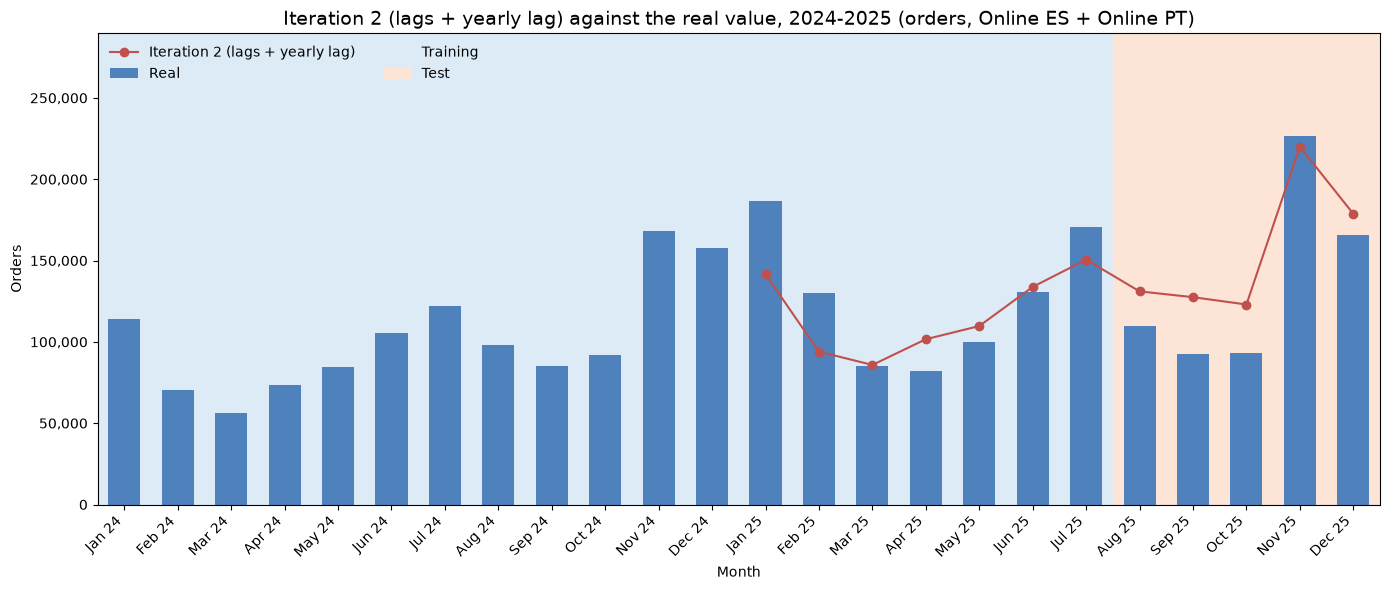

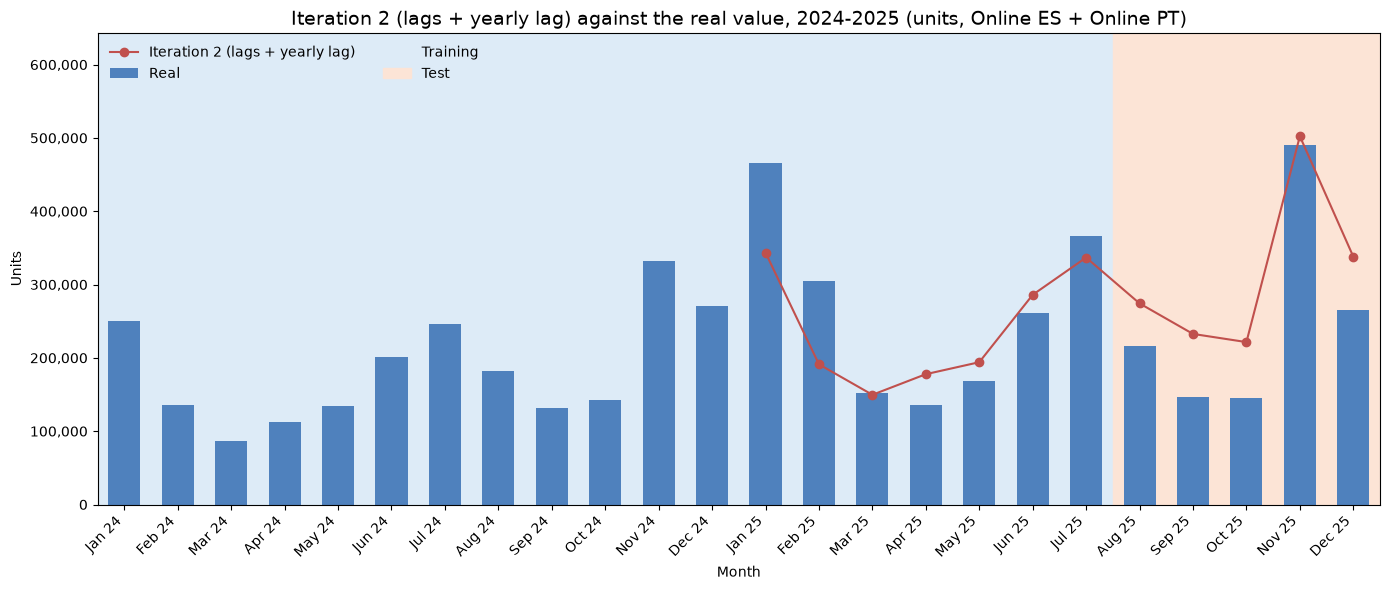

In [7]:
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

# ---------- Chart settings ----------
MIN_COVERAGE = 0.5      # a partly covered month is shown only if the model covers at least this share of its days
# ------------------------------------

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = it2_daily[it2_daily.index <= last_cutoff]

fitted = {}
for t in TARGETS:
    features = [f"{t}_lag_{lag}" for lag in IT2_LAGS]
    train_t = train.dropna(subset=features)
    model = LinearRegression().fit(train_t[features], train_t[t])
    fitted[t] = pd.Series(model.predict(train_t[features]), index=train_t.index)
fitted = pd.DataFrame(fitted)
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{IT2_NAME} | lags = {IT2_LAGS} | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = it2_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals
#    (a partly covered month is estimated as daily average x days in the month, if coverage is enough)
model_mean = model_daily.resample("MS").mean()
coverage = model_daily.iloc[:, 0].resample("MS").count() / model_mean.index.days_in_month
monthly_model = model_mean.mul(model_mean.index.days_in_month, axis=0)[coverage >= MIN_COVERAGE]
tab_all = it2_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=IT2_NAME)      # NaN before the lags are available
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{IT2_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### Iteration 2: results

Adding the value of the previous year brings a large improvement over iteration 1. The model now follows the seasonal shape of the series: the fitted values in the training period rise and fall with the actual volume, and in the test period the forecast captures the Black Friday peak in November, which was the largest source of error in iteration 1. The overall WAPE drops considerably for both targets, and the overall R² rises from close to zero to around 0.9, showing that the model now explains most of the variation between days.

The improvement, however, is not uniform across months:
- **November** is forecast very well, with almost no bias. The peak of November 2024 tells the model that November 2025 will also be a peak month.
- **August to October** are strongly overestimated. The training period starts only at the end of December 2024, because the yearly lag requires one year of history, so the model learns only from the first months of 2025. In those months, volume was clearly above the same months of 2024, especially during the winter and summer sales, and the model learns that the current year is consistently higher than the previous one. That growth did not continue in the quieter months of late summer and autumn, so the forecasts for these months are too high. The recent lags add to this effect: the forecast for September, for example, uses values from July, which were inflated by the summer sales.
- **December** is also overestimated, for the same reason, although less than the autumn months.

As a result, the overall bias changes sign: iteration 1 underestimated the volume, while iteration 2 overestimates it. For warehouse planning this means a risk of overstaffing in quieter months, rather than understaffing in peak months. Units are again less accurate than orders, as their growth between 2024 and 2025 was larger during the sales periods, which amplifies the growth the model learns.

**Note on R².** The overall R² is high mainly because the model separates the November peak from the rest of the period. Within each month, where volume varies less, R² is negative in most months, which means the model does not yet capture the day-to-day variation within a month well. WAPE and Bias therefore give a more reliable picture of the forecast quality than the overall R². This pattern is common to all the models in this notebook. For warehouse staffing, the monthly and weekly volume matters most, so this weakness has a limited impact.

**Conclusion.** The yearly lag gives the model the seasonal pattern it was missing, and this iteration is kept as the new reference. Its main weakness is the level of the forecast: with only a few months of training data, the model overestimates the growth from one year to the next. The next iterations add calendar features, which describe the seasonal pattern directly and can be learned from the whole history, instead of depending only on the value of the previous year.

### A.3: adding the average of the previous year's week

In A.2, the information about the previous year comes from a single day: the same weekday, 364 days earlier. Aligning by weekday keeps moving dates such as Black Friday aligned from one year to the next, but relying on a single day makes the forecast sensitive to whatever happened on that day: if it was atypical, because of a holiday, a one-off campaign or a technical issue, its effect is carried directly into the forecast.

A.3 tests whether looking at the whole week around that day gives the model a more stable view of the previous year. Two options were considered:
- adding the seven days around the equivalent day as separate lags (361 to 367 days);
- adding a single feature with the **average of those seven days**, while keeping the lag of 364 days.

The second option was chosen. The seven days of the previous year are strongly correlated with each other, and with a training period of only a few months, adding them as separate inputs would make the linear regression unstable and prone to overfitting. A single average reduces the influence of an atypical day while adding only one input to the model.

Everything else is kept unchanged from A.2 – the recent lags, the forecasting rule, the test months and the metrics – so that any difference in the results can be attributed to the new feature alone.

In [8]:
# ============================================================
# A.3 - Linear Regression with lagged values only
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Inputs: recent level (lags 62-68) + same weekday of the previous year (lag 364)
#         + average of the week around that day in the previous year (lags 361-367)
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
IT3_ID = "A.3"                                                   # short name used in the result tables
IT3_NAME = "A.3 Linear Regression (lags + yearly lag + yearly week mean)"   # full name used in charts
IT3_RECENT_LAGS = list(range(62, 69))            # one full week, always known one month in advance
IT3_YEARLY_LAG = 364                             # 52 weeks: same weekday of the previous year
IT3_YEARLY_WEEK = list(range(361, 368))          # week around that day in the previous year (364 +/- 3)
IT3_LAGS = IT3_RECENT_LAGS + [IT3_YEARLY_LAG]
TARGETS = ["orders", "units"]
TEST_MONTHS = [
    "2025-08",
    "2025-09",
    "2025-10",
    "2025-11",
    "2025-12",
]
# ----------------------------------

# 0. Check that base_ml exists (it is a temporary view, lost when the kernel restarts)
try:
    con_b.sql("SELECT 1 FROM base_ml LIMIT 1")
except Exception:
    raise RuntimeError("base_ml not found: run the cell that creates base_ml first.")

# 1. Daily series of the two targets (SALE lines only)
it3_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
it3_daily["day"] = pd.to_datetime(it3_daily["day"])
it3_daily = it3_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(it3_daily)} days, from {it3_daily.index.min().date()} to {it3_daily.index.max().date()}")

# 2. Features: individual lags + average of the week around the same day of the previous year
for t in TARGETS:
    for lag in IT3_LAGS:
        it3_daily[f"{t}_lag_{lag}"] = it3_daily[t].shift(lag)
    it3_daily[f"{t}_yearly_week_mean"] = pd.concat(
        [it3_daily[t].shift(lag) for lag in IT3_YEARLY_WEEK], axis=1
    ).mean(axis=1, skipna=False)        # NaN until all 7 days are available

def it3_features(t):
    return [f"{t}_lag_{lag}" for lag in IT3_LAGS] + [f"{t}_yearly_week_mean"]

# 3. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 4. Evaluation by calendar month
it3_results, it3_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = it3_daily[it3_daily.index <= cutoff]
    test = it3_daily[(it3_daily.index >= month_start) & (it3_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    shortest_lag = min(IT3_LAGS + IT3_YEARLY_WEEK)
    assert (test.index - pd.Timedelta(days=shortest_lag)).max() <= cutoff

    for t in TARGETS:
        features = it3_features(t)
        train_t = train.dropna(subset=features)    # the longest lag (367) is only available from 2 January 2025

        model = LinearRegression().fit(train_t[features], train_t[t])
        forecast = model.predict(test[features])
        actual = test[t].to_numpy()

        it3_results.append({
            "model": IT3_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            **error_metrics(actual, forecast),
        })
        it3_predictions.append(pd.DataFrame({
            "model": IT3_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

it3_results = pd.DataFrame(it3_results)
it3_predictions = pd.concat(it3_predictions, ignore_index=True)

# 5. Results
print("\nResults by month:")
display(it3_results)

print("Overall results (all test days pooled):")
it3_overall = pd.DataFrame([
    {"model": IT3_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in it3_predictions.groupby("target")
])
display(it3_overall)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,A.3,orders,2025-08,2025-06-30,2025-01-02,180,25.33,24.46,965.43,-1.27
1,A.3,units,2025-08,2025-06-30,2025-01-02,180,33.33,32.75,"2,482.80",-1.94
2,A.3,orders,2025-09,2025-07-31,2025-01-02,211,40.72,40.72,"1,269.05",-13.77
3,A.3,units,2025-09,2025-07-31,2025-01-02,211,55.09,55.09,"2,752.46",-31.63
4,A.3,orders,2025-10,2025-08-31,2025-01-02,242,31.54,31.02,"1,057.34",-7.75
5,A.3,units,2025-10,2025-08-31,2025-01-02,242,43.13,43.07,"2,260.78",-13.11
6,A.3,orders,2025-11,2025-09-30,2025-01-02,272,27.87,9.19,"3,550.79",0.90
7,A.3,units,2025-11,2025-09-30,2025-01-02,272,34.26,14.97,"10,931.56",0.86
8,A.3,orders,2025-12,2025-10-31,2025-01-02,303,32.20,26.96,"2,183.38",-1.51
9,A.3,units,2025-12,2025-10-31,2025-01-02,303,54.52,52.77,"6,197.81",-7.60


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,A.3,orders,30.73,23.11,"2,041.86",0.85
1,A.3,units,41.79,33.84,"5,914.75",0.81


A.3 Linear Regression (lags + yearly lag + yearly week mean) | features = ['orders_lag_62', 'orders_lag_63', 'orders_lag_64', 'orders_lag_65', 'orders_lag_66', 'orders_lag_67', 'orders_lag_68', 'orders_lag_364', 'orders_yearly_week_mean'] | model values from 2025-01-02


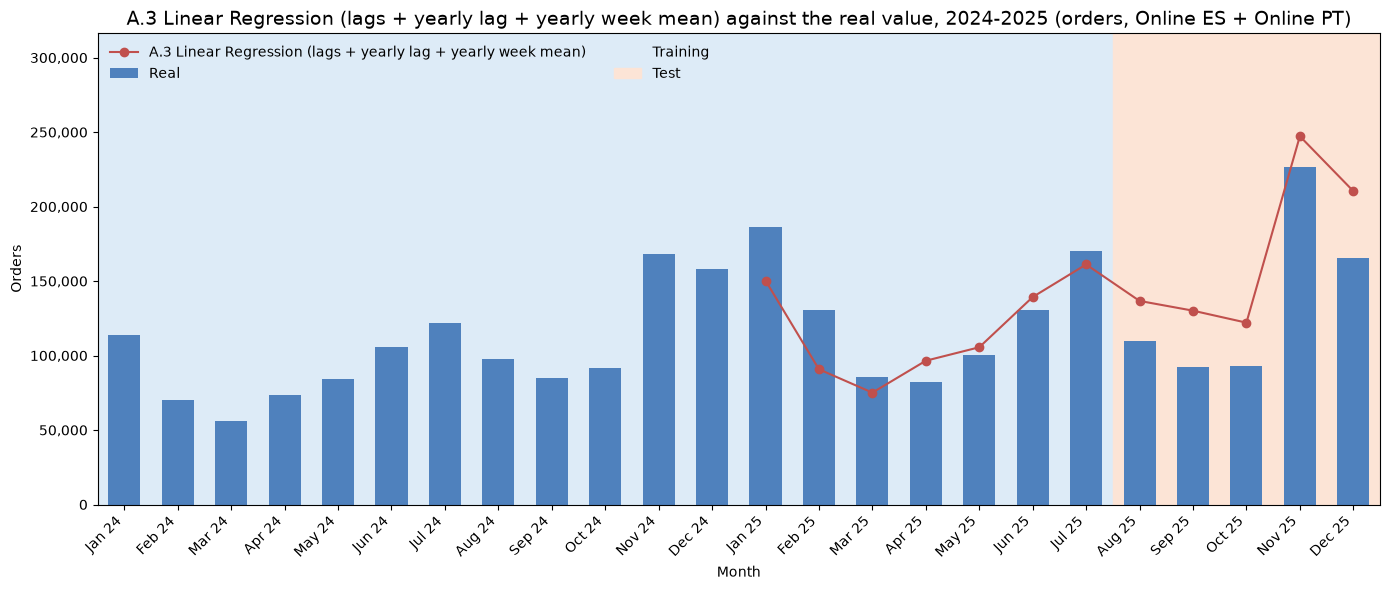

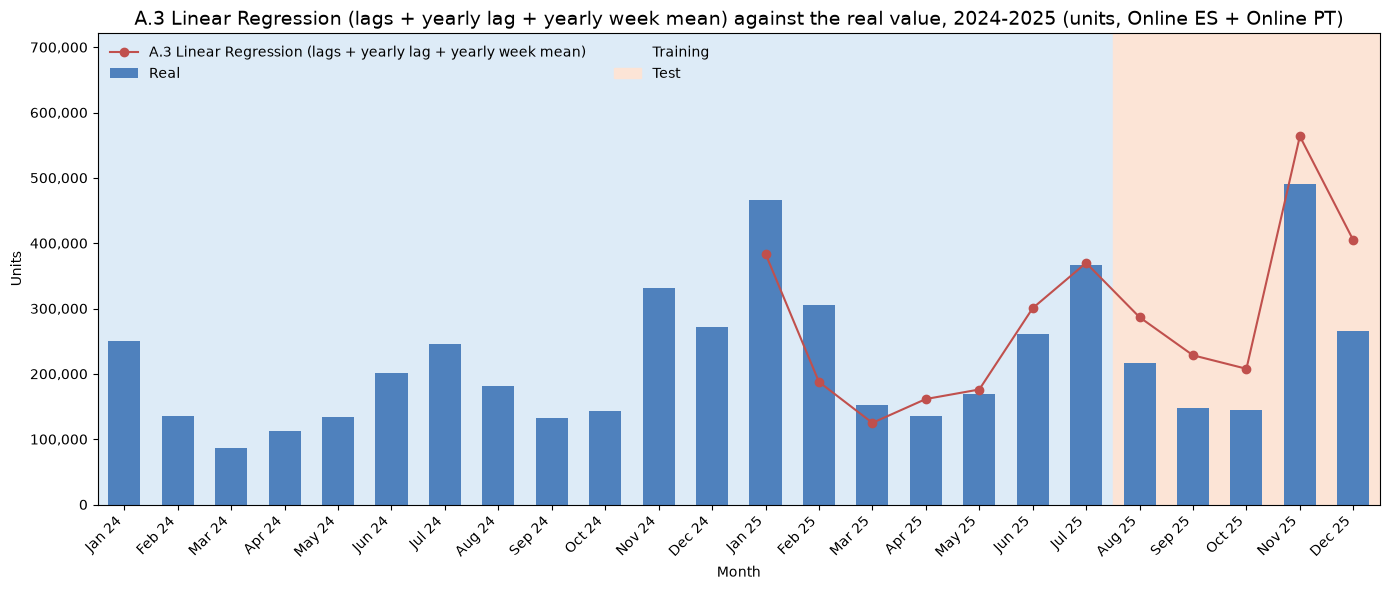

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

# ---------- Chart settings ----------
MIN_COVERAGE = 0.5      # a partly covered month is shown only if the model covers at least this share of its days
# ------------------------------------

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = it3_daily[it3_daily.index <= last_cutoff]

fitted = {}
for t in TARGETS:
    features = it3_features(t)
    train_t = train.dropna(subset=features)
    model = LinearRegression().fit(train_t[features], train_t[t])
    fitted[t] = pd.Series(model.predict(train_t[features]), index=train_t.index)
fitted = pd.DataFrame(fitted)
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{IT3_NAME} | features = {it3_features(TARGETS[0])} | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = it3_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals
#    (a partly covered month is estimated as daily average x days in the month, if coverage is enough)
model_mean = model_daily.resample("MS").mean()
coverage = model_daily.iloc[:, 0].resample("MS").count() / model_mean.index.days_in_month
monthly_model = model_mean.mul(model_mean.index.days_in_month, axis=0)[coverage >= MIN_COVERAGE]
tab_all = it3_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=IT3_NAME)      # NaN before the lags are available
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{IT3_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### A.3: results

Adding the average of the week around the equivalent day of the previous year does not improve the model. Compared with A.2, the overall WAPE and bias increase for both targets and R² decreases. The only month that improves is October; the peak months, November and December, become clearly worse, with the forecast now overshooting the actual volume.

The chart can give the opposite impression, because the fitted values in the training period follow the actual volume more closely than in A.2. This is the typical sign of overfitting: the model fits the training data better but forecasts unseen months worse.

The likely cause is that the new feature carries almost the same information as the yearly lag, as both describe the previous year. With a short training period, made up only of months in 2025 in which volume was well above 2024, the linear regression gives even more weight to "previous year multiplied by growth". In the peak months this effect is amplified, which explains the overestimation in November and December.

**Conclusion.** A.3 is discarded and A.2 remains the reference model of this section. The result suggests that, with the limited history available, adding more information about the previous year does not help; the main weakness of the model is the level of the forecast rather than the lack of seasonal information.

### A.4: calendar features only

Models A.1 to A.3 rely on past values of the series. A.2 showed that information from the previous year is essential to capture the seasonal peaks, but it also revealed a limitation: because the yearly lag requires one year of history, the model can only be trained from the end of December 2024. As a result, it never sees a November or a December during training and has only a few months from which to learn how the volume evolves.

A.4 tests a different approach: instead of past values, the model receives only the **structure of the calendar**, which is known in advance for any future date. Three groups of features are used:
- **day of the week** (one 0/1 column per day, with Monday as the reference): the model learns the typical effect of each weekday from all the days in the training period, instead of relying on a single day as the lags do;
- **month** (one 0/1 column per month, with January as the reference): the model learns the typical level of each month, which captures the seasonal peaks;
- **trend** (number of days since the start of the data): the model learns the overall growth of sales over time.

Since no lags are used, the model can be trained on all the data available up to each cutoff date, starting in January 2024. This means that, when forecasting November 2025, the model has already seen November 2024.

This approach has its own limitations. Each month is learned from very few examples – in most cases a single occurrence – and the trend is a straight line, so the model assumes that growth continues at the same pace. In addition, the effects are additive: the extra volume of a peak month is assumed to be the same number of orders or units, regardless of the overall level of sales.

The forecasting rule, test months and metrics are the same as in the previous models. Comparing A.4 with A.2 shows whether it is more useful to give the model the history of the series or the structure of the calendar.

In [10]:
# ============================================================
# A.4 - Linear Regression with calendar features only (no lags)
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Inputs: day of the week + month + linear trend
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
IT4_ID = "A.4"                                              # short name used in the result tables
IT4_NAME = "A.4 Linear Regression (calendar only)"         # full name used in charts
TARGETS = ["orders", "units"]
TEST_MONTHS = [
    "2025-08",
    "2025-09",
    "2025-10",
    "2025-11",
    "2025-12",
]
# ----------------------------------

# 0. Check that base_ml exists (it is a temporary view, lost when the kernel restarts)
try:
    con_b.sql("SELECT 1 FROM base_ml LIMIT 1")
except Exception:
    raise RuntimeError("base_ml not found: run the cell that creates base_ml first.")

# 1. Daily series of the two targets (SALE lines only)
it4_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
it4_daily["day"] = pd.to_datetime(it4_daily["day"])
it4_daily = it4_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(it4_daily)} days, from {it4_daily.index.min().date()} to {it4_daily.index.max().date()}")

# 2. Calendar features: known in advance for any date, so they can be used for any horizon
#    One-hot encoding (one 0/1 column per category); Monday and January are the reference
idx = it4_daily.index
dow = pd.get_dummies(idx.dayofweek, prefix="dow", drop_first=True).astype(int)
month_dummies = pd.get_dummies(idx.month, prefix="month", drop_first=True).astype(int)
calendar = pd.concat([dow, month_dummies], axis=1).set_index(idx)
calendar["trend"] = (idx - idx.min()).days                # days since the start of the data
it4_daily = it4_daily.join(calendar)
IT4_FEATURES = list(calendar.columns)
print(f"Features ({len(IT4_FEATURES)}): {IT4_FEATURES}")

# 3. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 4. Evaluation by calendar month
it4_results, it4_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = it4_daily[it4_daily.index <= cutoff]
    test = it4_daily[(it4_daily.index >= month_start) & (it4_daily.index <= month_end)]

    # leakage check: the model is trained only on days up to the cutoff
    assert train.index.max() <= cutoff

    for t in TARGETS:
        model = LinearRegression().fit(train[IT4_FEATURES], train[t])
        forecast = model.predict(test[IT4_FEATURES])
        actual = test[t].to_numpy()

        it4_results.append({
            "model": IT4_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train.index.min().date(),
            "train_days": len(train),
            **error_metrics(actual, forecast),
        })
        it4_predictions.append(pd.DataFrame({
            "model": IT4_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

it4_results = pd.DataFrame(it4_results)
it4_predictions = pd.concat(it4_predictions, ignore_index=True)

# 5. Results
print("\nResults by month:")
display(it4_results)

print("Overall results (all test days pooled):")
it4_overall = pd.DataFrame([
    {"model": IT4_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in it4_predictions.groupby("target")
])
display(it4_overall)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31
Features (18): ['dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'trend']

Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,A.4,orders,2025-08,2025-06-30,2024-01-01,547,23.61,22.39,976.44,-1.33
1,A.4,units,2025-08,2025-06-30,2024-01-01,547,32.19,30.06,"2,521.87",-2.03
2,A.4,orders,2025-09,2025-07-31,2024-01-01,578,33.07,33.07,"1,071.43",-9.53
3,A.4,units,2025-09,2025-07-31,2024-01-01,578,57.43,57.43,"2,904.22",-35.32
4,A.4,orders,2025-10,2025-08-31,2024-01-01,609,36.60,36.60,"1,182.13",-9.93
5,A.4,units,2025-10,2025-08-31,2024-01-01,609,63.59,63.59,"3,101.93",-25.57
6,A.4,orders,2025-11,2025-09-30,2024-01-01,639,91.02,-12.16,"11,137.70",0.00
7,A.4,units,2025-11,2025-09-30,2024-01-01,639,107.39,-15.49,"28,948.36",0.00
8,A.4,orders,2025-12,2025-10-31,2024-01-01,670,23.85,13.21,"1,633.89",-0.41
9,A.4,units,2025-12,2025-10-31,2024-01-01,670,33.57,31.72,"3,555.45",-1.83


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,A.4,orders,48.90,12.16,"5,056.23",0.09
1,A.4,units,68.21,19.78,"13,106.04",0.07


A.4 Linear Regression (calendar only) | 18 calendar features | model values from 2024-01-01


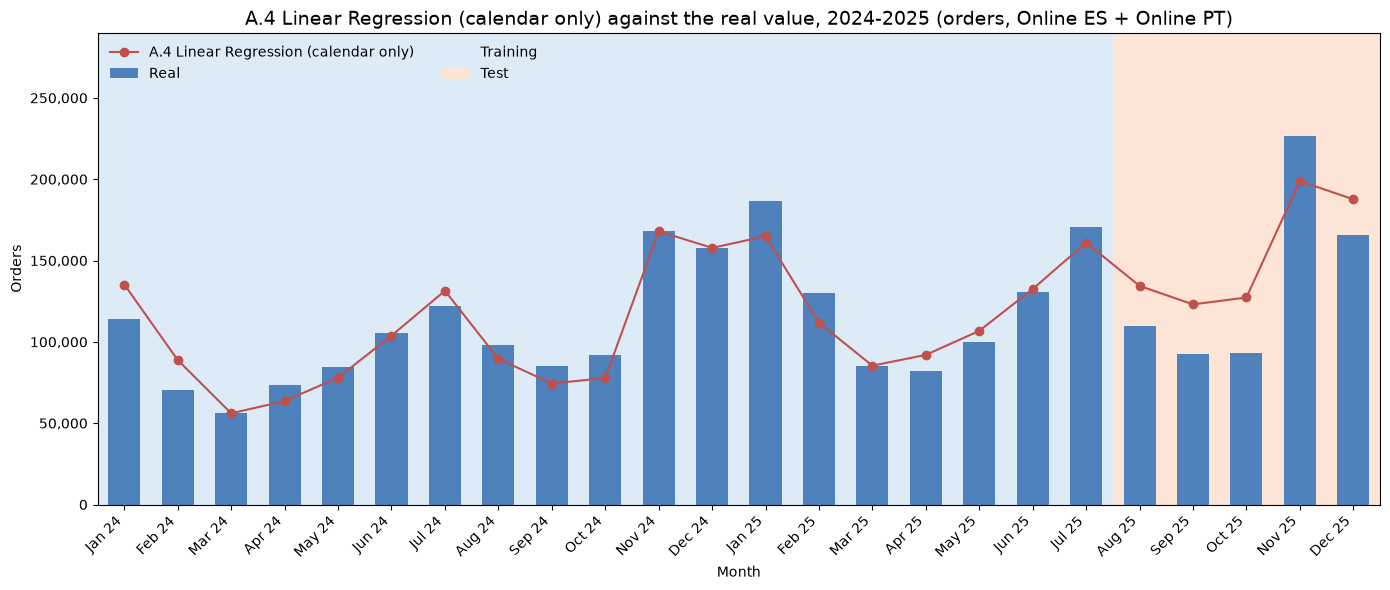

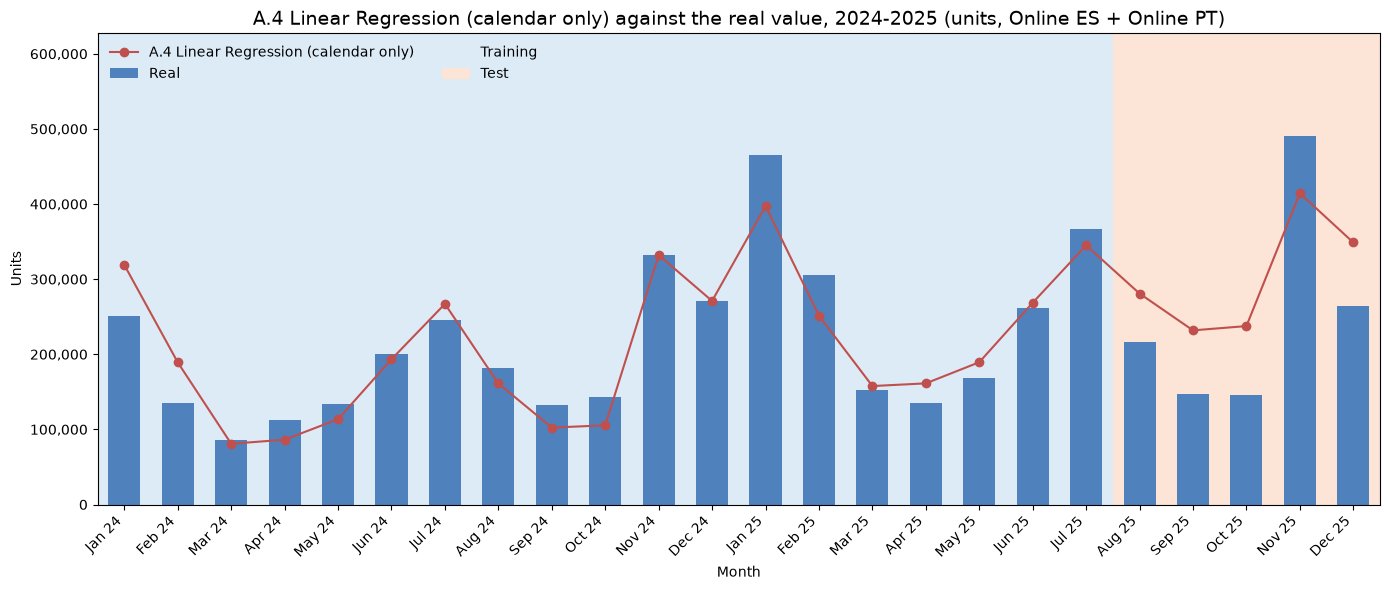

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = it4_daily[it4_daily.index <= last_cutoff]

fitted = pd.DataFrame(index=train.index)
for t in TARGETS:
    model = LinearRegression().fit(train[IT4_FEATURES], train[t])
    fitted[t] = model.predict(train[IT4_FEATURES])
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{IT4_NAME} | {len(IT4_FEATURES)} calendar features | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = it4_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals
monthly_model = model_daily.resample("MS").sum()
tab_all = it4_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=IT4_NAME)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{IT4_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### A.4: results

| Model | WAPE orders | WAPE units | Bias orders | Bias units | R² orders | R² units |
|---|---|---|---|---|---|---|
| A.1 – lags 62–68 | 38.5% | 50.5% | -17.5% | -14.5% | -0.02 | 0.00 |
| A.2 – lags 62–68 + lag 364 | 23.4% | 32.8% | +13.5% | +24.2% | 0.91 | 0.90 |
| A.4 – calendar only | 48.9% | 68.2% | +12.2% | +19.8% | 0.09 | 0.07 |

A.4 captures the seasonal shape of the series at monthly level – the peaks from November to January and in July, and the quieter months in spring and autumn – which A.1 could not. However, it is the least accurate of the three models on a daily basis.

November explains most of this result. The forecast total for the month is reasonably close to the actual volume, but the daily errors are very large. The month feature adds the same amount to every day of November, while in reality the volume is concentrated in the Black Friday week. The model therefore overestimates the ordinary days of the month and strongly underestimates the peak days. A.2 does not have this problem, because the yearly lag links each day to the equivalent day of the previous year, so the Black Friday peak of 2024 is carried to the same days in 2025.

Compared with A.1, A.4 is worse in almost every month: besides spreading the November peak, it overestimates the volume from August to October. A.2 shows the same overestimation in these months, for the same reason: the model extends the strong growth of the first half of 2025 to months in which it did not continue, which in A.4 comes from the linear trend. The close fit in the training period should not be read as a good result, as each month effect is learned from the same months it is then compared with.

**Conclusion.** A.2 remains the reference model of this section. A.4 shows that a monthly calendar is not enough for this business: the peaks happen on specific days, such as Black Friday and the start of the sales periods, rather than across the whole month. This points to day-level event features as the next step, rather than month indicators.

In [12]:
# Events in scope (PT and ES): how names are written, how often they repeat, and how long they last
events_scope = con_b.sql(f"""
    SELECT CAST(Event AS VARCHAR) AS event,
           UPPER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) AS market,
           TRY_CAST(Start_date AS DATE) AS start_date,
           TRY_CAST(End_date AS DATE) AS end_date,
           DATE_DIFF('day', TRY_CAST(Start_date AS DATE), TRY_CAST(End_date AS DATE)) + 1 AS n_days
    FROM {ev_src}
    WHERE LOWER(TRIM(CAST("{COL_EV_MARKET}" AS VARCHAR))) IN ({markets_sql})
    ORDER BY start_date, market, event
""").df()

print("1. Distinct event names (how often each appears, in which markets and years):")
summary = (events_scope
           .assign(year=pd.to_datetime(events_scope["start_date"]).dt.year)
           .groupby("event")
           .agg(n_records=("event", "size"),
                markets=("market", lambda s: ", ".join(sorted(s.unique()))),
                years=("year", lambda s: ", ".join(str(y) for y in sorted(s.unique()))),
                avg_days=("n_days", "mean"))
           .sort_values("n_records", ascending=False))
print(f"   {len(summary)} distinct names in {len(events_scope)} records")
display(summary)

print("2. All event records in scope, in date order:")
display(events_scope)

1. Distinct event names (how often each appears, in which markets and years):
   22 distinct names in 106 records


,n_records,markets,years,avg_days
event,,,,
Stock 1,26,"ONLINE ES, ONLINE PT",2025,4.00
Clearance,8,"ONLINE ES, ONLINE PT","2024, 2025",62.00
Free Shipping,8,"ONLINE ES, ONLINE PT","2024, 2025",1.75
Get your basket ready,8,"ONLINE ES, ONLINE PT","2024, 2025",1.00
Black Friday Web + App 20% all + 50% selected,4,"ONLINE ES, ONLINE PT","2024, 2025",1.00
Black Friday App 20% all + 50% selected,4,"ONLINE ES, ONLINE PT","2024, 2025",2.00
Special Prices FW,4,"ONLINE ES, ONLINE PT",2024,24.50
Easter Weeks,4,"ONLINE ES, ONLINE PT","2024, 2025",17.00
Black Friday Get your basket ready,4,"ONLINE ES, ONLINE PT","2024, 2025",2.00


2. All event records in scope, in date order:


,event,market,start_date,end_date,n_days
0,Clearance,ONLINE PT,2024-01-01,2024-02-28,59
1,Get your basket ready,ONLINE ES,2024-01-05,2024-01-05,1
2,Clearance,ONLINE ES,2024-01-06,2024-02-28,54
3,Last Days Valentines,ONLINE ES,2024-02-06,2024-02-09,4
4,Last Days Valentines,ONLINE PT,2024-02-06,2024-02-09,4
5,Last Hours Valentines,ONLINE ES,2024-02-08,2024-02-09,2
6,Last Hours Valentines,ONLINE PT,2024-02-08,2024-02-09,2
7,Easter Weeks,ONLINE ES,2024-03-16,2024-04-01,17
8,Easter Weeks,ONLINE PT,2024-03-16,2024-04-01,17
9,Free Shipping,ONLINE ES,2024-03-23,2024-03-24,2


## 3. Features/Target definition

### What the simple models showed
The simple machine learning models (section A) used only past values of the series or only the calendar. They led to three conclusions that guide the choice of features:
- **The previous year is essential.** Adding the value of the same weekday in the previous year (A.2) was the largest improvement, because it allows the model to anticipate the seasonal peaks.
- **The peaks happen on specific days, not across whole months.** A monthly calendar alone (A.4) captured the seasonal shape, but spread the Black Friday peak over the whole of November. The model needs to know *which days* are special.
- **More of the same information does not help.** Adding a second feature describing the previous year (A.3) led to overfitting, given the short training period.

This section therefore adds information that the series itself does not contain: the structure of the week and the fixed commercial dates of the year.

### Level of the series
The forecast is made for **daily totals of Portugal and Spain combined**, rather than one series per market. Both markets are served by the same warehouse, so their combined volume is what determines the staff needed. A single series is also simpler to model and is easier to compare with the baseline, which is built at the same level.

### Why two targets
Warehouse workload has two components:
- **Orders** – each order must be packed, labelled and shipped, so the number of orders drives the packing and shipping effort.
- **Units** – each item must be picked from the shelves, so the number of items drives the picking effort.

The two are related but not equivalent: a day with many single-item orders requires different staffing from a day with the same number of orders containing several items each. Forecasting both gives a more complete estimate of the staff needed.

### Handling transaction types
`base_ml` contains three transaction types: `SALE`, `RETURN` and `CANCELLED`. Only `SALE` lines are used to build the targets.

The model is intended to run on live data, forecasting the number of orders and units for the coming days so that staffing can be planned in advance. At the moment an order is placed, only the sale is known: cancellations and returns, if any, are recorded later. If they were subtracted from the target, the value of a past day would keep changing for weeks as they arrive, and the recent values the model uses as inputs in production would not be final. Counting only `SALE` lines gives a target that is complete at the end of each day and that matches what the model sees both in training and in production.

Returns are also not picking work, and `base_ml` dates them by the original `ORDER_DATE` rather than by the day they reach the warehouse. Excluding cancellations means the target slightly overstates the workload, as cancelled items are not shipped. Since cancellations are marginal in the data, this is an acceptable trade-off for a stable target. Handling cancelled orders in the warehouse (stopping their preparation once a cancellation is received) is an operational process and is outside the scope of this model.

### Final targets

| Target | Definition |
|---|---|
| **Orders** | Number of distinct `ORDER_ID` per day with at least one `SALE` line |
| **Units** | Sum of `PROD_QTY` over `SALE` lines per day |

### Features to be added
Under the forecasting rule defined in section A, every feature must be **known at the time of the forecast**, two months before the forecast month. Both groups below meet this condition, as they depend only on the calendar: the days of the week and the dates of the campaigns in September are already known at the end of July.

**1. Calendar: day of the week.** One indicator per day of the week (with Monday as the reference). The model learns the typical effect of each weekday from all the days in the training period, instead of relying on a single past day, as the lags do.

The month is not added as a feature. A.4 showed that a month indicator adds the same amount to every day of the month, which spreads short peaks such as Black Friday over the whole month. In addition, the yearly lag requires one year of history, so the training period starts only at the end of December 2024 and contains no November: a November indicator would have no examples to learn from. The behaviour specific to each month is captured in two other ways:
- the **yearly lag** carries the level of the same period in the previous year day by day, so the model knows, for example, that November is usually higher than the surrounding months;
- the **campaign features** below identify the days within the month on which the peaks occur.

**2. Campaigns.** Only campaigns tied to a date in the calendar are used, as these repeat every year and can be anticipated: **Black Friday, Christmas, Mothers Day, Reyes, Valentines, and Easter and Holy Week**. Some fall on the same date every year, while others follow a calendar rule, such as Easter or the last Friday of November. Each campaign is represented by an indicator that is active on the days of the campaign.

The campaigns are taken from the `events` table, grouped into families with the same rules used in the baseline (see `events_grouped_v` in Section 2), so that the different phases of a campaign, such as "Last Days" and "Last Hours", count as a single campaign. As the model forecasts the total of both markets, a campaign is considered active on a day if it is active in at least one of them; Reyes, for example, only applies to Spain.

All other events are excluded, as their dates are not tied to the calendar and are set by the company each year: sales periods (`Clearance`), special prices, free shipping, stock promotions and "Get your basket ready". The Iberian blackout of April 2025 is also excluded, as it was not planned and could not have been known in advance.

### Approach
Following the incremental approach of section A, the features are added **one group at a time**, on top of the best simple model (A.2), and each new model is evaluated on the same test months and metrics. A group of features is kept only if it improves on the previous model, which makes it possible to measure the contribution of each group separately.

### Other candidate features

The following groups of features could be evaluated in future work. Each one would be kept only if it is known at the time of the forecast and improves the results on the test months.

| Group | Candidates | Notes |
|---|---|---|
| Product category | `CAT_DES_EN` as a feature, with one row per day and category group | Units only; based on the category analysis. Orders are not split by category |
| Recent growth | Ratio between the volume of the last weeks before the cutoff and the same weeks of the previous year | Addresses the overestimation seen in the simple models, which assume the growth of early 2025 continues |
| Campaign proximity | Days before the start and after the end of each campaign; last delivery day before Christmas | Peaks build up before campaigns and drop afterwards |
| Holidays | National holidays in Portugal and Spain, days before and after a holiday, bridge days | Not in the `events` table; can be counted separately for each country or combined |
| Paydays | Indicator for the end and start of the month | Common pattern in online retail; known in advance |
| Collection launches | Start dates of new collections | Useful only if planned and shared in advance |
| Other commercial actions | Sales periods, special prices, free shipping, stock promotions | Excluded for now, as their dates are not tied to the calendar; useful only if the company can provide them in advance |
| Paid media | Daily investment | Useful only if the future budget is known at the time of the forecast |

## B. Machine learning models with features

### B.1: A.2 + day of the week + fixed campaigns

B.1 starts from the best simple model, A.2, and adds the two groups of features defined in Section 3: the **day of the week** and the **fixed campaigns** (Black Friday, Christmas, Mothers Day, Reyes, Valentines, and Easter and Holy Week). The targets, the forecasting rule, the test months and the metrics are the same as in section A.

**Inputs.** The model receives:
- the values of the target 62 to 68 days earlier (recent level), as in A.2;
- the value of the same weekday in the previous year (lag 364), as in A.2;
- six indicators for the day of the week, with Monday as the reference;
- one feature for each of the six campaigns, describing how the campaign calendar on that day differs from the previous year (see below).

**Campaigns relative to the previous year.** The yearly lag already carries last year's campaign peaks to the equivalent days. For a campaign that falls on the same days every year, such as Black Friday, the model therefore already knows that a peak is coming, and a simple "campaign active" indicator would add the same peak a second time. To avoid this overlap, each campaign feature compares the day being forecast with the equivalent day of the previous year (364 days earlier):
- **+1** if the campaign is active on the day but was not active on the equivalent day of the previous year;
- **-1** if it was active on the equivalent day of the previous year but is not active on the day;
- **0** if the situation is the same in both years.

In this way, campaigns that keep their position in the calendar add nothing beyond the yearly lag, while campaigns that move from one year to the next, such as Easter, correct the yearly lag where it points to the wrong days.

**Training period.** In A.2, the yearly lag requires one year of history, so training only started at the end of December 2024, and Black Friday 2024 and Christmas 2024 never appeared in the training data. B.1 is also trained on 2024: on days without a previous year, the yearly lag is set to 0 and an additional indicator, `no_yearly_lag`, is set to 1, so that the model knows the information is missing. Consistently, the previous year's campaign calendar is also treated as empty on those days, so the campaign features show the full campaign. This allows the model to learn the size of each campaign from 2024, and to apply it in 2025 only where the campaign calendar differs from the previous year. Training starts on 9 March 2024, the first day with all the recent lags available.

**Comparison with A.2.** B.1 differs from A.2 in two ways: the new features and the longer training period. Both changes are needed for the campaign features to be learned, so the comparison with A.2 measures their combined effect.

In [13]:
# ============================================================
# B.1 - Linear Regression: A.2 inputs + day of the week + fixed campaigns
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Inputs: recent level (lags 62-68) + same weekday of the previous year (lag 364)
#         + day of the week + fixed campaigns relative to the previous year
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
B1_ID = "B.1"                                                         # short name used in the result tables
B1_NAME = "B.1 Linear Regression (A.2 + day of the week + campaigns vs last year)"  # full name used in charts
B1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
B1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
B1_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
b1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
b1_daily["day"] = pd.to_datetime(b1_daily["day"])
b1_daily = b1_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(b1_daily)} days, from {b1_daily.index.min().date()} to {b1_daily.index.max().date()}")

# 2. Lag features
#    The yearly lag does not exist for days in 2024 (no previous year in the data).
#    It is set to 0 and flagged with no_yearly_lag = 1, so that 2024 can be used for training:
#    the model learns the weight of the yearly lag from 2025 and the other effects from the whole period.
for t in TARGETS:
    for lag in B1_RECENT_LAGS:
        b1_daily[f"{t}_lag_{lag}"] = b1_daily[t].shift(lag)
    yearly = b1_daily[t].shift(B1_YEARLY_LAG)
    b1_daily[f"{t}_lag_{B1_YEARLY_LAG}"] = yearly.fillna(0)
b1_daily["no_yearly_lag"] = b1_daily[TARGETS[0]].shift(B1_YEARLY_LAG).isna().astype(int)

# 3. Calendar feature: day of the week (one-hot, Monday is the reference)
dow = pd.get_dummies(b1_daily.index.dayofweek, prefix="dow", drop_first=True).astype(int)
dow.index = b1_daily.index
b1_daily = b1_daily.join(dow)
B1_DOW = list(dow.columns)

# 4. Campaign features, relative to the previous year
#    For each campaign: active(day) - active(same weekday of the previous year, 364 days earlier).
#    +1 = campaign today but not on the equivalent day last year; -1 = the opposite; 0 = same situation.
#    The yearly lag already carries last year's campaign peaks, so the feature only adds the difference
#    and a campaign on the same days in both years is not counted twice.
#    Days in 2024 have no previous year in the data: last year's campaign is set to 0, consistent with
#    the yearly lag set to 0, so on those days the feature shows the full campaign.
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=b1_daily.index, columns=list(B1_CAMPAIGNS.values()))
for family, col in B1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_last_year = camp_active.shift(B1_YEARLY_LAG).fillna(0).astype(int)
camp_diff = (camp_active - camp_last_year).add_suffix("_vs_ly")
b1_daily = b1_daily.join(camp_diff)
B1_CAMP = list(camp_diff.columns)

print("\nCampaign days (active, by year) and 2025 days where the campaign differs from the previous year:")
camp_check = camp_active.groupby(camp_active.index.year).sum().T
diff_2025 = camp_diff[camp_diff.index.year == 2025]
camp_check["2025_days_+1"] = (diff_2025 == 1).sum().values
camp_check["2025_days_-1"] = (diff_2025 == -1).sum().values
display(camp_check.rename_axis("campaign"))

def b1_features(t):
    return ([f"{t}_lag_{lag}" for lag in B1_RECENT_LAGS]
            + [f"{t}_lag_{B1_YEARLY_LAG}", "no_yearly_lag"]
            + B1_DOW + B1_CAMP)

# 5. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 6. Evaluation by calendar month
b1_results, b1_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = b1_daily[b1_daily.index <= cutoff]
    test = b1_daily[(b1_daily.index >= month_start) & (b1_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(B1_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = b1_features(t)
        train_t = train.dropna(subset=features)    # recent lags are available from 9 March 2024

        model = LinearRegression().fit(train_t[features], train_t[t])
        forecast = model.predict(test[features])
        actual = test[t].to_numpy()

        b1_results.append({
            "model": B1_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            **error_metrics(actual, forecast),
        })
        b1_predictions.append(pd.DataFrame({
            "model": B1_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

b1_results = pd.DataFrame(b1_results)
b1_predictions = pd.concat(b1_predictions, ignore_index=True)

# 7. Results
print("\nResults by month:")
display(b1_results)

print("Overall results (all test days pooled):")
b1_overall = pd.DataFrame([
    {"model": B1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in b1_predictions.groupby("target")
])
display(b1_overall)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days (active, by year) and 2025 days where the campaign differs from the previous year:


day,2024,2025,2025_days_+1,2025_days_-1
campaign,,,,
camp_black_friday,3,3,0,0
camp_christmas,4,4,2,2
camp_mothers_day,3,6,3,0
camp_reyes,4,6,2,1
camp_valentines,4,3,3,4
camp_easter_holy_week,17,17,17,17



Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,B.1,orders,2025-08,2025-06-30,2024-03-09,479,21.79,19.73,927.17,-1.10
1,B.1,units,2025-08,2025-06-30,2024-03-09,479,30.56,29.41,"2,503.15",-1.98
2,B.1,orders,2025-09,2025-07-31,2024-03-09,510,36.45,36.45,"1,156.80",-11.28
3,B.1,units,2025-09,2025-07-31,2024-03-09,510,52.79,52.79,"2,666.11",-29.61
4,B.1,orders,2025-10,2025-08-31,2024-03-09,541,32.88,32.60,"1,079.46",-8.12
5,B.1,units,2025-10,2025-08-31,2024-03-09,541,55.04,55.04,"2,685.72",-18.92
6,B.1,orders,2025-11,2025-09-30,2024-03-09,571,16.87,-2.79,"2,786.65",0.94
7,B.1,units,2025-11,2025-09-30,2024-03-09,571,20.34,2.42,"7,582.34",0.93
8,B.1,orders,2025-12,2025-10-31,2024-03-09,602,21.46,7.75,"1,502.66",-0.19
9,B.1,units,2025-12,2025-10-31,2024-03-09,602,36.27,29.35,"4,127.10",-2.82


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,B.1,orders,23.57,13.42,"1,628.74",0.91
1,B.1,units,33.20,24.60,"4,341.52",0.90


B.1 Linear Regression (A.2 + day of the week + campaigns vs last year) | 21 features | model values from 2024-03-09


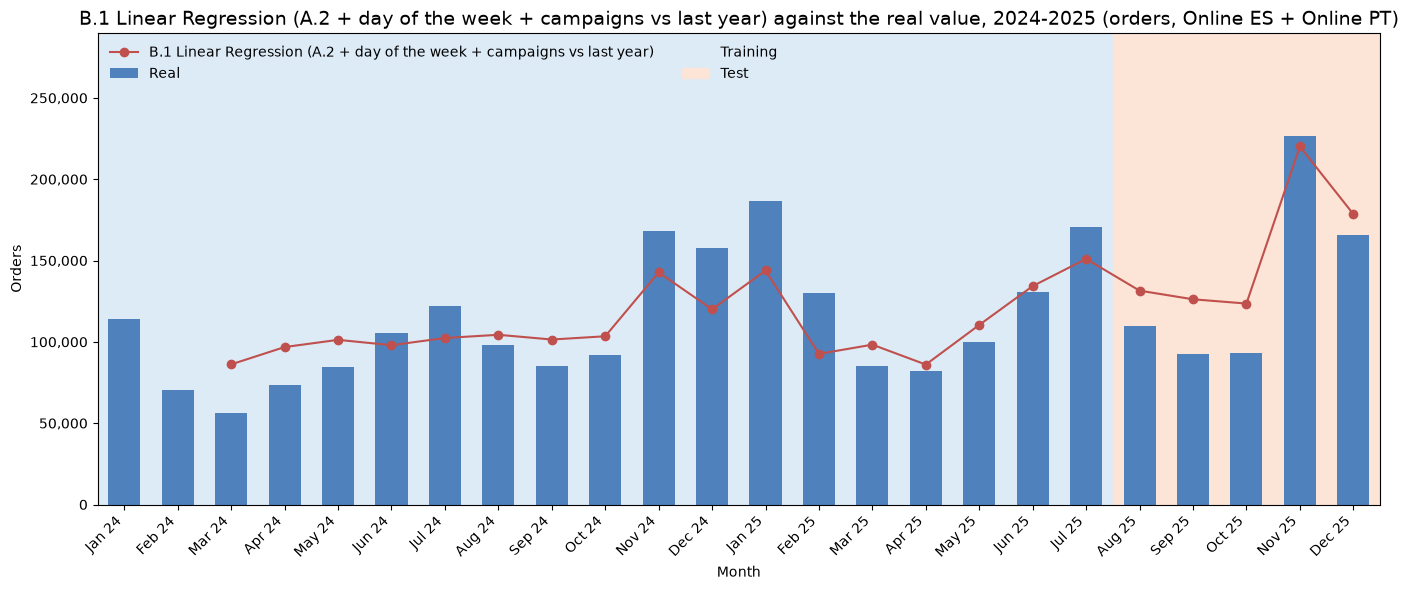

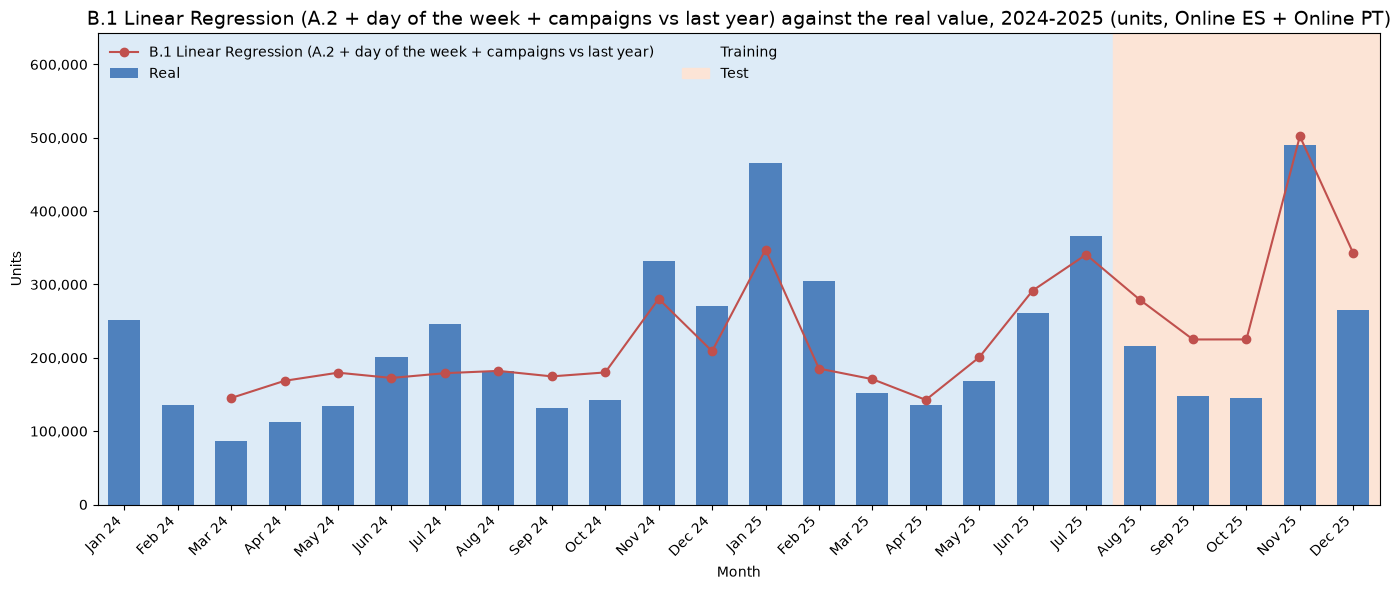

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

# ---------- Chart settings ----------
MIN_COVERAGE = 0.5      # a partly covered month is shown only if the model covers at least this share of its days
# ------------------------------------

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = b1_daily[b1_daily.index <= last_cutoff]

fitted = {}
for t in TARGETS:
    features = b1_features(t)
    train_t = train.dropna(subset=features)
    model = LinearRegression().fit(train_t[features], train_t[t])
    fitted[t] = pd.Series(model.predict(train_t[features]), index=train_t.index)
fitted = pd.DataFrame(fitted)
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{B1_NAME} | {len(b1_features(TARGETS[0]))} features | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = b1_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals
#    (a partly covered month is estimated as daily average x days in the month, if coverage is enough)
model_mean = model_daily.resample("MS").mean()
coverage = model_daily.iloc[:, 0].resample("MS").count() / model_mean.index.days_in_month
monthly_model = model_mean.mul(model_mean.index.days_in_month, axis=0)[coverage >= MIN_COVERAGE]
tab_all = b1_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=B1_NAME)      # NaN before the lags are available
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{B1_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### B.1: results

B.1 does not improve on A.2. The overall metrics are practically the same for both targets, with small gains in some months and small losses in others.

This does not mean that the campaign features fail. The effect of each campaign is carried to the correct days of the following year: the yearly lag brings the values of the equivalent days of the previous year, which already include last year's campaign, and the campaign features only correct the few days at the edges of each campaign where the calendar does not align exactly – for example, Christmas 2025 started and ended one day later than Christmas 2024. For campaigns tied to a weekday, such as Black Friday, the alignment is exact and the feature is zero. Because the yearly lag already does most of the work, and A.2 already included it, the campaign features change the forecast on only a few days of the test period. The campaigns that move most from one year to the next, such as Easter, take place between January and May, outside the test months. The day of the week also adds little information, as the lags of 63 and 364 days already fall on the same weekday.

November is forecast accurately because the yearly lag brings a clean picture of the previous year: Black Friday took place in both years, and no other commercial action affected November 2024 only. December includes Christmas, which is handled in the same way, but it is overestimated, as are August to October. The likely cause is that these months were also affected by commercial actions that took place in 2024 but were not repeated in 2025. A special prices campaign ran from late September to the end of October 2024 and again from 12 to 25 December 2024, but not in 2025. The yearly lag carries these higher 2024 values into the forecast, and without knowing that the campaign did not happen again, the model overestimates those months. Conversely, the stock promotions run every two weeks in 2025 did not exist in 2024.

**Conclusion.** Following the rule defined for this section, B.1 is not kept as the new reference, as it adds complexity without improving the results in the months evaluated; A.2 remains the reference model. The design of the campaign features, relative to the previous year, is nevertheless kept for the following models, as it places each campaign on the correct days, including campaigns that change dates. The results suggest that much of the remaining error is caused not by the level of the forecast, but by differences in the commercial calendar between the two years, which motivates adding the remaining events in the next model.

### Other commercial actions

As seen in B.1, part of the remaining error comes from commercial actions that took place in one year but not in the other. These actions are not included as features: they are decided by the company each year and, with only two years of data, each appears only once or twice, with no pattern from which the model could learn when they will happen again.

The model therefore relies on the yearly lag, which implicitly assumes that the previous year's commercial calendar is repeated. When the company changes it, the forecast will be too high (a campaign is not repeated) or too low (a new campaign is added). This is the main limitation of the current approach. In production, it could be addressed by providing the commercial plan as an input – for example, through fields in a dashboard where the user indicates the planned campaigns and their dates. The model would then only need to estimate the effect of each campaign family, which can be learned from its past occurrences, rather than guess whether it will take place.

A longer history, as available in the client's environment, would also reduce several of these limitations: campaign effects and seasonality would be learned from many more occurrences, and more complex models would become a realistic option. It would not, however, anticipate changes in the commercial plan, and older data may reflect a different business, so the training period may need to focus on recent years.

### B.2: B.1 + public holidays + paydays

B.2 extends B.1 with two further groups of calendar features: **public holidays** and **paydays**. Both are known in advance, so they can be used for a forecast made two months ahead. Everything else is kept unchanged from B.1 – the lags, the day of the week, the fixed campaigns, the training period, the forecasting rule, the test months and the metrics – so that any difference in the results can be attributed to the new features.

**Public holidays.** The holidays are taken from the Nager.Date public API, loaded into the data lake by the `nager_date_to_bronze` pipeline. Only **national** holidays of Portugal and Spain are used, with one indicator per country, as each market has its own holidays and they affect a different share of the volume. Regional holidays, which in Spain vary by autonomous community, are excluded, as they only affect part of the market.

Some holidays fall within a fixed campaign – for example, Good Friday falls within Easter and Holy Week. On those days, the effect is left to the campaign feature and the holiday indicator is set to 0, so that the same day is not explained by two overlapping features.

**Paydays.** Most salaries in Portugal and Spain are paid at the end of the month, which can increase online orders around that time. A payday indicator is set to 1 from day 25 of each month to day 5 of the following month.

**Relative to the previous year.** Holidays and paydays are described relative to the previous year, with the same +1 / -1 / 0 design as the campaigns in B.1. Holidays such as Christmas Day or All Saints' Day fall on the same date every year but on a different weekday, so the yearly lag carries last year's holiday effect to a day that is one day off. These features correct those days, without counting the effect twice where the yearly lag already places it correctly. For days in 2024, which have no previous year in the data, the previous year is treated as having no holidays or paydays, consistently with the yearly lag.

In [15]:
# ============================================================
# B.2 - Linear Regression: B.1 inputs + public holidays + paydays
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Inputs: recent level (lags 62-68) + same weekday of the previous year (lag 364)
#         + day of the week + fixed campaigns + national holidays (PT, ES) + paydays,
#         campaigns, holidays and paydays relative to the previous year
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
B2_ID = "B.2"                                                                      # short name used in the result tables
B2_NAME = "B.2 Linear Regression (B.1 + holidays + paydays)"                       # full name used in charts
B2_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
B2_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
B2_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
B2_HOLIDAY_COUNTRIES = {"PT": "hol_pt", "ES": "hol_es"}   # national holidays only
B2_PAYDAY_FROM, B2_PAYDAY_TO = 25, 5                      # paydays: from day 25 to day 5 of the following month
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
b2_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
b2_daily["day"] = pd.to_datetime(b2_daily["day"])
b2_daily = b2_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(b2_daily)} days, from {b2_daily.index.min().date()} to {b2_daily.index.max().date()}")

# 2. Lag features (as in B.1)
#    The yearly lag does not exist for days in 2024: it is set to 0 and flagged with no_yearly_lag = 1.
for t in TARGETS:
    for lag in B2_RECENT_LAGS:
        b2_daily[f"{t}_lag_{lag}"] = b2_daily[t].shift(lag)
    b2_daily[f"{t}_lag_{B2_YEARLY_LAG}"] = b2_daily[t].shift(B2_YEARLY_LAG).fillna(0)
b2_daily["no_yearly_lag"] = b2_daily[TARGETS[0]].shift(B2_YEARLY_LAG).isna().astype(int)

# 3. Calendar feature: day of the week (one-hot, Monday is the reference)
dow = pd.get_dummies(b2_daily.index.dayofweek, prefix="dow", drop_first=True).astype(int)
dow.index = b2_daily.index
b2_daily = b2_daily.join(dow)
B2_DOW = list(dow.columns)

# 4. Calendar events active on each day (0/1), before comparing with the previous year
#    4a. Fixed campaigns, active if active in at least one market in scope
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=b2_daily.index, columns=list(B2_CAMPAIGNS.values()))
for family, col in B2_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1

#    4b. National public holidays per country, from the Nager.Date API (bronze layer, latest load only)
hol_path = lake.uri("bronze", "nager_date/public_holidays/**/*.parquet")
holidays = con_b.sql(f"""
    SELECT holiday_date, country
    FROM (
        SELECT TRY_CAST("date" AS DATE) AS holiday_date,
               countryCode AS country,
               "global" AS is_national,
               ROW_NUMBER() OVER (PARTITION BY countryCode, "date", name
                                  ORDER BY ingestion_date DESC) AS rn
        FROM read_parquet('{hol_path}', hive_partitioning = true, union_by_name = true)
        WHERE countryCode IN ({", ".join("'" + c + "'" for c in B2_HOLIDAY_COUNTRIES)})
    )
    WHERE rn = 1 AND is_national
""").df()
hol_active = pd.DataFrame(0, index=b2_daily.index, columns=list(B2_HOLIDAY_COUNTRIES.values()))
for country, col in B2_HOLIDAY_COUNTRIES.items():
    days = pd.to_datetime(holidays.loc[holidays["country"] == country, "holiday_date"])
    hol_active.loc[hol_active.index.isin(days), col] = 1

#    Holidays that fall inside a fixed campaign (e.g. Good Friday within Easter and Holy Week) are left
#    to the campaign feature, so the same day is not explained twice by two overlapping features.
in_campaign = camp_active.max(axis=1) == 1
hol_overlap = hol_active[in_campaign].sum()
hol_active.loc[in_campaign, :] = 0

#    4c. Paydays: from day 25 to day 5 of the following month
payday_active = pd.DataFrame(
    {"payday": ((b2_daily.index.day >= B2_PAYDAY_FROM) | (b2_daily.index.day <= B2_PAYDAY_TO)).astype(int)},
    index=b2_daily.index,
)

# 5. Features relative to the previous year (same design as the campaigns in B.1)
#    value(day) - value(same weekday of the previous year, 364 days earlier): +1 / -1 / 0.
#    The yearly lag already carries last year's effect, so only the difference is added.
#    Days in 2024 have no previous year in the data: last year's value is set to 0, consistent with the yearly lag.
calendar_active = pd.concat([camp_active, hol_active, payday_active], axis=1)
calendar_diff = (calendar_active - calendar_active.shift(B2_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
b2_daily = b2_daily.join(calendar_diff)
B2_CAMP = [f"{c}_vs_ly" for c in B2_CAMPAIGNS.values()]
B2_HOL = [f"{c}_vs_ly" for c in B2_HOLIDAY_COUNTRIES.values()]
B2_PAY = ["payday_vs_ly"]

print("\nCalendar days (active, by year) and 2025 days that differ from the previous year:")
check = calendar_active.groupby(calendar_active.index.year).sum().T
diff_2025 = calendar_diff[calendar_diff.index.year == 2025]
check["2025_days_+1"] = (diff_2025 == 1).sum().values
check["2025_days_-1"] = (diff_2025 == -1).sum().values
display(check.rename_axis("feature"))
print("Holiday days removed because they fall inside a fixed campaign:")
display(hol_overlap.rename("days").to_frame())

def b2_features(t):
    return ([f"{t}_lag_{lag}" for lag in B2_RECENT_LAGS]
            + [f"{t}_lag_{B2_YEARLY_LAG}", "no_yearly_lag"]
            + B2_DOW + B2_CAMP + B2_HOL + B2_PAY)

# 6. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 7. Evaluation by calendar month
b2_results, b2_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = b2_daily[b2_daily.index <= cutoff]
    test = b2_daily[(b2_daily.index >= month_start) & (b2_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(B2_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = b2_features(t)
        train_t = train.dropna(subset=features)    # recent lags are available from 9 March 2024

        model = LinearRegression().fit(train_t[features], train_t[t])
        forecast = model.predict(test[features])
        actual = test[t].to_numpy()

        b2_results.append({
            "model": B2_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            **error_metrics(actual, forecast),
        })
        b2_predictions.append(pd.DataFrame({
            "model": B2_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

b2_results = pd.DataFrame(b2_results)
b2_predictions = pd.concat(b2_predictions, ignore_index=True)

# 8. Results
print("\nResults by month:")
display(b2_results)

print("Overall results (all test days pooled):")
b2_overall = pd.DataFrame([
    {"model": B2_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in b2_predictions.groupby("target")
])
display(b2_overall)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Calendar days (active, by year) and 2025 days that differ from the previous year:


day,2024,2025,2025_days_+1,2025_days_-1
feature,,,,
camp_black_friday,3,3,0,0
camp_christmas,4,4,2,2
camp_mothers_day,3,6,3,0
camp_reyes,4,6,2,1
camp_valentines,4,3,3,4
camp_easter_holy_week,17,17,17,17
hol_pt,12,10,10,11
hol_es,9,8,8,8
payday,138,137,14,14


Holiday days removed because they fall inside a fixed campaign:


,days
hol_pt,6
hol_es,3



Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,B.2,orders,2025-08,2025-06-30,2024-03-09,479,23.73,20.13,"1,047.52",-1.68
1,B.2,units,2025-08,2025-06-30,2024-03-09,479,34.80,30.21,"2,956.79",-3.16
2,B.2,orders,2025-09,2025-07-31,2024-03-09,510,35.85,35.85,"1,148.96",-11.11
3,B.2,units,2025-09,2025-07-31,2024-03-09,510,51.80,51.80,"2,634.02",-28.88
4,B.2,orders,2025-10,2025-08-31,2024-03-09,541,35.28,32.15,"1,117.58",-8.77
5,B.2,units,2025-10,2025-08-31,2024-03-09,541,60.59,53.05,"2,983.77",-23.59
6,B.2,orders,2025-11,2025-09-30,2024-03-09,571,17.56,-2.55,"2,861.45",0.93
7,B.2,units,2025-11,2025-09-30,2024-03-09,571,21.62,3.74,"7,715.15",0.93
8,B.2,orders,2025-12,2025-10-31,2024-03-09,602,22.81,7.31,"1,602.45",-0.35
9,B.2,units,2025-12,2025-10-31,2024-03-09,602,39.92,29.30,"4,554.80",-3.65


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,B.2,orders,24.67,13.32,"1,691.15",0.90
1,B.2,units,35.70,24.89,"4,561.84",0.89


B.2 Linear Regression (B.1 + holidays + paydays) | 24 features | model values from 2024-03-09


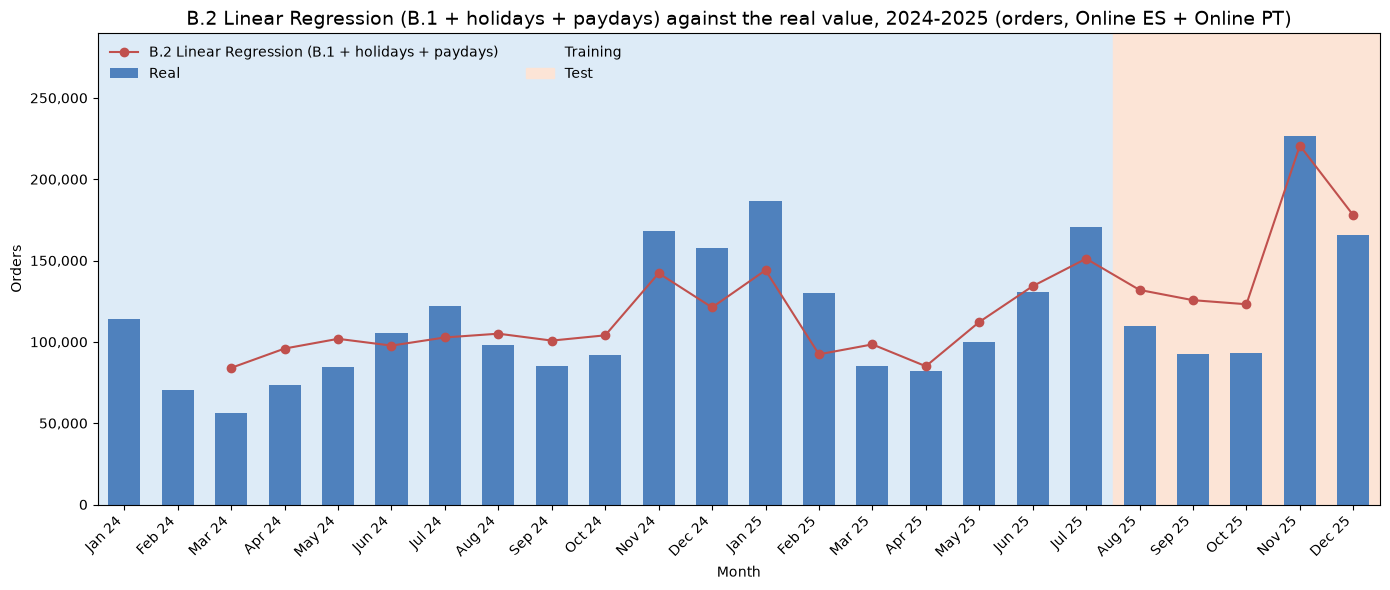

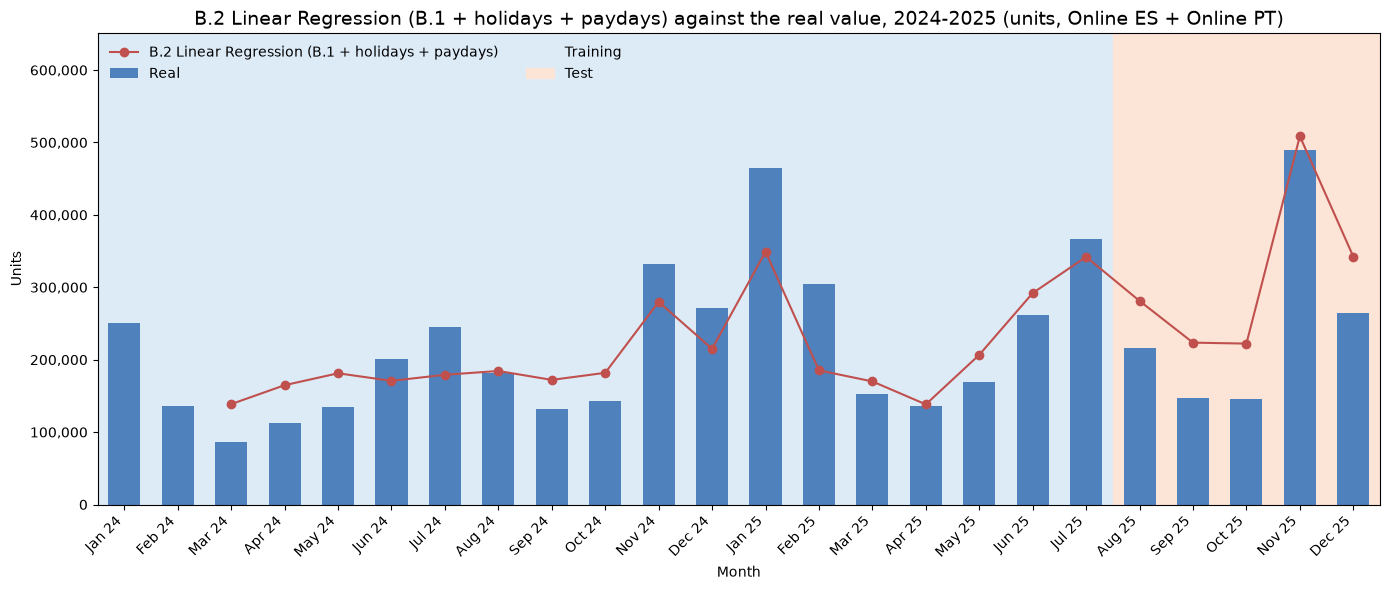

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression

# ---------- Chart settings ----------
MIN_COVERAGE = 0.5      # a partly covered month is shown only if the model covers at least this share of its days
# ------------------------------------

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = b2_daily[b2_daily.index <= last_cutoff]

fitted = {}
for t in TARGETS:
    features = b2_features(t)
    train_t = train.dropna(subset=features)
    model = LinearRegression().fit(train_t[features], train_t[t])
    fitted[t] = pd.Series(model.predict(train_t[features]), index=train_t.index)
fitted = pd.DataFrame(fitted)
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{B2_NAME} | {len(b2_features(TARGETS[0]))} features | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = b2_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals
#    (a partly covered month is estimated as daily average x days in the month, if coverage is enough)
model_mean = model_daily.resample("MS").mean()
coverage = model_daily.iloc[:, 0].resample("MS").count() / model_mean.index.days_in_month
monthly_model = model_mean.mul(model_mean.index.days_in_month, axis=0)[coverage >= MIN_COVERAGE]
tab_all = b2_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=B2_NAME)      # NaN before the lags are available
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{B2_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### Section B: conclusion

The results of sections A and B lead to a clear conclusion: **the yearly lag already captures most of the behaviour that the calendar features could add**. A.2 showed that the value of the same weekday in the previous year is the most important input for this series. B.1 and B.2 then added the day of the week, the fixed campaigns, the national holidays of Portugal and Spain and the paydays, but none of them improved the forecast. These events repeat every year on the same days, or very close to them, so their effect is already contained in the previous year's values that the yearly lag carries to the equivalent days. The features only differed from zero on a few days of the test period, and adding them introduced some noise into the model.

The yearly lag is therefore kept as the main way of capturing the calendar effects and **A.2 remains the reference model**.

The weakness that remains is the one discussed in "Other commercial actions": the yearly lag assumes that the previous year's commercial calendar is repeated. This cannot be solved with calendar information, but could be addressed by letting the user indicate the planned campaigns in a dashboard, which B.3 tests.

### B.3: scenario – a campaign indicated in advance

As proposed in "Other commercial actions", in production the user could indicate the planned campaigns in a dashboard, so that the model adjusts the forecast where the commercial plan differs from the previous year. B.3 tests this idea with a scenario: **two stock promotions are indicated for October 2025**, from 9 to 12 October and from 23 to 26 October, in both markets.

**Model.** B.3 is A.2 with one additional feature: the planned campaign, described relative to the previous year with the same +1 / -1 / 0 design as in B.1. Everything else – the lags, the training period, the forecasting rule, the test months and the metrics – is the same as in A.2, so the difference between the two models measures only the effect of indicating the campaign.

**How the campaign is used.** During training, the feature uses the actual dates of the stock promotions in the history. Several of them took place in 2025 before October, so the model can learn their effect. In the test months, the model only knows the campaigns entered in the plan, exactly as it would if a user had entered them in the dashboard. In this scenario, the plan only contains the two October promotions; in the other test months no campaign is indicated, so the model assumes there is none.

**Interpretation.** This is a scenario, not a production model: it assumes that the commercial plan for October was known at the end of August, when the October forecast is made. Its purpose is to estimate how much the forecast would improve if planned campaigns were provided as an input. The main comparison is therefore with A.2 in October; the other months are shown for completeness.

In [17]:
# ============================================================
# B.3 - Scenario: A.2 + a campaign indicated in advance by the user (planned campaign)
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Inputs: recent level (lags 62-68) + same weekday of the previous year (lag 364)
#         + planned campaign feature, relative to the previous year
# Training: actual campaign days from the events table (history)
# Test months: only the campaigns entered in PLANNED_CAMPAIGNS (as a user would in the dashboard)
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. October 2025 -> data up to 31 August 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
B3_ID = "B.3"                                                              # short name used in the result tables
B3_NAME = "B.3 Scenario: A.2 + planned campaign (Stock 1 in October)"      # full name used in charts
B3_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
B3_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
B3_FAMILY = "Stock 1"                     # campaign family used in this scenario (as in events_grouped_v)
B3_FEATURE = "camp_stock_vs_ly"

# Campaigns planned for the test months, as the user would enter them in the dashboard.
# Only these campaigns are known to the model in the test months.
PLANNED_CAMPAIGNS = [
    {"family": "Stock 1", "start": "2025-10-09", "end": "2025-10-12", "markets": ["ONLINE PT", "ONLINE ES"]},
    {"family": "Stock 1", "start": "2025-10-23", "end": "2025-10-26", "markets": ["ONLINE PT", "ONLINE ES"]},
]
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
b3_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
b3_daily["day"] = pd.to_datetime(b3_daily["day"])
b3_daily = b3_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(b3_daily)} days, from {b3_daily.index.min().date()} to {b3_daily.index.max().date()}")

# 2. Lag features (as in A.2)
for t in TARGETS:
    for lag in B3_RECENT_LAGS + [B3_YEARLY_LAG]:
        b3_daily[f"{t}_lag_{lag}"] = b3_daily[t].shift(lag)

# 3. Campaign feature
#    3a. History: actual campaign days of the family (active in at least one market in scope)
camp = con_b.sql(f"""
    SELECT start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql}) AND campaign = '{B3_FAMILY}'
""").df()
hist_active = pd.Series(0, index=b3_daily.index)
for _, row in camp.iterrows():
    hist_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"])] = 1

#    3b. Plan: campaigns entered by the user for the test months
plan_active = pd.Series(0, index=b3_daily.index)
for c in PLANNED_CAMPAIGNS:
    if c["family"] == B3_FAMILY:
        plan_active.loc[pd.Timestamp(c["start"]):pd.Timestamp(c["end"])] = 1

#    3c. Relative to the previous year (same design as in section B): this year - same weekday last year.
#        Last year always comes from the history, which is known at the time of the forecast.
last_year = hist_active.shift(B3_YEARLY_LAG).fillna(0)
b3_daily[f"{B3_FEATURE}_hist"] = hist_active - last_year     # used for training
b3_daily[f"{B3_FEATURE}_plan"] = plan_active - last_year     # used in the test months

print(f"\n{B3_FAMILY}: campaign days in the history (by year):")
display(hist_active.groupby(hist_active.index.year).sum().rename("days").to_frame())
print(f"{B3_FAMILY}: days entered in the plan, by test month:")
display(plan_active[plan_active == 1].groupby(plan_active[plan_active == 1].index.strftime("%Y-%m"))
        .size().rename("planned_days").to_frame())

def b3_features(t):
    return [f"{t}_lag_{lag}" for lag in B3_RECENT_LAGS + [B3_YEARLY_LAG]] + [B3_FEATURE]

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Evaluation by calendar month
b3_results, b3_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    # training uses the actual campaign history; the test month uses only the planned campaigns
    train = b3_daily[b3_daily.index <= cutoff].assign(**{B3_FEATURE: lambda d: d[f"{B3_FEATURE}_hist"]})
    test = b3_daily[(b3_daily.index >= month_start) & (b3_daily.index <= month_end)] \
               .assign(**{B3_FEATURE: lambda d: d[f"{B3_FEATURE}_plan"]})

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(B3_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = b3_features(t)
        train_t = train.dropna(subset=features)    # the yearly lag is only available from 30 December 2024

        model = LinearRegression().fit(train_t[features], train_t[t])
        forecast = model.predict(test[features])
        actual = test[t].to_numpy()

        b3_results.append({
            "model": B3_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "planned_days": int((test[B3_FEATURE] != 0).sum()),
            **error_metrics(actual, forecast),
        })
        b3_predictions.append(pd.DataFrame({
            "model": B3_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

b3_results = pd.DataFrame(b3_results)
b3_predictions = pd.concat(b3_predictions, ignore_index=True)

# 6. Results
print("\nResults by month:")
display(b3_results)

print("Overall results (all test days pooled):")
b3_overall = pd.DataFrame([
    {"model": B3_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in b3_predictions.groupby("target")
])
display(b3_overall)

# 7. Comparison with A.2 in the months with planned campaigns (requires the A.2 cell to have run)
planned_months = sorted(b3_results.loc[b3_results["planned_days"] > 0, "month"].unique())
try:
    comparison = pd.concat([it2_results, b3_results])
    comparison = comparison[comparison["month"].isin(planned_months)]
    print(f"Months with planned campaigns ({', '.join(planned_months)}): A.2 vs {B3_ID}")
    display(comparison.pivot_table(index=["target", "month"], columns="model",
                                   values=["WAPE_pct", "Bias_pct", "RMSE"]).round(2))
except NameError:
    print("Run the A.2 cell first to see the comparison with A.2.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Stock 1: campaign days in the history (by year):


,days
day,
2024,0
2025,52


Stock 1: days entered in the plan, by test month:


,planned_days
day,
2025-10,8



Results by month:


,model,target,month,data_up_to,train_from,train_days,planned_days,WAPE_pct,Bias_pct,RMSE,R2
0,B.3,orders,2025-08,2025-06-30,2024-12-30,183,0,20.92,19.38,847.79,-0.75
1,B.3,units,2025-08,2025-06-30,2024-12-30,183,0,28.37,27.47,"2,267.49",-1.45
2,B.3,orders,2025-09,2025-07-31,2024-12-30,214,0,37.57,37.57,"1,167.85",-11.51
3,B.3,units,2025-09,2025-07-31,2024-12-30,214,0,58.10,58.10,"2,880.21",-34.73
4,B.3,orders,2025-10,2025-08-31,2024-12-30,245,8,32.05,31.77,"1,051.31",-7.65
5,B.3,units,2025-10,2025-08-31,2024-12-30,245,8,51.68,51.68,"2,570.06",-17.24
6,B.3,orders,2025-11,2025-09-30,2024-12-30,275,0,17.57,-2.77,"2,841.61",0.94
7,B.3,units,2025-11,2025-09-30,2024-12-30,275,0,19.93,2.61,"7,485.48",0.93
8,B.3,orders,2025-12,2025-10-31,2024-12-30,306,0,20.49,8.06,"1,476.11",-0.15
9,B.3,units,2025-12,2025-10-31,2024-12-30,306,0,36.37,28.28,"4,054.01",-2.68


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,B.3,orders,23.46,13.48,"1,631.49",0.90
1,B.3,units,32.92,24.35,"4,280.58",0.90


Months with planned campaigns (2025-10): A.2 vs B.3


Bias_pct           RMSE          WAPE_pct      
model               A.2   B.3      A.2      B.3      A.2   B.3
target month                                                  
orders 2025-10    31.97 31.77 1,053.37 1,051.31    32.27 32.05
units  2025-10    52.56 51.68 2,589.17 2,570.06    52.56 51.68

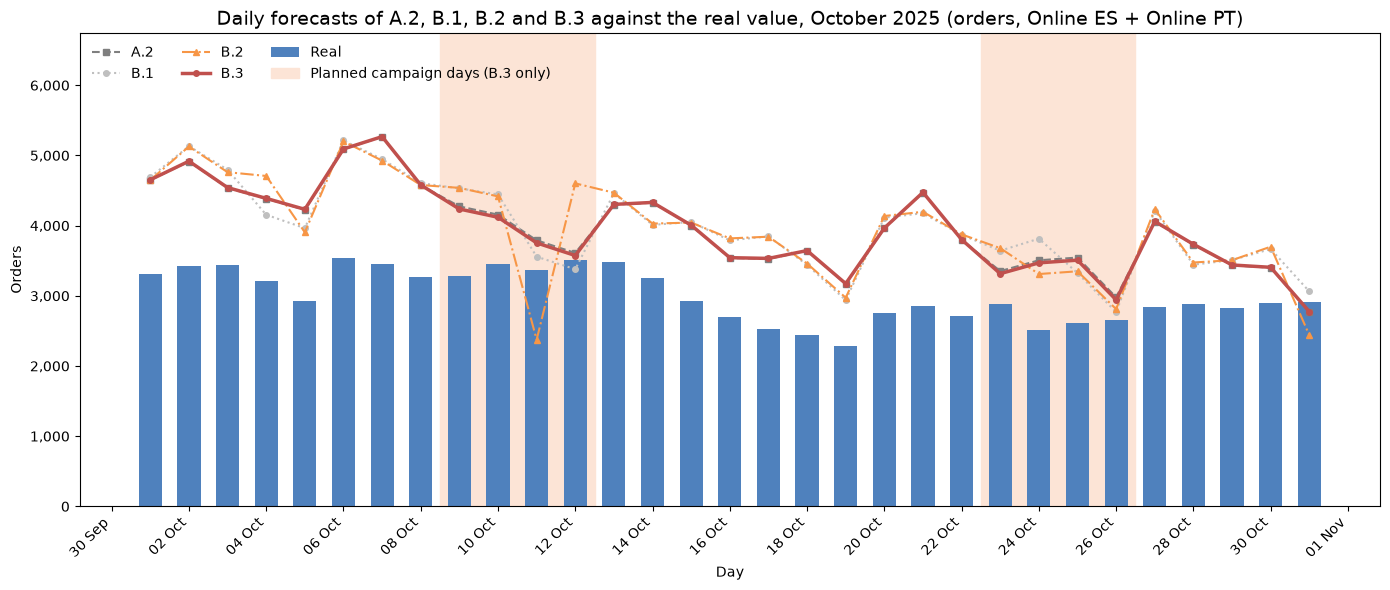

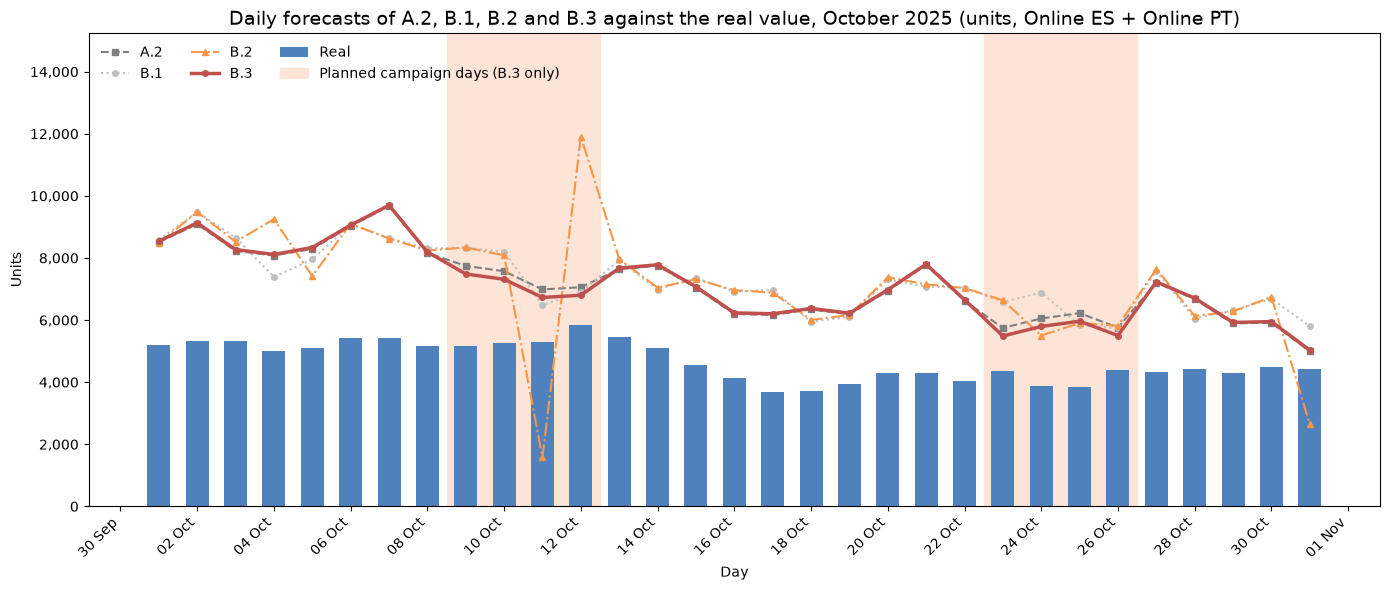

October 2025 - whole month:


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,A.2,32.27,31.97,"1,053.37",-7.68
units,A.2,52.56,52.56,"2,589.17",-17.51
orders,B.1,32.88,32.60,"1,079.46",-8.12
units,B.1,55.04,55.04,"2,685.72",-18.92
orders,B.2,35.28,32.15,"1,117.58",-8.77
units,B.2,60.59,53.05,"2,983.77",-23.59
orders,B.3,32.05,31.77,"1,051.31",-7.65
units,B.3,51.68,51.68,"2,570.06",-17.24


October 2025 - planned campaign days only (8 days):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,A.2,20.30,20.30,693.57,-2.26
units,A.2,39.66,39.66,"1,951.78",-7.08
orders,B.1,22.40,21.32,820.94,-3.57
units,B.1,44.41,44.41,"2,259.94",-9.83
orders,B.2,27.93,19.75,902.96,-4.53
units,B.2,60.80,41.31,"3,211.35",-20.86
orders,B.3,19.09,19.09,661.01,-1.96
units,B.3,34.23,34.23,"1,703.18",-5.15


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
COMPARE_MONTH = "2025-10"    # month with planned campaigns in the B.3 scenario
# model -> (predictions table, colour, line style, marker); the scenario B.3 is highlighted in red
COMPARE = {
    "A.2": ("it2_predictions", "#7F7F7F", "--", "s"),
    "B.1": ("b1_predictions",  "#BFBFBF", ":",  "o"),
    "B.2": ("b2_predictions",  "#F79646", "-.", "^"),
    "B.3": ("b3_predictions",  "#C0504D", "-",  "o"),
}
# ------------------------------------

# 1. Daily forecasts of each model in the comparison month
month_preds = []
for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        print(f"{name} skipped: run its model cell first ({var} not found).")
        continue
    p = globals()[var]
    month_preds.append(p[p["month"] == COMPARE_MONTH].assign(model=name))
month_preds = pd.concat(month_preds, ignore_index=True)
month_preds["day"] = pd.to_datetime(month_preds["day"])

# 2. Planned campaign days in the comparison month (from the B.3 plan)
month_start = pd.Timestamp(f"{COMPARE_MONTH}-01")
month_end = month_start + pd.offsets.MonthEnd(0)
planned = plan_active[(plan_active.index >= month_start) & (plan_active.index <= month_end)]
planned_days = planned[planned == 1].index

# 3. One daily chart per target
for t in TARGETS:
    actual = b3_daily.loc[month_start:month_end, t]
    fig, ax = plt.subplots(figsize=(14, 6))
    for d in planned_days:                                   # shade the planned campaign days
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color='#FCE4D6', zorder=0)
    ax.bar(actual.index, actual, color='#4F81BD', width=0.6, label='Real', zorder=1)
    values = [actual.to_numpy(dtype=float)]
    for name in COMPARE:
        g = month_preds[(month_preds["model"] == name) & (month_preds["target"] == t)].sort_values("day")
        if g.empty:
            continue
        _, colour, style, marker = COMPARE[name]
        ax.plot(g["day"], g["forecast"], color=colour, linestyle=style, marker=marker, markersize=4,
                linewidth=2.5 if name == "B.3" else 1.5, label=name, zorder=2)
        values.append(g["forecast"].to_numpy(dtype=float))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    ax.set_title(f'Daily forecasts of A.2, B.1, B.2 and B.3 against the real value, '
                 f'{month_start:%B %Y} ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Day'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#FCE4D6', label='Planned campaign days (B.3 only)')]
    ax.legend(handles=handles, frameon=False, ncol=3, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 4. Metrics of the four models in the comparison month: whole month and planned campaign days only
def metrics_by(df):
    return pd.DataFrame([
        {"model": m, "target": t, **error_metrics(g["actual"], g["forecast"])}
        for (m, t), g in df.groupby(["model", "target"])
    ]).set_index(["target", "model"]).round(2)

print(f"{month_start:%B %Y} - whole month:")
display(metrics_by(month_preds))
print(f"{month_start:%B %Y} - planned campaign days only ({len(planned_days)} days):")
display(metrics_by(month_preds[month_preds["day"].isin(planned_days)]))

### B.3: results

Indicating the two stock promotions planned for October barely changes the forecast: the October error of B.3 is practically the same as that of A.2 for both targets. The daily chart explains why. On the days of the stock promotions, actual orders and units show no visible increase compared with the surrounding days, and the model, which learned the effect of this campaign family from its past occurrences in 2025, estimates an effect close to zero. The mechanism works as intended, but this campaign family has no measurable impact on volume, so indicating it does not improve the forecast.

The main error in October lies elsewhere. All models overestimate the whole month by more than 30%, day after day, because the yearly lag carries the special prices campaign of October 2024, which was not repeated in 2025 (see B.1). Indicating a campaign that does take place does not address this; what would help is the model knowing that a campaign of the previous year will *not* take place. In a dashboard, this would follow naturally if every campaign family not indicated by the user were assumed not to be planned.

The chart also shows two abrupt changes in the B.2 forecast for units around 12 October, a national holiday in Spain that fell on a Sunday in 2025 and on a Saturday in 2024. The holiday feature, estimated from very few days, causes these jumps, which illustrates the noise that led to B.2 being rejected.

**To close section B**, the day of the week, holidays and paydays are therefore not used in the following models. The fixed campaigns, described relative to the previous year, are kept: they do not harm the forecast and they correct the days where a campaign moves from one year to the next.

## C. Tree-based machine learning models

### Why move beyond linear regression
Sections A and B used linear regression, the simplest machine learning model, so that each improvement could be attributed to the inputs rather than to the algorithm. They led to three conclusions:
- **The yearly lag is the most valuable input.** A.2 – the recent level (lags of 62 to 68 days) plus the value of the same weekday in the previous year – remains the best model.
- **Calendar features add little on top of it.** Campaigns, holidays and paydays repeat every year on the same days, or very close to them, **so their effect is already carried by the yearly lag**.
- **The remaining error is partly a matter of information.** Some months are overestimated because the previous year included commercial actions that were not repeated, which no model can infer from past sales alone.

Linear regression also has limitations of its own, which may contribute to the error. It applies the same weight to each input on every day, so the relationship between the previous year and the current one is assumed to be the same on an ordinary day and on a peak day. It adds the effect of each input independently, so it cannot capture interactions, for example a campaign having a different effect at the weekend. And, as B.2 showed, it reacts strongly to features estimated from very few examples.

This section therefore keeps the inputs of A.2 and changes the algorithm, to measure whether a more flexible model makes better use of the same information.

### Model
Tree-based models learn the forecast through a sequence of questions about the inputs – for example, whether the value of the previous year is above a certain level – and the order of these questions is learned from the data rather than defined in advance. In practice, many trees are combined, which makes the result more stable. This section uses a **Random Forest**, which trains many trees independently on different samples of the data and averages their forecasts. It is robust and has few settings to tune. 

### Design choices
- **Same inputs as A.2, plus the fixed campaigns.** The models receive the lags of 62 to 68 days and the yearly lag, as A.2, and the six fixed campaigns, described relative to the previous year as in section B. This keeps the comparison with A.2 focused on the algorithm, while allowing the trees to use the campaign calendar where it differs from the previous year.
- **Forecasting the ratio to the previous year.** Trees cannot forecast values outside the range seen in training: with sales growing over time, they would never forecast a level higher than the highest one in the training data. Instead of the daily volume, the models therefore forecast the ratio between the volume of the day and the volume of the equivalent day in the previous year, and the forecast is obtained by multiplying that ratio by the previous year's value.
- **Limited complexity.** With only a few hundred training days, trees can easily memorise the past. Their depth and the minimum number of days per leaf are therefore limited to reduce the risk of overfitting.

The forecasting rule, the test months and the metrics are the same as in the previous sections, so the results can be compared directly with A.2. If the error remains similar, this will confirm that the main limitation is the information available rather than the algorithm.

### C.1: Random Forest

C.1 replaces the linear regression with a **Random Forest**. Many decision trees are trained, each on a different random sample of the training days and looking at a random subset of the inputs at each step, and the forecast is the average of all the trees. Because each tree makes different mistakes, averaging them gives a more stable forecast than any single tree.

**Inputs.** The model receives the same lags as A.2 – the values of the target 62 to 68 days earlier and the value of the same weekday in the previous year – and the six fixed campaigns, relative to the previous year (+1, -1 or 0, as in section B).

**Target.** The model forecasts the **ratio** between the volume of the day and the volume of the same weekday in the previous year. The forecast in orders or units is then this ratio multiplied by the previous year's value. With this target, the campaign features fit naturally: when a campaign takes place on the same days in both years, the ratio stays close to its usual level and the feature is 0; when the campaign moves, the feature is +1 or -1 and the trees can learn that the ratio rises or falls on those days. The ratio requires the previous year's value, so training starts on 30 December 2024, as in A.2.

**Settings.** The forest contains 500 trees. To limit overfitting with only a few hundred training days, each tree has a maximum depth of 6, each final answer is based on at least 7 days, and each split considers half of the inputs. A fixed random seed makes the results reproducible.

**Feature importance.** Besides the usual results, the code shows how much each input contributes to the forecast (the share of the error reduction achieved by the questions that use it), which helps to understand what the trees rely on.

Unlike B.1, the days of 2024 cannot be used for training, as the ratio cannot be computed without the previous year’s value; the longer training period of B.1 is therefore not possible with this target.

In [19]:
# ============================================================
# C.1 - Random Forest: A.2 inputs + fixed campaigns relative to the previous year
# Targets: daily orders and daily units (SALE lines, PT + ES)
# The model forecasts the RATIO between the day and the same weekday of the previous year;
# the forecast is ratio x value of the previous year (trees cannot extrapolate to unseen levels)
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# ---------- Configuration ----------
C1_ID = "C.1"                                                                  # short name used in the result tables
C1_NAME = "C.1 Random Forest (A.2 inputs + campaigns vs last year)"            # full name used in charts
C1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
C1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
C1_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
C1_RF_PARAMS = dict(
    n_estimators=500,        # number of trees
    max_depth=6,             # limited depth: few training days, avoid memorising the past
    min_samples_leaf=7,      # each final answer is based on at least one week of days
    max_features=0.5,        # each split looks at half of the features: more diverse trees
    random_state=42,         # reproducible results
    n_jobs=-1,
)
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
c1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
c1_daily["day"] = pd.to_datetime(c1_daily["day"])
c1_daily = c1_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(c1_daily)} days, from {c1_daily.index.min().date()} to {c1_daily.index.max().date()}")

# 2. Lag features and target ratio
#    ratio = value of the day / value of the same weekday of the previous year
for t in TARGETS:
    for lag in C1_RECENT_LAGS + [C1_YEARLY_LAG]:
        c1_daily[f"{t}_lag_{lag}"] = c1_daily[t].shift(lag)
    c1_daily[f"{t}_ratio"] = c1_daily[t] / c1_daily[f"{t}_lag_{C1_YEARLY_LAG}"].replace(0, np.nan)

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=c1_daily.index, columns=list(C1_CAMPAIGNS.values()))
for family, col in C1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(C1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
c1_daily = c1_daily.join(camp_diff)
C1_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def c1_features(t):
    return [f"{t}_lag_{lag}" for lag in C1_RECENT_LAGS + [C1_YEARLY_LAG]] + C1_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Evaluation by calendar month
c1_results, c1_predictions, c1_importance = [], [], {}
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = c1_daily[c1_daily.index <= cutoff]
    test = c1_daily[(c1_daily.index >= month_start) & (c1_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(C1_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = c1_features(t)
        train_t = train.dropna(subset=features + [f"{t}_ratio"])   # the yearly lag exists from 30 December 2024

        model = RandomForestRegressor(**C1_RF_PARAMS).fit(train_t[features], train_t[f"{t}_ratio"])
        forecast = model.predict(test[features]) * test[f"{t}_lag_{C1_YEARLY_LAG}"].to_numpy()
        actual = test[t].to_numpy()
        c1_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)

        c1_results.append({
            "model": C1_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            **error_metrics(actual, forecast),
        })
        c1_predictions.append(pd.DataFrame({
            "model": C1_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

c1_results = pd.DataFrame(c1_results)
c1_predictions = pd.concat(c1_predictions, ignore_index=True)

# 6. Results
print("\nResults by month:")
display(c1_results)

print("Overall results (all test days pooled):")
c1_overall = pd.DataFrame([
    {"model": C1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in c1_predictions.groupby("target")
])
display(c1_overall)

# 7. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in c1_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Results by month:


,model,target,month,data_up_to,train_from,train_days,WAPE_pct,Bias_pct,RMSE,R2
0,C.1,orders,2025-08,2025-06-30,2024-12-30,183,24.83,22.37,"1,069.10",-1.79
1,C.1,units,2025-08,2025-06-30,2024-12-30,183,43.97,43.71,"3,586.08",-5.13
2,C.1,orders,2025-09,2025-07-31,2024-12-30,214,40.21,40.21,"1,272.09",-13.84
3,C.1,units,2025-09,2025-07-31,2024-12-30,214,45.88,45.88,"2,375.86",-23.31
4,C.1,orders,2025-10,2025-08-31,2024-12-30,245,29.10,28.50,"1,000.55",-6.83
5,C.1,units,2025-10,2025-08-31,2024-12-30,245,61.67,61.67,"3,039.02",-24.51
6,C.1,orders,2025-11,2025-09-30,2024-12-30,275,15.88,5.71,"2,052.05",0.97
7,C.1,units,2025-11,2025-09-30,2024-12-30,275,18.45,1.01,"7,350.22",0.94
8,C.1,orders,2025-12,2025-10-31,2024-12-30,306,25.43,14.91,"1,882.39",-0.87
9,C.1,units,2025-12,2025-10-31,2024-12-30,306,36.85,29.54,"4,523.37",-3.58


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,C.1,orders,24.68,18.31,"1,515.04",0.92
1,C.1,units,34.83,26.48,"4,508.06",0.89


Feature importance (share of the error reduction, average over the test months):


,orders,units
lag_364,22.90,16.70
lag_68,15.00,19.10
lag_64,11.20,10.30
lag_67,10.10,9.40
lag_63,10.00,11.50
lag_62,9.60,11.80
lag_66,9.40,10.60
lag_65,6.90,6.30
camp_easter_holy_week_vs_ly,4.80,4.30
camp_black_friday_vs_ly,0.00,0.00


C.1 Random Forest (A.2 inputs + campaigns vs last year) | 14 features | model values from 2024-12-30


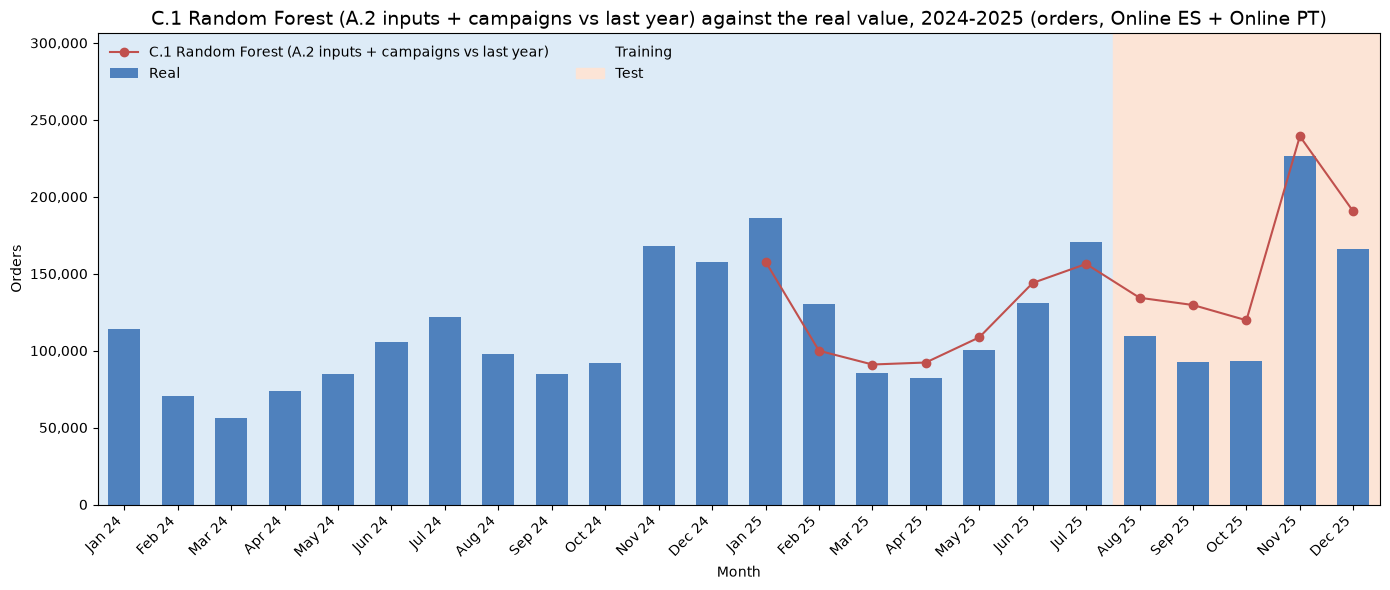

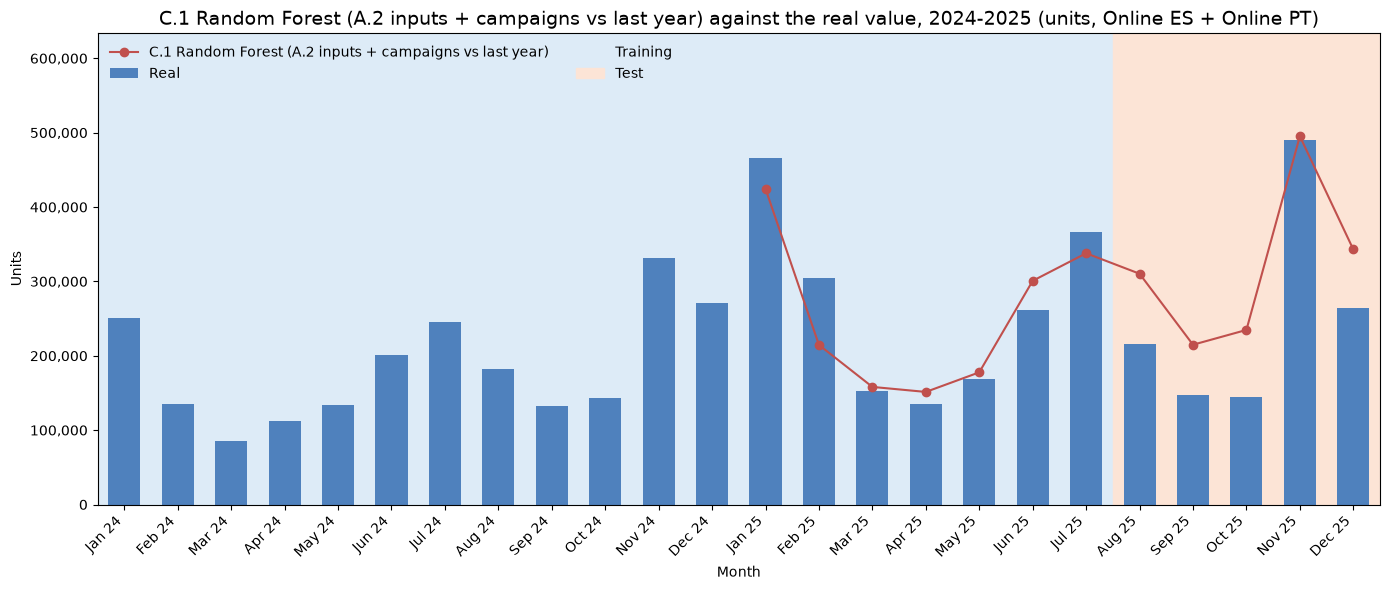

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.ensemble import RandomForestRegressor

# ---------- Chart settings ----------
MIN_COVERAGE = 0.5      # a partly covered month is shown only if the model covers at least this share of its days
# ------------------------------------

# 1. Model values in the training months: fit of the model of the last test month,
#    which is trained on all data up to its cutoff (training continues month after month)
last_month_start = pd.Timestamp(f"{TEST_MONTHS[-1]}-01")
last_cutoff = last_month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)
first_test_start = pd.Timestamp(f"{TEST_MONTHS[0]}-01")
train = c1_daily[c1_daily.index <= last_cutoff]

fitted = {}
for t in TARGETS:
    features = c1_features(t)
    train_t = train.dropna(subset=features + [f"{t}_ratio"])
    model = RandomForestRegressor(**C1_RF_PARAMS).fit(train_t[features], train_t[f"{t}_ratio"])
    fitted[t] = pd.Series(model.predict(train_t[features]) * train_t[f"{t}_lag_{C1_YEARLY_LAG}"].to_numpy(),
                          index=train_t.index)
fitted = pd.DataFrame(fitted)
fitted = fitted[fitted.index < first_test_start]          # test months use the real forecasts
print(f"{C1_NAME} | {len(c1_features(TARGETS[0]))} features | model values from {fitted.index.min().date()}")

# 2. Daily model values = fit in training months + forecast in test months
forecast_daily = c1_predictions.pivot_table(index="day", columns="target", values="forecast")
model_daily = pd.concat([fitted, forecast_daily[TARGETS]]).sort_index()

# 3. Monthly totals
#    (a partly covered month is estimated as daily average x days in the month, if coverage is enough)
model_mean = model_daily.resample("MS").mean()
coverage = model_daily.iloc[:, 0].resample("MS").count() / model_mean.index.days_in_month
monthly_model = model_mean.mul(model_mean.index.days_in_month, axis=0)[coverage >= MIN_COVERAGE]
tab_all = c1_daily[TARGETS].resample("MS").sum()

# 4. One chart per target
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(first_test_start)
last_test = months.get_loc(last_month_start)

for t in TARGETS:
    tab = pd.DataFrame({"Real": tab_all[t], "Model": monthly_model[t]}).reindex(months)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab['Real'], color='#4F81BD', width=0.6, label='Real')
    ax.plot(x, tab['Model'], color='#C0504D', marker='o', label=C1_NAME)      # NaN before the yearly lag is available
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{C1_NAME} against the real value, 2024-2025 ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    top = np.nanmax(tab[['Real', 'Model']].to_numpy(dtype=float))
    ax.set_ylim(0, top * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

### C.1: results

The Random Forest performs at the same level as A.2. It is slightly more accurate in November, which lowers the RMSE for orders, as it makes smaller errors on the peak days, but slightly less accurate in August and December; overall, the two models are practically equivalent. With the same inputs, a more flexible algorithm does not improve the forecast.

Forecasting the ratio to the previous year makes the source of the error visible. In the training period, from January to July 2025, the volume was well above 2024 – in most months between 30% and 60% higher. In the second half of 2025, growth slowed sharply: August, September, October and December were only slightly above 2024, while November, driven by a stronger Black Friday, still grew considerably. The model learns from the first half of the year that the current year is much higher than the previous one and applies this to the following months, which explains the overestimation from August to October and in December, and the accurate forecast for November.

No input tells the model that growth has slowed, and no algorithm can infer it from the same data. Together with the commercial actions of 2024 that were not repeated in 2025, this explains why all the models so far overestimate the same months. The next step is therefore to give the model information about **recent growth**: how the volume compares with the previous year in the weeks just before the forecast is made. Given the two-month horizon, this information arrives with a delay, but it should allow the model to adjust to a change in growth within a few months rather than assuming that the growth of the first half of the year continues.

### C.2: Random Forest with recent growth

C.1 showed that the main source of error is the slowdown in growth in the second half of 2025, which no input told the model about.

C.2 adds this information through the **recent growth**: the volume of the last four weeks known at the time of the forecast, divided by the volume of the same four weeks in the previous year. The four weeks end 62 days before the day being forecast, so they always fall before the cutoff date, in line with the forecasting rule. For example, when October is forecast at the end of August, the recent growth reflects how August compared with the previous year.

**Target.** Instead of forecasting the ratio to the previous year directly, the trees forecast the **deviation** of each day from the recent growth:
- deviation = (value of the day / value of the same weekday in the previous year) / recent growth;
- forecast = value of the previous year × recent growth × forecast deviation.

The overall level of the forecast therefore comes directly from the most recent growth, and the trees only learn what is specific to each day – peaks, campaigns that change dates, weekly patterns. This also avoids the main limitation of tree-based models: they cannot forecast values outside the range seen in training, so if the recent growth fell to a level never seen before, a model that learned growth itself would not follow it, while here the growth is applied outside the trees.

**Inputs and settings.** The inputs and the Random Forest settings are the same as in C.1, so the difference between the two models measures only the effect of the recent growth.

**Limitations.** Computing the recent growth requires the same four weeks of the previous year, so training starts only at the end of March 2025, and the first test months are trained on very few days. Given the two-month horizon, the model also reacts to a change in growth with a delay: if growth changes in the two months before the forecast month, the model does not know it yet. A month in which growth differs from the recent trend – for example, a Black Friday much stronger than the preceding months – will be forecast too low.

The results table includes two additional columns: `recent_growth`, the average growth the model starts from in each month, and `actual_growth`, the growth that actually happened, which shows directly how close the starting point of the forecast was to reality.

In [21]:
# ============================================================
# C.2 - Random Forest: C.1 + recent growth
# Targets: daily orders and daily units (SALE lines, PT + ES)
# Recent growth = volume of the last 4 weeks known at the time of the forecast / same weeks of the previous year.
# The model forecasts the DEVIATION of the day from that recent growth:
#   deviation = (value of the day / same weekday of the previous year) / recent growth
#   forecast  = value of the previous year x recent growth x forecast deviation
# so the level comes from the recent growth and the trees only learn what is specific to each day
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# ---------- Configuration ----------
C2_ID = "C.2"                                          # short name used in the result tables
C2_NAME = "C.2 Random Forest (C.1 + recent growth)"    # full name used in charts
C2_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
C2_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
C2_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
C2_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
C2_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
C2_RF_PARAMS = dict(
    n_estimators=500,        # number of trees
    max_depth=6,             # limited depth: few training days, avoid memorising the past
    min_samples_leaf=7,      # each final answer is based on at least one week of days
    max_features=0.5,        # each split looks at half of the features: more diverse trees
    random_state=42,         # reproducible results
    n_jobs=-1,
)
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
c2_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
c2_daily["day"] = pd.to_datetime(c2_daily["day"])
c2_daily = c2_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(c2_daily)} days, from {c2_daily.index.min().date()} to {c2_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the trees)
for t in TARGETS:
    for lag in C2_RECENT_LAGS + [C2_YEARLY_LAG]:
        c2_daily[f"{t}_lag_{lag}"] = c2_daily[t].shift(lag)
    recent = c2_daily[t].rolling(C2_GROWTH_WINDOW).sum().shift(C2_GROWTH_END_LAG)
    recent_last_year = recent.shift(C2_YEARLY_LAG)
    c2_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    c2_daily[f"{t}_ratio"] = c2_daily[t] / c2_daily[f"{t}_lag_{C2_YEARLY_LAG}"].replace(0, np.nan)
    c2_daily[f"{t}_deviation"] = c2_daily[f"{t}_ratio"] / c2_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=c2_daily.index, columns=list(C2_CAMPAIGNS.values()))
for family, col in C2_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(C2_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
c2_daily = c2_daily.join(camp_diff)
C2_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def c2_features(t):
    return [f"{t}_lag_{lag}" for lag in C2_RECENT_LAGS + [C2_YEARLY_LAG]] + C2_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Evaluation by calendar month
c2_results, c2_predictions, c2_importance = [], [], {}
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = c2_daily[c2_daily.index <= cutoff]
    test = c2_daily[(c2_daily.index >= month_start) & (c2_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(C2_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = c2_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        model = RandomForestRegressor(**C2_RF_PARAMS).fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = (model.predict(test[features])
                    * test[f"{t}_recent_growth"].to_numpy()
                    * test[f"{t}_lag_{C2_YEARLY_LAG}"].to_numpy())
        actual = test[t].to_numpy()
        c2_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)

        c2_results.append({
            "model": C2_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{C2_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        c2_predictions.append(pd.DataFrame({
            "model": C2_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

c2_results = pd.DataFrame(c2_results)
c2_predictions = pd.concat(c2_predictions, ignore_index=True)

# 6. Results
print("\nResults by month:")
display(c2_results)

print("Overall results (all test days pooled):")
c2_overall = pd.DataFrame([
    {"model": C2_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in c2_predictions.groupby("target")
])
display(c2_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 7. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in c2_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,C.2,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,19.29,-16.76,826.79,-0.67
1,C.2,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,27.76,-26.44,"2,224.54",-1.36
2,C.2,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,21.53,-20.67,710.61,-3.63
3,C.2,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,23.96,-23.90,"1,249.96",-5.73
4,C.2,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,12.44,2.50,453.79,-0.61
5,C.2,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,15.77,-7.36,931.21,-1.39
6,C.2,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,14.24,-5.02,"2,149.44",0.96
7,C.2,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,20.43,-14.43,"7,942.18",0.93
8,C.2,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,24.06,1.35,"1,718.85",-0.56
9,C.2,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,28.36,3.55,"3,354.03",-1.52


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,C.2,orders,18.15,-6.44,"1,335.57",0.94
1,C.2,units,23.22,-13.01,"4,016.50",0.91


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units
lag_364,40.30,49.70
lag_68,14.30,11.90
lag_67,12.80,8.60
lag_66,8.40,6.30
lag_62,6.50,5.50
lag_63,4.80,6.10
lag_64,4.40,4.60
lag_65,4.30,5.80
camp_easter_holy_week_vs_ly,4.00,1.50
camp_black_friday_vs_ly,0.00,0.00


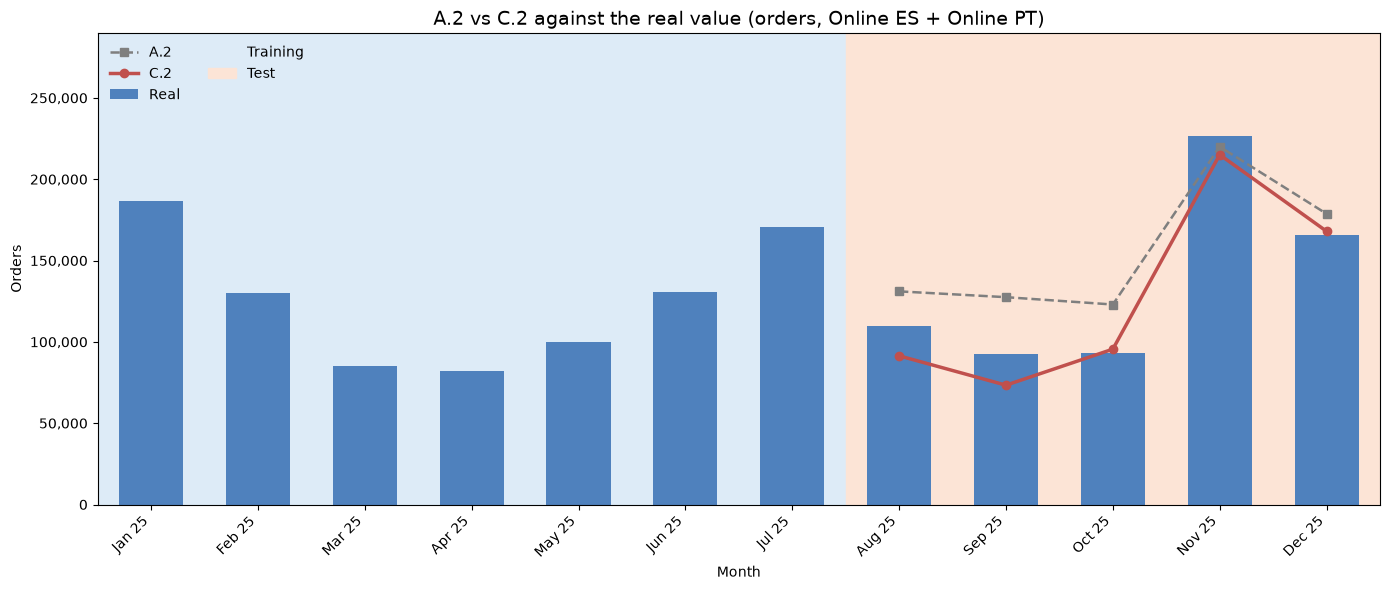

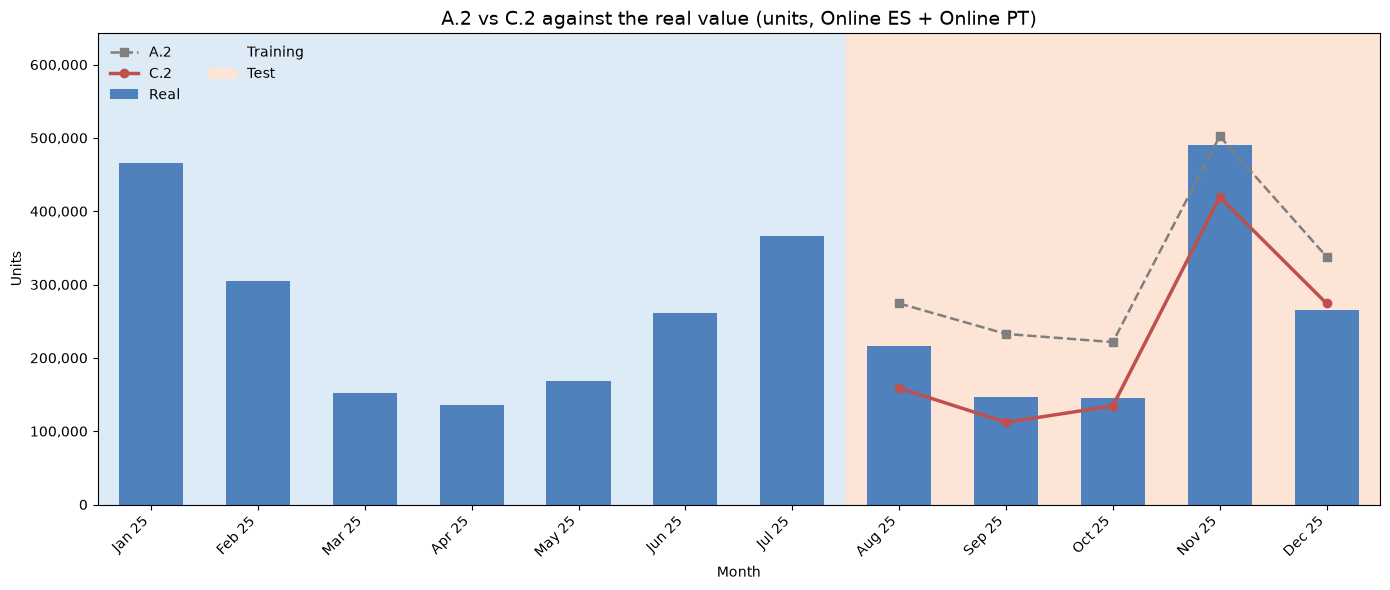

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,A.2,23.40,13.46,"1,625.14",0.91
units,A.2,32.80,24.17,"4,263.82",0.90
orders,C.2,18.15,-6.44,"1,335.57",0.94
units,C.2,23.22,-13.01,"4,016.50",0.91


2. Change from A.2 to C.2 (negative WAPE and RMSE changes = C.2 is better):


,WAPE_pct change,Bias_pct change,RMSE change,R2 change
target,,,,
orders,-5.26,-19.91,-289.57,0.03
units,-9.58,-37.18,-247.32,0.01


3. Daily error by month - WAPE (%):


model            A.2   C.2
target month              
orders 2025-08 20.89 19.29
       2025-09 37.85 21.53
       2025-10 32.27 12.44
       2025-11 17.26 14.24
       2025-12 20.42 24.06
units  2025-08 28.09 27.76
       2025-09 57.98 23.96
       2025-10 52.56 15.77
       2025-11 19.68 20.43
       2025-12 36.07 28.36

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model            A.2    C.2
target month               
orders 2025-08 19.33 -16.76
       2025-09 37.85 -20.67
       2025-10 31.97   2.50
       2025-11 -2.84  -5.02
       2025-12  7.84   1.35
units  2025-08 27.01 -26.44
       2025-09 57.98 -23.90
       2025-10 52.56  -7.36
       2025-11  2.45 -14.43
       2025-12 27.68   3.55

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast          error        error_pct       
model                       A.2     C.2    A.2    C.2       A.2    C.2
target month                                                          
orders 2025-08  109819   131047   91418  21228 -18401     19.30 -16.80
       2025-09   92480   127483   73367  35003 -19113     37.80 -20.70
       2025-10   93177   122968   95509  29791   2332     32.00   2.50
       2025-11  226443   220002  215065  -6441 -11378     -2.80  -5.00
       2025-12  165749   178751  167994  13002   2245      7.80   1.40
units  2025-08  215951   274285  158860  58334 -57091     27.00 -26.40
       2025-09  147272   232665  112072  85393 -35200     58.00 -23.90
       2025-10  145193   221509  134505  76316 -10688     52.60  -7.40
       2025-11  490281   502317  419518  12036 -70763      2.50 -14.40
       2025-12  264817   338114  274225  73297   9408     27.70   3.60

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker)
COMPARE = {
    "A.2": ("it2_predictions", "#7F7F7F", "--", "s"),
    "C.2": ("c2_predictions",  "#C0504D", "-",  "o"),
}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Chart: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index=["month_start"], columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = c2_daily[TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == model_names[-1] else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the first to the last model
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
print("1. Overall metrics (all test days pooled):")
display(overall.round(2))

first, last = model_names[0], model_names[-1]
change = (overall.xs(last, level="model") - overall.xs(first, level="model"))
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {first} to {last} (negative WAPE and RMSE changes = {last} is better):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"])
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"])["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### C.2: results

Adding the recent growth produces the best model so far. Compared with A.2, the overall WAPE falls by about five percentage points for orders and ten for units, and R² rises for both targets. The bias changes sign: while all previous models overestimated most months, C.2 slightly underestimates them.

The improvement is concentrated in the months where growth had slowed: in October, for example, the error is reduced to less than half for orders and to about a third for units. When October is forecast, the recent growth reflects August, which was only slightly above the previous year, so the model no longer assumes that the strong growth of the first half of 2025 continues.

The `recent_growth` and `actual_growth` columns show the main limitation of this approach. With a two-month horizon, the recent growth describes the situation two months before the forecast month, so the model reacts to changes in growth with a delay. When growth accelerates, as in November with a stronger Black Friday, the forecast is too low; when it slows after the reference weeks, as in September, the forecast is too high at the start and the day-level adjustment, learned from a short training period, does not fully compensate. 

**Conclusion.** C.2 confirms the diagnosis of the previous models: the main source of error was the level of growth, not the algorithm or the calendar. C.2 becomes the new reference model.

### C.3: linear regression with recent growth (control model)

C.2 combined two changes compared with A.2: a different algorithm (Random Forest instead of linear regression) and new information (the recent growth). C.1 had already shown that changing only the algorithm did not improve the results. To confirm where the improvement of C.2 comes from, C.3 uses exactly the same structure as C.2 – the same inputs, the same recent growth and the same target (the deviation of each day from the recent growth) – but with a **linear regression** instead of the Random Forest.

The comparison of the three models answers two questions:
- **A.2 vs C.3** (same algorithm, with and without the recent growth): how much of the improvement comes from the new information;
- **C.3 vs C.2** (same information, different algorithm): how much comes from the Random Forest.

C.3 is a control model: its purpose is to explain the result of C.2, not to replace it.

In [23]:
# ============================================================
# C.3 - Control model: same structure as C.2, with Linear Regression instead of Random Forest
# Purpose: measure how much of the improvement of C.2 comes from the recent growth
#          and how much from the Random Forest
# Targets: daily orders and daily units (SALE lines, PT + ES)
#   deviation = (value of the day / same weekday of the previous year) / recent growth
#   forecast  = value of the previous year x recent growth x forecast deviation
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import LinearRegression

# ---------- Configuration ----------
C3_ID = "C.3"                                                  # short name used in the result tables
C3_NAME = "C.3 Linear Regression (C.2 structure, control)"    # full name used in charts
C3_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
C3_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
C3_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
C3_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
C3_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
c3_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
c3_daily["day"] = pd.to_datetime(c3_daily["day"])
c3_daily = c3_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(c3_daily)} days, from {c3_daily.index.min().date()} to {c3_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the model)
for t in TARGETS:
    for lag in C3_RECENT_LAGS + [C3_YEARLY_LAG]:
        c3_daily[f"{t}_lag_{lag}"] = c3_daily[t].shift(lag)
    recent = c3_daily[t].rolling(C3_GROWTH_WINDOW).sum().shift(C3_GROWTH_END_LAG)
    recent_last_year = recent.shift(C3_YEARLY_LAG)
    c3_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    c3_daily[f"{t}_ratio"] = c3_daily[t] / c3_daily[f"{t}_lag_{C3_YEARLY_LAG}"].replace(0, np.nan)
    c3_daily[f"{t}_deviation"] = c3_daily[f"{t}_ratio"] / c3_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=c3_daily.index, columns=list(C3_CAMPAIGNS.values()))
for family, col in C3_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(C3_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
c3_daily = c3_daily.join(camp_diff)
C3_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def c3_features(t):
    return [f"{t}_lag_{lag}" for lag in C3_RECENT_LAGS + [C3_YEARLY_LAG]] + C3_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Evaluation by calendar month
c3_results, c3_predictions = [], []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = c3_daily[c3_daily.index <= cutoff]
    test = c3_daily[(c3_daily.index >= month_start) & (c3_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(C3_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = c3_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        model = LinearRegression().fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = (model.predict(test[features])
                    * test[f"{t}_recent_growth"].to_numpy()
                    * test[f"{t}_lag_{C3_YEARLY_LAG}"].to_numpy())
        actual = test[t].to_numpy()

        c3_results.append({
            "model": C3_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{C3_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        c3_predictions.append(pd.DataFrame({
            "model": C3_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

c3_results = pd.DataFrame(c3_results)
c3_predictions = pd.concat(c3_predictions, ignore_index=True)

# 6. Results
print("\nResults by month:")
display(c3_results)

print("Overall results (all test days pooled):")
c3_overall = pd.DataFrame([
    {"model": C3_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in c3_predictions.groupby("target")
])
display(c3_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,C.3,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,22.15,-12.98,915.13,-1.04
1,C.3,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,31.09,-18.44,"2,450.11",-1.86
2,C.3,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,15.97,10.83,620.97,-2.54
3,C.3,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,19.00,-3.69,"1,415.81",-7.63
4,C.3,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,19.58,11.47,698.55,-2.82
5,C.3,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,17.18,9.38,957.64,-1.53
6,C.3,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,87.94,77.11,"20,126.51",-2.25
7,C.3,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,113.57,103.40,"54,947.26",-2.59
8,C.3,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,22.85,-4.88,"1,650.56",-0.44
9,C.3,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,25.17,-6.39,"3,386.56",-1.57


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,C.3,orders,42.80,25.15,"8,962.31",-1.87
1,C.3,units,58.85,36.28,"24,415.55",-2.23


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.


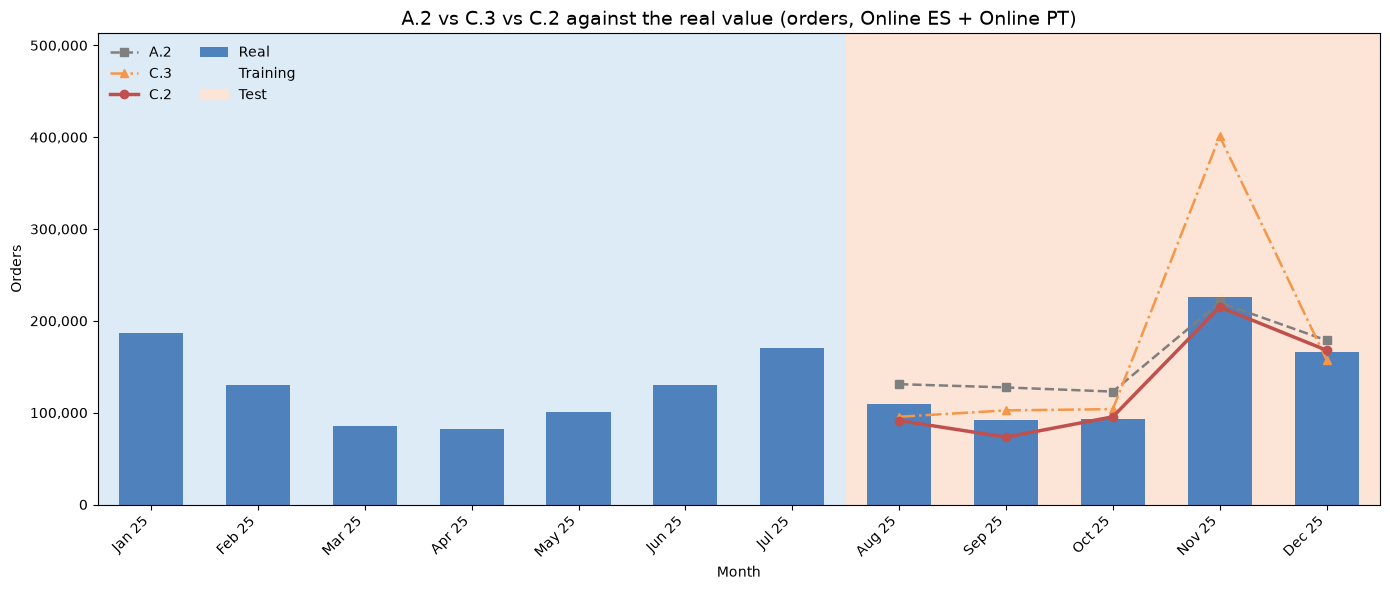

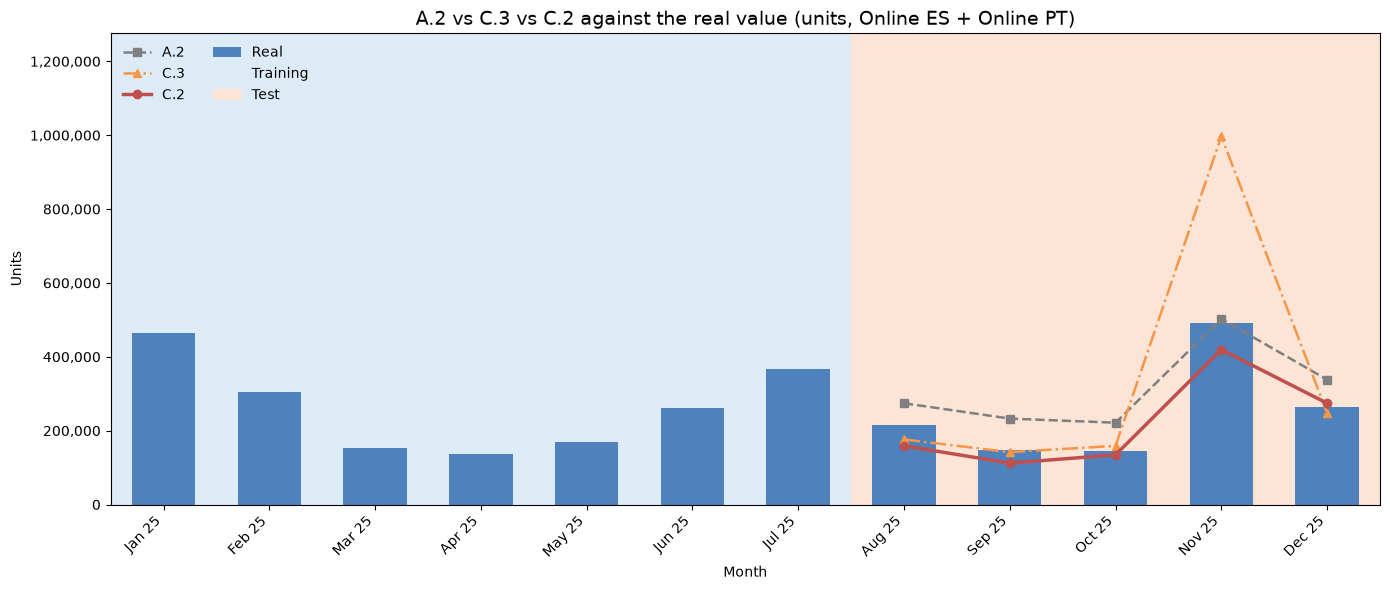

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,A.2,23.40,13.46,"1,625.14",0.91
units,A.2,32.80,24.17,"4,263.82",0.90
orders,C.2,18.15,-6.44,"1,335.57",0.94
units,C.2,23.22,-13.01,"4,016.50",0.91
orders,C.3,42.80,25.15,"8,962.31",-1.87
units,C.3,58.85,36.28,"24,415.55",-2.23


2. Change from A.2 to each model (negative WAPE and RMSE changes = better than A.2):


WAPE_pct change  Bias_pct change  RMSE change  R2 change
target model                                                          
orders C.2              -5.26           -19.91      -289.57       0.03
       C.3              19.40            11.69     7,337.17      -2.78
units  C.2              -9.58           -37.18      -247.32       0.01
       C.3              26.05            12.11    20,151.73      -3.13

3. Daily error by month - WAPE (%):


model            A.2   C.2    C.3
target month                     
orders 2025-08 20.89 19.29  22.15
       2025-09 37.85 21.53  15.97
       2025-10 32.27 12.44  19.58
       2025-11 17.26 14.24  87.94
       2025-12 20.42 24.06  22.85
units  2025-08 28.09 27.76  31.09
       2025-09 57.98 23.96  19.00
       2025-10 52.56 15.77  17.18
       2025-11 19.68 20.43 113.57
       2025-12 36.07 28.36  25.17

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model            A.2    C.2    C.3
target month                      
orders 2025-08 19.33 -16.76 -12.98
       2025-09 37.85 -20.67  10.83
       2025-10 31.97   2.50  11.47
       2025-11 -2.84  -5.02  77.11
       2025-12  7.84   1.35  -4.88
units  2025-08 27.01 -26.44 -18.44
       2025-09 57.98 -23.90  -3.69
       2025-10 52.56  -7.36   9.38
       2025-11  2.45 -14.43 103.40
       2025-12 27.68   3.55  -6.39

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast                  error                 \
model                       A.2     C.2     C.3    A.2    C.2     C.3   
target month                                                            
orders 2025-08  109819   131047   91418   95562  21228 -18401  -14257   
       2025-09   92480   127483   73367  102494  35003 -19113   10014   
       2025-10   93177   122968   95509  103861  29791   2332   10684   
       2025-11  226443   220002  215065  401056  -6441 -11378  174613   
       2025-12  165749   178751  167994  157654  13002   2245   -8095   
units  2025-08  215951   274285  158860  176127  58334 -57091  -39824   
       2025-09  147272   232665  112072  141845  85393 -35200   -5427   
       2025-10  145193   221509  134505  158819  76316 -10688   13626   
       2025-11  490281   502317  419518  997234  12036 -70763  506953   
       2025-12  264817   338114  274225  247891  73297   9408  -16926   

               error_pct                
model                A.2    C.2    C.3  
target month                            
orders 2025-08     19.30 -16.80 -13.00  
       2025-09     37.80 -20.70  10.80  
       2025-10     32.00   2.50  11.50  
       2025-11     -2.80  -5.00  77.10  
       2025-12      7.80   1.40  -4.90  
units  2025-08     27.00 -26.40 -18.40  
       2025-09     58.00 -23.90  -3.70  
       2025-10     52.60  -7.40   9.40  
       2025-11      2.50 -14.40 103.40  
       2025-12     27.70   3.60  -6.40

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker)
COMPARE = {
    "A.2": ("it2_predictions", "#7F7F7F", "--", "s"),   # reference: linear regression without recent growth
    "C.3": ("c3_predictions",  "#F79646", "-.", "^"),   # linear regression with recent growth
    "C.2": ("c2_predictions",  "#C0504D", "-",  "o"),   # random forest with recent growth
}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Chart: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index=["month_start"], columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = c2_daily[TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == "C.2" else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model (A.2)
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
print("1. Overall metrics (all test days pooled):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().sort_index()
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"])
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"])["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### C.3: results

The control model confirms that most of the improvement of C.2 comes from the recent growth. Compared with A.2, the linear regression with the same structure as C.2 reduces the error considerably in September and October – the months in which growth had slowed – reaching an accuracy similar to that of C.2 in most months. Outside November, the two models are close, each being more accurate in some months.

November is the exception: C.3 fails completely, forecasting almost twice the actual volume. C.3 is trained on days from March to September 2025, for which the yearly lag refers to ordinary days of 2024. On the Black Friday days of 2025, however, the yearly lag carries the Black Friday peak of 2024, far above any value seen in training. A linear regression extrapolates, applying the same weights to values several times larger than usual, and, because the forecast is also multiplied by the previous year's value, the error is amplified. A Random Forest cannot extrapolate: for values never seen in training, it answers with the closest cases it knows. In this situation, this limitation acts as a protection.

**Conclusion.** The improvement of C.2 over A.2 comes mainly from the recent growth, while the main contribution of the Random Forest is its robustness to extreme values, which is decisive in the peak months. C.2 therefore remains the reference model: it is not the most accurate in every month, but it is the only one that does not fail in the months that matter most for warehouse planning.

All models are evaluated with a rolling-origin approach: each test month is forecast by a model trained only on the data available up to its cutoff date, and the process is repeated for every month from August to December 2025. This is a form of time-series cross-validation used to measure the error of each model. No cross-validation was used to tune the settings of the models: the Random Forest parameters were set manually, and the design choices were made by comparing results on the test months, which may make the reported errors slightly optimistic.

### C.4: Random Forest with time-series cross-validation

The settings of the Random Forest in C.1 and C.2 – the maximum depth of the trees and the minimum number of days in each final answer – were chosen manually. Choosing settings by comparing results on the test months would make the reported error optimistic, as the model would be indirectly adjusted to those months. C.4 keeps everything from C.2 – inputs, recent growth and target – and chooses these settings with **time-series cross-validation**, using only the training data of each test month.

**How it works.** For each test month, the training days are split into up to three successive mini-tests. In each one, the model is trained on the earlier days, a one-month gap is left – reproducing the forecasting rule, in which the month immediately before the forecast month is not yet known – and the model is validated on the following four weeks. Six combinations of settings are compared (maximum depth of 4, 6 or 8; at least 7 or 14 days per final answer), and the one with the lowest average WAPE in the mini-tests is selected. The final model is then trained with these settings on all the training days and forecasts the test month. The test months are therefore used only once, to measure the final error. This follows the logic of scikit-learn's `TimeSeriesSplit` with a gap: the model is always validated on days after its training data, never on a random sample of days.

**Limitations.** The training period is short, so the first test months have room for only one or two mini-tests, and the choice of settings is less reliable there. If a training period were too short for any mini-test, the settings of C.2 would be used. The table of chosen settings shows, for each month, how many mini-tests were possible and which settings were selected.

**Interpretation.** If C.4 performs similarly to C.2, this shows that the manually chosen settings were not favouring the test months, which supports the reliability of the results of C.2.

In [25]:
# ============================================================
# C.4 - Random Forest: C.2 + time-series cross-validation to choose the settings
# Same inputs, recent growth and target as C.2. For each test month, the settings of the forest
# (tree depth, minimum days per leaf) are chosen by mini-tests inside the training data only:
# train on the past, leave a one-month gap, validate on the next 4 weeks.
# The final model is then trained on all training days and forecasts the test month.
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# ---------- Configuration ----------
C4_ID = "C.4"                                                       # short name used in the result tables
C4_NAME = "C.4 Random Forest (C.2 + time-series cross-validation)"   # full name used in charts
C4_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
C4_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
C4_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
C4_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
C4_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
C4_RF_FIXED = dict(max_features=0.5, random_state=42, n_jobs=-1)   # settings not tuned
C4_PARAM_GRID = [                                                    # settings compared by cross-validation
    {"max_depth": d, "min_samples_leaf": l} for d in (4, 6, 8) for l in (7, 14)
]
C4_DEFAULT = {"max_depth": 6, "min_samples_leaf": 7}  # C.2 settings, used if the training period is too short for a fold
C4_TREES_CV, C4_TREES_FINAL = 200, 500   # fewer trees in the mini-tests (faster), 500 in the final model
C4_CV_FOLDS = 3          # up to 3 mini-tests per test month
C4_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
C4_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
C4_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
c4_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
c4_daily["day"] = pd.to_datetime(c4_daily["day"])
c4_daily = c4_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(c4_daily)} days, from {c4_daily.index.min().date()} to {c4_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the trees)
for t in TARGETS:
    for lag in C4_RECENT_LAGS + [C4_YEARLY_LAG]:
        c4_daily[f"{t}_lag_{lag}"] = c4_daily[t].shift(lag)
    recent = c4_daily[t].rolling(C4_GROWTH_WINDOW).sum().shift(C4_GROWTH_END_LAG)
    recent_last_year = recent.shift(C4_YEARLY_LAG)
    c4_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    c4_daily[f"{t}_ratio"] = c4_daily[t] / c4_daily[f"{t}_lag_{C4_YEARLY_LAG}"].replace(0, np.nan)
    c4_daily[f"{t}_deviation"] = c4_daily[f"{t}_ratio"] / c4_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=c4_daily.index, columns=list(C4_CAMPAIGNS.values()))
for family, col in C4_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(C4_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
c4_daily = c4_daily.join(camp_diff)
C4_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def c4_features(t):
    return [f"{t}_lag_{lag}" for lag in C4_RECENT_LAGS + [C4_YEARLY_LAG]] + C4_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data
#    The training days are split into successive mini-tests: train on the past, leave a one-month gap,
#    validate on the next 4 weeks. The test months are never used to choose the settings.
def cv_folds(n_days):
    """Positions (train, validation) of up to C4_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(C4_CV_FOLDS):
        valid_end = n_days - k * C4_CV_VALID_DAYS
        valid_start = valid_end - C4_CV_VALID_DAYS
        train_end = valid_start - C4_CV_GAP_DAYS
        if train_end < C4_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def fit_forecast(train_part, apply_part, t, params, n_trees):
    """Train on train_part and return the forecast in orders/units for apply_part."""
    features = c4_features(t)
    model = RandomForestRegressor(n_estimators=n_trees, **params, **C4_RF_FIXED)
    model.fit(train_part[features], train_part[f"{t}_deviation"])
    forecast = (model.predict(apply_part[features])
                * apply_part[f"{t}_recent_growth"].to_numpy()
                * apply_part[f"{t}_lag_{C4_YEARLY_LAG}"].to_numpy())
    return forecast, model

def choose_params(train_t, t):
    """Return the settings with the lowest average WAPE in the mini-tests, and that WAPE."""
    folds = cv_folds(len(train_t))
    if not folds:
        return C4_DEFAULT, np.nan, 0
    scores = []
    for params in C4_PARAM_GRID:
        wapes = []
        for tr, va in folds:
            fc, _ = fit_forecast(train_t.iloc[tr], train_t.iloc[va], t, params, C4_TREES_CV)
            wapes.append(error_metrics(train_t.iloc[va][t], fc)["WAPE_pct"])
        scores.append(np.mean(wapes))
    best = int(np.argmin(scores))
    return C4_PARAM_GRID[best], scores[best], len(folds)

# 6. Evaluation by calendar month (settings chosen by cross-validation, then final model on all training days)
c4_results, c4_predictions, c4_importance, c4_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = c4_daily[c4_daily.index <= cutoff]
    test = c4_daily[(c4_daily.index >= month_start) & (c4_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(C4_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = c4_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        params, cv_wape, n_folds = choose_params(train_t, t)
        forecast, model = fit_forecast(train_t, test, t, params, C4_TREES_FINAL)
        actual = test[t].to_numpy()
        c4_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        c4_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        c4_results.append({
            "model": C4_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{C4_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        c4_predictions.append(pd.DataFrame({
            "model": C4_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

c4_results = pd.DataFrame(c4_results)
c4_predictions = pd.concat(c4_predictions, ignore_index=True)
c4_chosen = pd.DataFrame(c4_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, C.2 settings used):")
display(c4_chosen)

# 7. Results
print("\nResults by month:")
display(c4_results)

print("Overall results (all test days pooled):")
c4_overall = pd.DataFrame([
    {"model": C4_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in c4_predictions.groupby("target")
])
display(c4_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 8. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in c4_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, C.2 settings used):


,target,month,cv_folds,max_depth,min_samples_leaf,cv_WAPE_pct
0,orders,2025-08,1,4,14,28.83
1,units,2025-08,1,4,14,30.41
2,orders,2025-09,2,4,14,38.37
3,units,2025-09,2,4,14,43.69
4,orders,2025-10,3,6,14,31.38
5,units,2025-10,3,6,14,37.61
6,orders,2025-11,3,4,14,24.00
7,units,2025-11,3,4,14,29.29
8,orders,2025-12,3,6,14,16.68
9,units,2025-12,3,4,14,18.73



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,C.4,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,19.07,-17.22,806.91,-0.59
1,C.4,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,30.91,-30.43,"2,445.17",-1.85
2,C.4,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,18.87,-17.66,637.63,-2.73
3,C.4,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,22.08,-21.84,"1,186.99",-5.07
4,C.4,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,13.47,4.67,499.49,-0.95
5,C.4,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,12.92,-2.19,811.25,-0.82
6,C.4,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,13.45,-5.97,"2,199.95",0.96
7,C.4,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,19.44,-13.54,"7,786.88",0.93
8,C.4,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,23.35,0.06,"1,680.46",-0.49
9,C.4,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,27.49,2.48,"3,334.02",-1.49


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,C.4,orders,17.47,-6.44,"1,335.42",0.94
1,C.4,units,22.65,-12.73,"3,970.21",0.91


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units
lag_364,39.40,50.10
lag_68,17.00,14.00
lag_67,14.90,10.80
lag_66,9.60,6.20
lag_62,5.80,4.90
lag_64,4.40,3.60
lag_65,4.30,4.50
lag_63,3.90,5.40
camp_easter_holy_week_vs_ly,0.70,0.40
camp_black_friday_vs_ly,0.00,0.00


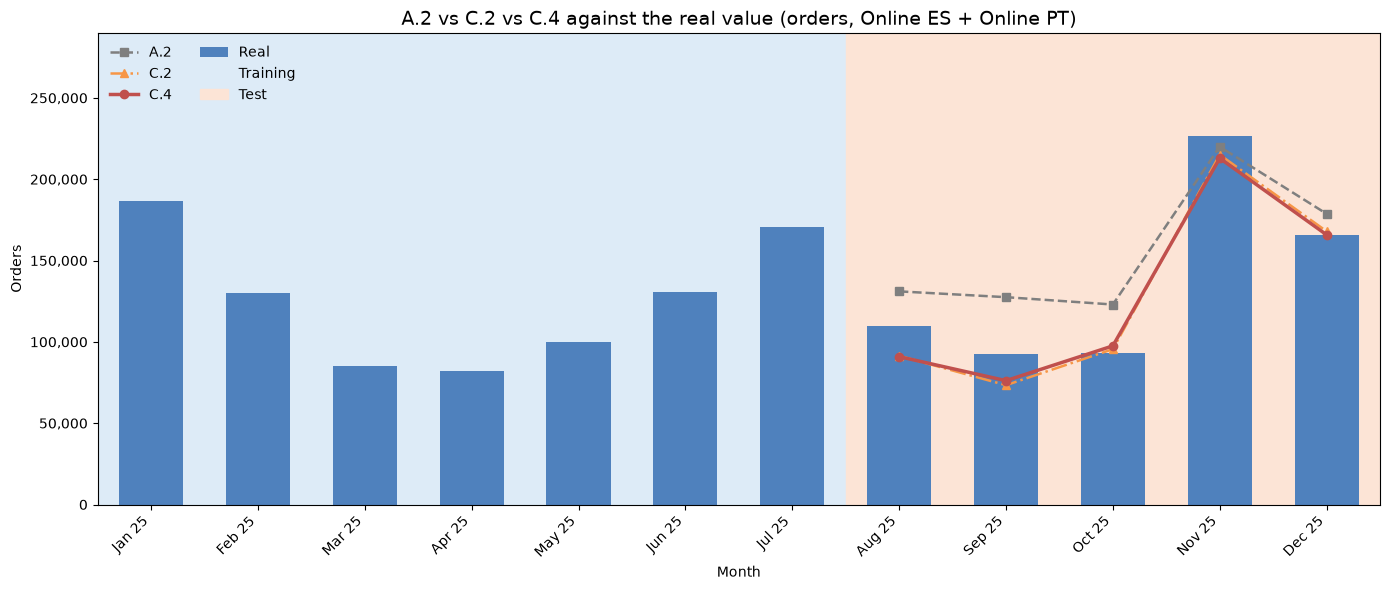

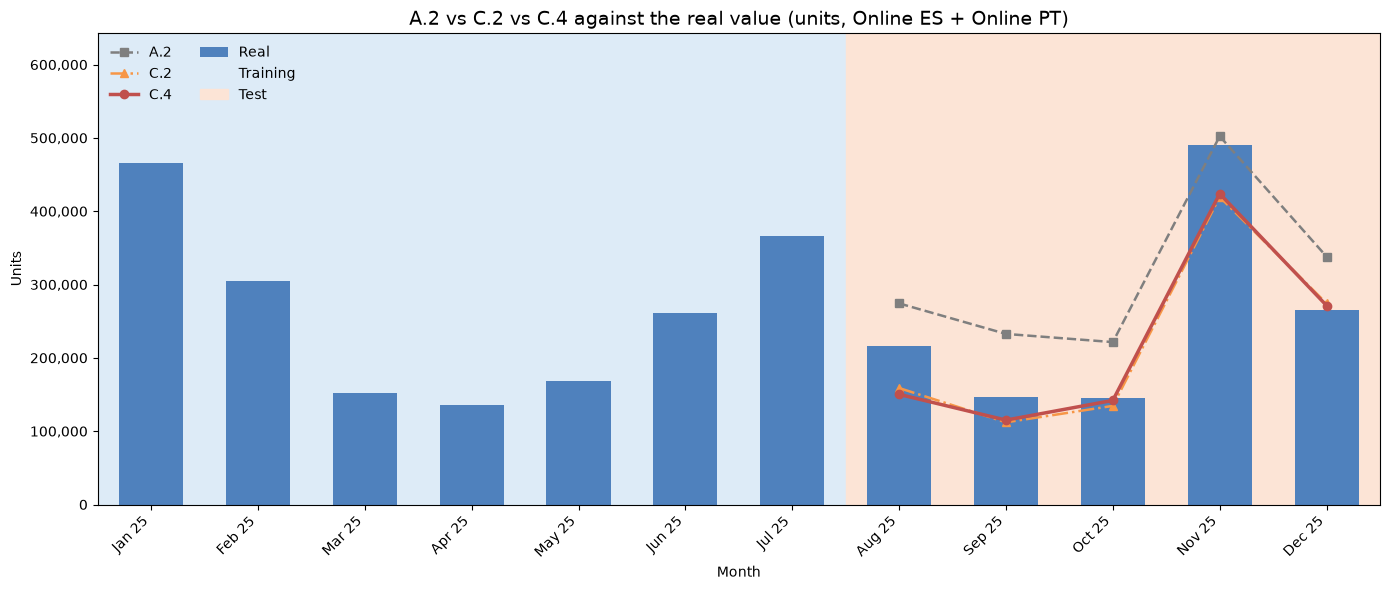

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,A.2,23.40,13.46,"1,625.14",0.91
units,A.2,32.80,24.17,"4,263.82",0.90
orders,C.2,18.15,-6.44,"1,335.57",0.94
units,C.2,23.22,-13.01,"4,016.50",0.91
orders,C.4,17.47,-6.44,"1,335.42",0.94
units,C.4,22.65,-12.73,"3,970.21",0.91


2. Change from A.2 to each model (negative WAPE and RMSE changes = better than A.2):


WAPE_pct change  Bias_pct change  RMSE change  R2 change
target model                                                          
orders C.2              -5.26           -19.91      -289.57       0.03
       C.4              -5.94           -19.91      -289.72       0.03
units  C.2              -9.58           -37.18      -247.32       0.01
       C.4             -10.15           -36.90      -293.61       0.01

3. Daily error by month - WAPE (%):


model            A.2   C.2   C.4
target month                    
orders 2025-08 20.89 19.29 19.07
       2025-09 37.85 21.53 18.87
       2025-10 32.27 12.44 13.47
       2025-11 17.26 14.24 13.45
       2025-12 20.42 24.06 23.35
units  2025-08 28.09 27.76 30.91
       2025-09 57.98 23.96 22.08
       2025-10 52.56 15.77 12.92
       2025-11 19.68 20.43 19.44
       2025-12 36.07 28.36 27.49

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model            A.2    C.2    C.4
target month                      
orders 2025-08 19.33 -16.76 -17.22
       2025-09 37.85 -20.67 -17.66
       2025-10 31.97   2.50   4.67
       2025-11 -2.84  -5.02  -5.97
       2025-12  7.84   1.35   0.06
units  2025-08 27.01 -26.44 -30.43
       2025-09 57.98 -23.90 -21.84
       2025-10 52.56  -7.36  -2.19
       2025-11  2.45 -14.43 -13.54
       2025-12 27.68   3.55   2.48

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast                  error                \
model                       A.2     C.2     C.4    A.2    C.2    C.4   
target month                                                           
orders 2025-08  109819   131047   91418   90910  21228 -18401 -18909   
       2025-09   92480   127483   73367   76147  35003 -19113 -16333   
       2025-10   93177   122968   95509   97526  29791   2332   4349   
       2025-11  226443   220002  215065  212916  -6441 -11378 -13527   
       2025-12  165749   178751  167994  165851  13002   2245    102   
units  2025-08  215951   274285  158860  150227  58334 -57091 -65724   
       2025-09  147272   232665  112072  115102  85393 -35200 -32170   
       2025-10  145193   221509  134505  142009  76316 -10688  -3184   
       2025-11  490281   502317  419518  423902  12036 -70763 -66379   
       2025-12  264817   338114  274225  271382  73297   9408   6565   

               error_pct                
model                A.2    C.2    C.4  
target month                            
orders 2025-08     19.30 -16.80 -17.20  
       2025-09     37.80 -20.70 -17.70  
       2025-10     32.00   2.50   4.70  
       2025-11     -2.80  -5.00  -6.00  
       2025-12      7.80   1.40   0.10  
units  2025-08     27.00 -26.40 -30.40  
       2025-09     58.00 -23.90 -21.80  
       2025-10     52.60  -7.40  -2.20  
       2025-11      2.50 -14.40 -13.50  
       2025-12     27.70   3.60   2.50

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker)
COMPARE = {
    "A.2": ("it2_predictions", "#7F7F7F", "--", "s"),   # reference: linear regression without recent growth
    "C.2": ("c2_predictions",  "#F79646", "-.", "^"),   # random forest with recent growth, settings chosen manually
    "C.4": ("c4_predictions",  "#C0504D", "-",  "o"),   # random forest with recent growth, settings chosen by cross-validation
}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Chart: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index=["month_start"], columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = c4_daily[TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == "C.4" else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model (A.2)
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
print("1. Overall metrics (all test days pooled):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().sort_index()
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"])
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"])["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### C.4: results

C.4 performs practically the same as C.2, with a slight improvement for both targets: the overall WAPE decreases by less than one percentage point, the RMSE for units falls slightly and the bias is unchanged. The gains are concentrated in September, November and December – in December, the forecast monthly total of orders is almost exact – while August and October remain at a similar level.

This result is important for the reliability of the conclusions. The settings of C.2 were chosen manually, and the design decisions of the previous models were made by comparing results on the test months, which could have made the reported errors optimistic. When the settings are instead chosen by cross-validation, using only the training data of each month, the accuracy is maintained. This shows that the manual settings were not adjusted to the test months, and that the improvement of C.2 over A.2 is genuine.

The remaining errors follow the same pattern as in C.2: August and September are underestimated, as are units in November, when the growth driven by Black Friday was stronger than in the preceding months. These errors result from the information available two months in advance, not from the settings of the model, so cross-validation cannot correct them.

**Conclusion.** C.4 becomes the reference model and the result reported for the machine learning approach, as none of its settings were influenced by the test months.

## D. Gradient Boosting

### Why another type of model
Section C showed that the Random Forest, combined with the recent growth, is the best approach so far, and that choosing its settings by cross-validation (C.4) confirmed the results without improving them significantly. Further changes to the Random Forest are unlikely to bring large gains, so this section tests a different way of combining decision trees: **Gradient Boosting**.

In a Random Forest, many trees are trained independently and their forecasts are averaged. In Gradient Boosting, the trees are trained **one after another**: the first tree makes a simple forecast, and each following tree focuses only on the errors that remain, correcting a small part of them. The final forecast is the sum of all the corrections. This sequential learning is usually more accurate than averaging independent trees, as each tree concentrates on what the previous ones got wrong, but it is also more prone to overfitting, as the last trees may start correcting random fluctuations of the training data instead of real patterns.

### How overfitting is controlled
Three measures limit this risk, which is particularly relevant with the short training period available:
- **Small steps:** each tree corrects only 5% of the remaining error (learning rate of 0.05), so no single tree can change the forecast much.
- **Simple trees:** each tree asks only two or three questions (maximum depth of 2 or 3), and each final answer is based on at least seven days. In addition, each tree is trained on a random 80% of the training days.
- **Stopping at the right time:** the number of trees is not fixed in advance. It is chosen by the same time-series cross-validation used in C.4, which identifies the point at which additional trees stop improving the forecasts in the mini-tests.

The inputs, the recent growth, the target, the forecasting rule, the test months and the metrics are the same as in C.4, so the comparison measures only the effect of the algorithm.

### D.1: Gradient Boosting with cross-validation

For each test month, the model compares two tree depths (2 and 3) and every number of trees from 1 to 600, using the same cross-validation as C.4. To make this efficient, one model with 600 trees is trained per mini-test and its forecast is read after each tree, so all lengths are compared at once. The combination with the lowest average WAPE is selected, and the final model is trained with it on all the training days.

The table of chosen settings shows, for each month, the depth and number of trees selected. A small number of trees means that, in the mini-tests, additional corrections did not improve the forecast: in that case, the forecast relies mainly on the recent growth and the previous year's value, with only a small adjustment from the trees.

In [27]:
# ============================================================
# D.1 - Gradient Boosting: same inputs, recent growth and target as C.4
# Trees are trained one after another, each correcting a small part (5%) of the remaining error.
# For each test month, the tree depth and the number of trees are chosen by time-series
# cross-validation inside the training data only (train on the past, one-month gap, validate on 4 weeks).
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor

# ---------- Configuration ----------
D1_ID = "D.1"                                                          # short name used in the result tables
D1_NAME = "D.1 Gradient Boosting (C.4 inputs, time-series cross-validation)"   # full name used in charts
D1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
D1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
D1_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
D1_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
D1_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
D1_GB_FIXED = dict(
    learning_rate=0.05,      # small steps: each tree corrects only 5% of the remaining error
    subsample=0.8,           # each tree sees a random 80% of the training days (more robust)
    min_samples_leaf=7,      # each final answer is based on at least one week of days
    random_state=42,         # reproducible results
)
D1_DEPTHS = (2, 3)           # simple trees: 2 or 3 questions each (chosen by cross-validation)
D1_MAX_TREES = 600           # longest queue of trees tested; the best length is chosen by cross-validation
D1_DEFAULT = {"max_depth": 3, "n_estimators": 300}   # used if the training period is too short for a mini-test
D1_CV_FOLDS = 3          # up to 3 mini-tests per test month
D1_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
D1_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
D1_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
d1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
d1_daily["day"] = pd.to_datetime(d1_daily["day"])
d1_daily = d1_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(d1_daily)} days, from {d1_daily.index.min().date()} to {d1_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the model)
for t in TARGETS:
    for lag in D1_RECENT_LAGS + [D1_YEARLY_LAG]:
        d1_daily[f"{t}_lag_{lag}"] = d1_daily[t].shift(lag)
    recent = d1_daily[t].rolling(D1_GROWTH_WINDOW).sum().shift(D1_GROWTH_END_LAG)
    recent_last_year = recent.shift(D1_YEARLY_LAG)
    d1_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    d1_daily[f"{t}_ratio"] = d1_daily[t] / d1_daily[f"{t}_lag_{D1_YEARLY_LAG}"].replace(0, np.nan)
    d1_daily[f"{t}_deviation"] = d1_daily[f"{t}_ratio"] / d1_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=d1_daily.index, columns=list(D1_CAMPAIGNS.values()))
for family, col in D1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(D1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
d1_daily = d1_daily.join(camp_diff)
D1_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def d1_features(t):
    return [f"{t}_lag_{lag}" for lag in D1_RECENT_LAGS + [D1_YEARLY_LAG]] + D1_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data
#    The training days are split into successive mini-tests: train on the past, leave a one-month gap,
#    validate on the next 4 weeks. The test months are never used to choose the settings.
def cv_folds(n_days):
    """Positions (train, validation) of up to D1_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(D1_CV_FOLDS):
        valid_end = n_days - k * D1_CV_VALID_DAYS
        valid_start = valid_end - D1_CV_VALID_DAYS
        train_end = valid_start - D1_CV_GAP_DAYS
        if train_end < D1_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def to_volume(deviation, part, t):
    """Convert a forecast deviation into orders/units: deviation x recent growth x previous year."""
    return (deviation * part[f"{t}_recent_growth"].to_numpy()
            * part[f"{t}_lag_{D1_YEARLY_LAG}"].to_numpy())

def choose_params(train_t, t):
    """Choose the tree depth and the number of trees with the lowest average WAPE in the mini-tests.
    For each depth, one model with D1_MAX_TREES trees is trained per mini-test, and its forecast is
    read after every tree (staged_predict), so all queue lengths are compared at once."""
    folds = cv_folds(len(train_t))
    if not folds:
        return D1_DEFAULT, np.nan, 0
    features = d1_features(t)
    best = (None, np.inf)
    for depth in D1_DEPTHS:
        wape_by_trees = []
        for tr, va in folds:
            part_tr, part_va = train_t.iloc[tr], train_t.iloc[va]
            model = GradientBoostingRegressor(n_estimators=D1_MAX_TREES, max_depth=depth, **D1_GB_FIXED)
            model.fit(part_tr[features], part_tr[f"{t}_deviation"])
            actual = part_va[t].to_numpy()
            wape_by_trees.append([
                100 * np.abs(to_volume(dev, part_va, t) - actual).sum() / actual.sum()
                for dev in model.staged_predict(part_va[features])
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)          # average over the mini-tests, for each queue length
        n_trees = int(np.argmin(mean_wape)) + 1
        if mean_wape[n_trees - 1] < best[1]:
            best = ({"max_depth": depth, "n_estimators": n_trees}, mean_wape[n_trees - 1])
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month (settings chosen by cross-validation, then final model on all training days)
d1_results, d1_predictions, d1_importance, d1_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = d1_daily[d1_daily.index <= cutoff]
    test = d1_daily[(d1_daily.index >= month_start) & (d1_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(D1_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = d1_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        params, cv_wape, n_folds = choose_params(train_t, t)
        model = GradientBoostingRegressor(**params, **D1_GB_FIXED).fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = to_volume(model.predict(test[features]), test, t)
        actual = test[t].to_numpy()
        d1_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        d1_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        d1_results.append({
            "model": D1_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{D1_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        d1_predictions.append(pd.DataFrame({
            "model": D1_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

d1_results = pd.DataFrame(d1_results)
d1_predictions = pd.concat(d1_predictions, ignore_index=True)
d1_chosen = pd.DataFrame(d1_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default settings used):")
display(d1_chosen)

# 7. Results
print("\nResults by month:")
display(d1_results)

print("Overall results (all test days pooled):")
d1_overall = pd.DataFrame([
    {"model": D1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in d1_predictions.groupby("target")
])
display(d1_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 8. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in d1_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default settings used):


,target,month,cv_folds,max_depth,n_estimators,cv_WAPE_pct
0,orders,2025-08,1,2,1,29.67
1,units,2025-08,1,2,1,31.07
2,orders,2025-09,2,3,1,39.54
3,units,2025-09,2,3,1,43.16
4,orders,2025-10,3,3,4,32.98
5,units,2025-10,3,3,8,38.54
6,orders,2025-11,3,3,8,21.67
7,units,2025-11,3,3,6,27.18
8,orders,2025-12,3,3,8,13.49
9,units,2025-12,3,3,8,17.48



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,D.1,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,22.98,-22.06,925.96,-1.09
1,D.1,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,31.52,-31.02,"2,454.03",-1.87
2,D.1,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,9.27,8.16,362.56,-0.21
3,D.1,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,9.94,4.46,586.35,-0.48
4,D.1,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,15.14,7.93,538.23,-1.27
5,D.1,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,15.22,7.45,924.08,-1.36
6,D.1,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,19.29,-16.04,"3,149.70",0.92
7,D.1,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,24.16,-22.66,"10,472.45",0.87
8,D.1,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,20.24,-11.91,"1,546.49",-0.26
9,D.1,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,23.02,-11.58,"2,983.64",-0.99


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,D.1,orders,18.20,-9.50,"1,639.51",0.90
1,D.1,units,22.49,-15.15,"4,976.82",0.87


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units
lag_364,60.00,74.80
lag_68,23.80,11.70
lag_66,4.80,1.80
camp_easter_holy_week_vs_ly,2.80,1.80
lag_62,2.40,1.70
lag_67,2.30,0.70
lag_63,2.00,2.20
lag_64,1.60,2.10
lag_65,0.30,3.10
camp_black_friday_vs_ly,0.00,0.00


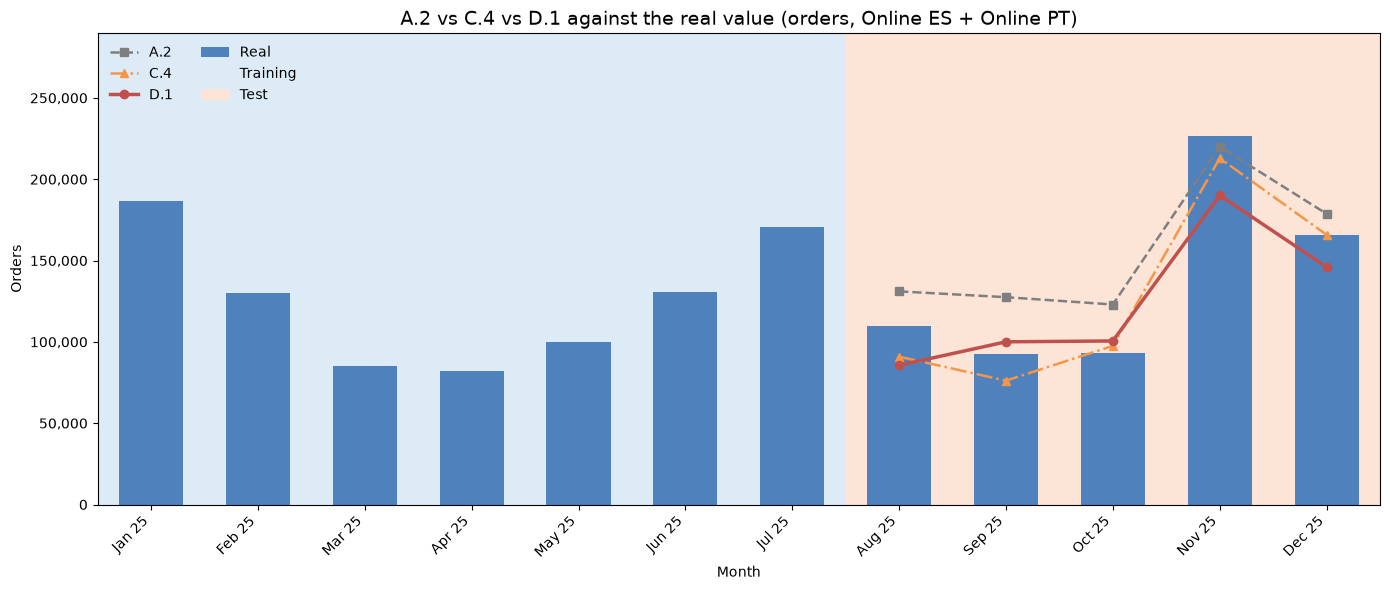

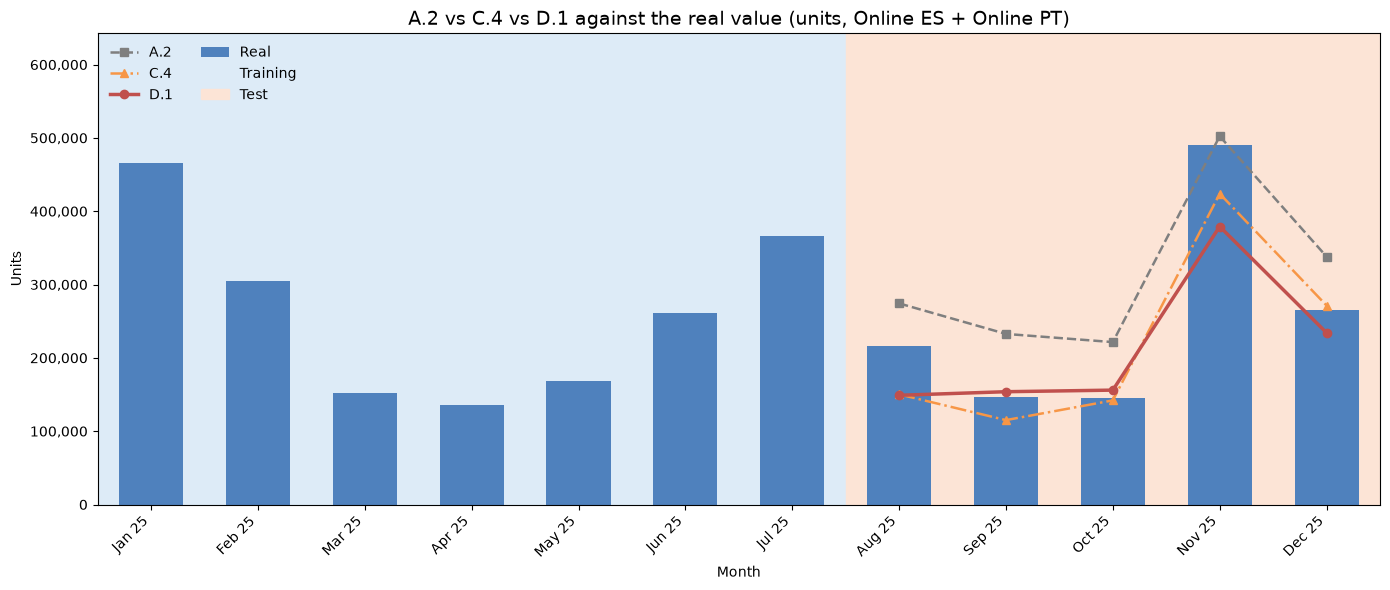

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,A.2,23.40,13.46,"1,625.14",0.91
units,A.2,32.80,24.17,"4,263.82",0.90
orders,C.4,17.47,-6.44,"1,335.42",0.94
units,C.4,22.65,-12.73,"3,970.21",0.91
orders,D.1,18.20,-9.50,"1,639.51",0.90
units,D.1,22.49,-15.15,"4,976.82",0.87


2. Change from A.2 to each model (negative WAPE and RMSE changes = better than A.2):


WAPE_pct change  Bias_pct change  RMSE change  R2 change
target model                                                          
orders C.4              -5.94           -19.91      -289.72       0.03
       D.1              -5.20           -22.97        14.37      -0.00
units  C.4             -10.15           -36.90      -293.61       0.01
       D.1             -10.30           -39.32       713.00      -0.04

3. Daily error by month - WAPE (%):


model            A.2   C.4   D.1
target month                    
orders 2025-08 20.89 19.07 22.98
       2025-09 37.85 18.87  9.27
       2025-10 32.27 13.47 15.14
       2025-11 17.26 13.45 19.29
       2025-12 20.42 23.35 20.24
units  2025-08 28.09 30.91 31.52
       2025-09 57.98 22.08  9.94
       2025-10 52.56 12.92 15.22
       2025-11 19.68 19.44 24.16
       2025-12 36.07 27.49 23.02

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model            A.2    C.4    D.1
target month                      
orders 2025-08 19.33 -17.22 -22.06
       2025-09 37.85 -17.66   8.16
       2025-10 31.97   4.67   7.93
       2025-11 -2.84  -5.97 -16.04
       2025-12  7.84   0.06 -11.91
units  2025-08 27.01 -30.43 -31.02
       2025-09 57.98 -21.84   4.46
       2025-10 52.56  -2.19   7.45
       2025-11  2.45 -13.54 -22.66
       2025-12 27.68   2.48 -11.58

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast                  error                 \
model                       A.2     C.4     D.1    A.2    C.4     D.1   
target month                                                            
orders 2025-08  109819   131047   90910   85588  21228 -18909  -24231   
       2025-09   92480   127483   76147  100028  35003 -16333    7548   
       2025-10   93177   122968   97526  100563  29791   4349    7386   
       2025-11  226443   220002  212916  190132  -6441 -13527  -36311   
       2025-12  165749   178751  165851  146012  13002    102  -19737   
units  2025-08  215951   274285  150227  148955  58334 -65724  -66996   
       2025-09  147272   232665  115102  153847  85393 -32170    6575   
       2025-10  145193   221509  142009  156012  76316  -3184   10819   
       2025-11  490281   502317  423902  379163  12036 -66379 -111118   
       2025-12  264817   338114  271382  234143  73297   6565  -30674   

               error_pct                
model                A.2    C.4    D.1  
target month                            
orders 2025-08     19.30 -17.20 -22.10  
       2025-09     37.80 -17.70   8.20  
       2025-10     32.00   4.70   7.90  
       2025-11     -2.80  -6.00 -16.00  
       2025-12      7.80   0.10 -11.90  
units  2025-08     27.00 -30.40 -31.00  
       2025-09     58.00 -21.80   4.50  
       2025-10     52.60  -2.20   7.50  
       2025-11      2.50 -13.50 -22.70  
       2025-12     27.70   2.50 -11.60

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker)
COMPARE = {
    "A.2": ("it2_predictions", "#7F7F7F", "--", "s"),   # reference: linear regression without recent growth
    "C.4": ("c4_predictions",  "#F79646", "-.", "^"),   # random forest with recent growth and cross-validation
    "D.1": ("d1_predictions",  "#C0504D", "-",  "o"),   # gradient boosting with recent growth and cross-validation
}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Chart: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index=["month_start"], columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = d1_daily[TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == "D.1" else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model (A.2)
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
print("1. Overall metrics (all test days pooled):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().sort_index()
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"])
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"])["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### D.1: results

Gradient Boosting does not improve on C.4. The overall WAPE is practically the same for both targets, but the RMSE is clearly higher, R² is lower and the forecasts are more biased downwards. The error is distributed differently across months: D.1 is much more accurate in September, but less accurate in the peak months. 

**Conclusion.** C.4 remains the reference model: both models have a similar overall error, but C.4 is more reliable in the peak months, which matter most for warehouse planning. The result also confirms the conclusion of section C: with the same information, changing the type of tree-based model does not improve the overall accuracy, as the main limitation is the information available two months in advance rather than the algorithm.

**But, what if we took smaller steps?**

### D.2: Gradient Boosting with smaller learning steps

D.2 repeats D.1 with smaller learning steps: each tree corrects only **1%** of the remaining error, instead of 5%. Smaller steps make each correction more cautious, so about five times more trees are needed to reach the same forecast; the maximum number of trees compared by cross-validation is therefore increased from 600 to 3,000. In general, smaller steps combined with more trees tend to generalise slightly better, as the model approaches the solution gradually and is less influenced by any single tree. Everything else – inputs, recent growth, target, tree depths and cross-validation – is the same as in D.1, so the comparison measures only the effect of the step size.

**Expected limitation.** Gradient Boosting is unlikely to benefit from this change, given the short training period (see C.2). The mini-tests used by the cross-validation cover mostly spring and summer, which contain no strong peaks, so they tend to favour cautious models that stay close to the average. Smaller steps move the model further in the same direction, making each tree even more cautious. Since D.1 already underestimated the peaks of November and December, smaller steps are not expected to correct this; the experiment is included to confirm that the step size is not the limiting factor. With a longer history, including several peak seasons in the training data, a gradual model of this type would be expected to perform better.

In [29]:
# ============================================================
# D.2 - Gradient Boosting with smaller steps: D.1 with a learning rate of 1% instead of 5%
# Trees are trained one after another, each correcting only 1% of the remaining error,
# so about five times more trees are needed to reach the same corrections.
# For each test month, the tree depth and the number of trees are chosen by time-series
# cross-validation inside the training data only (train on the past, one-month gap, validate on 4 weeks).
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor

# ---------- Configuration ----------
D2_ID = "D.2"                                                    # short name used in the result tables
D2_NAME = "D.2 Gradient Boosting (D.1 with 1% learning steps)"   # full name used in charts
D2_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
D2_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
D2_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
D2_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
D2_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
D2_GB_FIXED = dict(
    learning_rate=0.01,      # smaller steps: each tree corrects only 1% of the remaining error
    subsample=0.8,           # each tree sees a random 80% of the training days (more robust)
    min_samples_leaf=7,      # each final answer is based on at least one week of days
    random_state=42,         # reproducible results
)
D2_DEPTHS = (2, 3)           # simple trees: 2 or 3 questions each (chosen by cross-validation)
D2_MAX_TREES = 3000          # 5x longer queue than D.1, so that the smaller steps can reach the same corrections
D2_DEFAULT = {"max_depth": 3, "n_estimators": 1500}   # used if the training period is too short for a mini-test
D2_CV_FOLDS = 3          # up to 3 mini-tests per test month
D2_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
D2_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
D2_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
d2_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
d2_daily["day"] = pd.to_datetime(d2_daily["day"])
d2_daily = d2_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(d2_daily)} days, from {d2_daily.index.min().date()} to {d2_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the model)
for t in TARGETS:
    for lag in D2_RECENT_LAGS + [D2_YEARLY_LAG]:
        d2_daily[f"{t}_lag_{lag}"] = d2_daily[t].shift(lag)
    recent = d2_daily[t].rolling(D2_GROWTH_WINDOW).sum().shift(D2_GROWTH_END_LAG)
    recent_last_year = recent.shift(D2_YEARLY_LAG)
    d2_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    d2_daily[f"{t}_ratio"] = d2_daily[t] / d2_daily[f"{t}_lag_{D2_YEARLY_LAG}"].replace(0, np.nan)
    d2_daily[f"{t}_deviation"] = d2_daily[f"{t}_ratio"] / d2_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=d2_daily.index, columns=list(D2_CAMPAIGNS.values()))
for family, col in D2_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(D2_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
d2_daily = d2_daily.join(camp_diff)
D2_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def d2_features(t):
    return [f"{t}_lag_{lag}" for lag in D2_RECENT_LAGS + [D2_YEARLY_LAG]] + D2_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data
#    The training days are split into successive mini-tests: train on the past, leave a one-month gap,
#    validate on the next 4 weeks. The test months are never used to choose the settings.
def cv_folds(n_days):
    """Positions (train, validation) of up to D2_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(D2_CV_FOLDS):
        valid_end = n_days - k * D2_CV_VALID_DAYS
        valid_start = valid_end - D2_CV_VALID_DAYS
        train_end = valid_start - D2_CV_GAP_DAYS
        if train_end < D2_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def to_volume(deviation, part, t):
    """Convert a forecast deviation into orders/units: deviation x recent growth x previous year."""
    return (deviation * part[f"{t}_recent_growth"].to_numpy()
            * part[f"{t}_lag_{D2_YEARLY_LAG}"].to_numpy())

def choose_params(train_t, t):
    """Choose the tree depth and the number of trees with the lowest average WAPE in the mini-tests.
    For each depth, one model with D2_MAX_TREES trees is trained per mini-test, and its forecast is
    read after every tree (staged_predict), so all queue lengths are compared at once."""
    folds = cv_folds(len(train_t))
    if not folds:
        return D2_DEFAULT, np.nan, 0
    features = d2_features(t)
    best = (None, np.inf)
    for depth in D2_DEPTHS:
        wape_by_trees = []
        for tr, va in folds:
            part_tr, part_va = train_t.iloc[tr], train_t.iloc[va]
            model = GradientBoostingRegressor(n_estimators=D2_MAX_TREES, max_depth=depth, **D2_GB_FIXED)
            model.fit(part_tr[features], part_tr[f"{t}_deviation"])
            actual = part_va[t].to_numpy()
            wape_by_trees.append([
                100 * np.abs(to_volume(dev, part_va, t) - actual).sum() / actual.sum()
                for dev in model.staged_predict(part_va[features])
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)          # average over the mini-tests, for each queue length
        n_trees = int(np.argmin(mean_wape)) + 1
        if mean_wape[n_trees - 1] < best[1]:
            best = ({"max_depth": depth, "n_estimators": n_trees}, mean_wape[n_trees - 1])
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month (settings chosen by cross-validation, then final model on all training days)
d2_results, d2_predictions, d2_importance, d2_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = d2_daily[d2_daily.index <= cutoff]
    test = d2_daily[(d2_daily.index >= month_start) & (d2_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(D2_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = d2_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        params, cv_wape, n_folds = choose_params(train_t, t)
        model = GradientBoostingRegressor(**params, **D2_GB_FIXED).fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = to_volume(model.predict(test[features]), test, t)
        actual = test[t].to_numpy()
        d2_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        d2_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        d2_results.append({
            "model": D2_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{D2_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        d2_predictions.append(pd.DataFrame({
            "model": D2_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

d2_results = pd.DataFrame(d2_results)
d2_predictions = pd.concat(d2_predictions, ignore_index=True)
d2_chosen = pd.DataFrame(d2_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default settings used):")
display(d2_chosen)

# 7. Results
print("\nResults by month:")
display(d2_results)

print("Overall results (all test days pooled):")
d2_overall = pd.DataFrame([
    {"model": D2_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in d2_predictions.groupby("target")
])
display(d2_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 8. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in d2_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default settings used):


,target,month,cv_folds,max_depth,n_estimators,cv_WAPE_pct
0,orders,2025-08,1,2,1,29.08
1,units,2025-08,1,2,1,30.52
2,orders,2025-09,2,3,1,39.31
3,units,2025-09,2,3,1,42.90
4,orders,2025-10,3,3,18,33.18
5,units,2025-10,3,3,3,38.51
6,orders,2025-11,3,2,56,21.85
7,units,2025-11,3,3,27,27.36
8,orders,2025-12,3,3,48,13.90
9,units,2025-12,3,3,38,17.38



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,D.2,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,23.44,-22.63,941.54,-1.16
1,D.2,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,31.53,-31.13,"2,456.61",-1.87
2,D.2,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,10.36,9.78,392.59,-0.41
3,D.2,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,10.16,5.61,613.82,-0.62
4,D.2,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,16.05,8.83,566.55,-1.51
5,D.2,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,19.48,13.91,"1,077.45",-2.21
6,D.2,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,16.86,-13.55,"2,787.76",0.94
7,D.2,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,25.02,-23.48,"10,762.15",0.86
8,D.2,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,20.34,-10.84,"1,551.16",-0.27
9,D.2,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,22.97,-11.79,"2,974.38",-0.98


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,D.2,orders,17.77,-8.18,"1,512.03",0.92
1,D.2,units,23.34,-14.65,"5,102.45",0.86


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units
lag_364,62.30,75.50
lag_68,19.40,12.20
lag_67,4.90,0.70
camp_easter_holy_week_vs_ly,4.00,1.90
lag_66,2.70,1.30
lag_64,2.20,1.90
lag_63,2.10,1.60
lag_62,1.90,1.90
lag_65,0.40,3.20
camp_black_friday_vs_ly,0.00,0.00


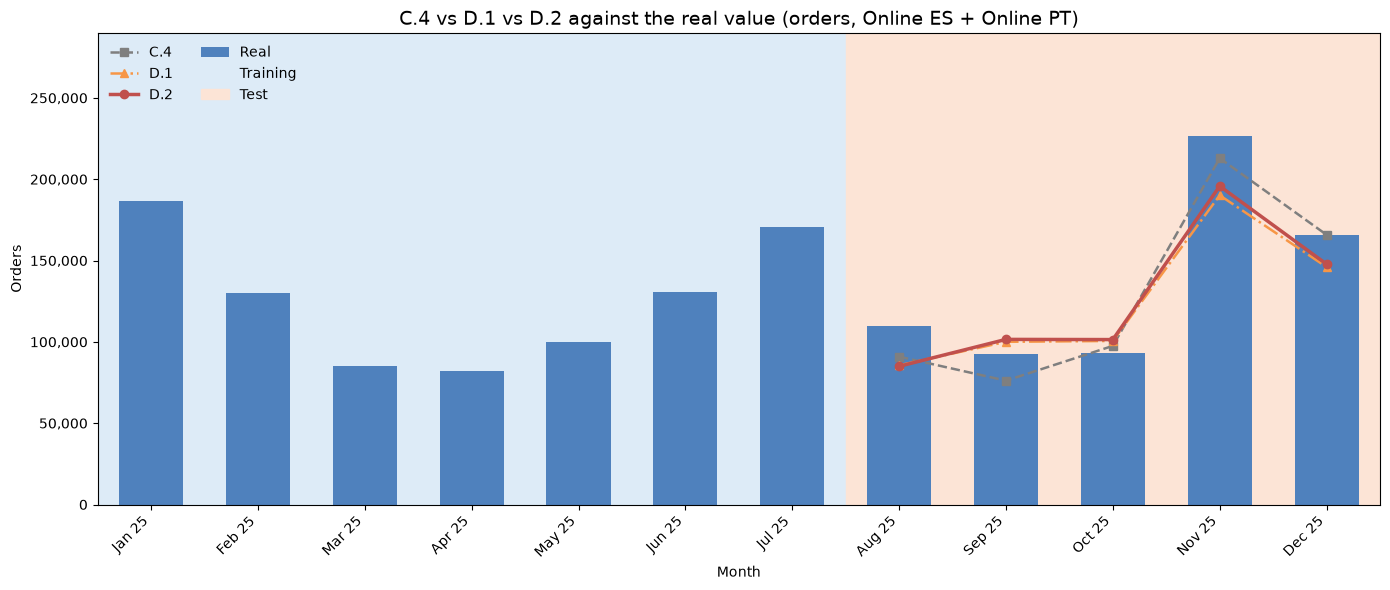

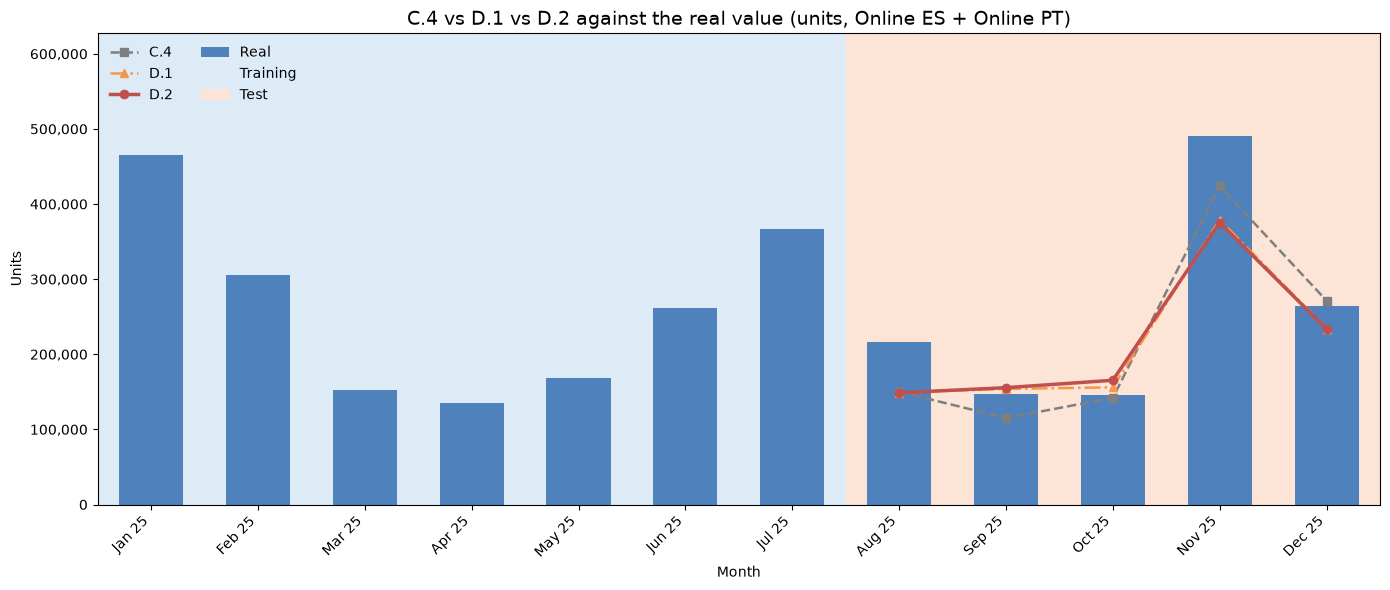

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,C.4,17.47,-6.44,"1,335.42",0.94
units,C.4,22.65,-12.73,"3,970.21",0.91
orders,D.1,18.20,-9.50,"1,639.51",0.90
units,D.1,22.49,-15.15,"4,976.82",0.87
orders,D.2,17.77,-8.18,"1,512.03",0.92
units,D.2,23.34,-14.65,"5,102.45",0.86


2. Change from C.4 to each model (negative WAPE and RMSE changes = better than C.4):


WAPE_pct change  Bias_pct change  RMSE change  R2 change
target model                                                          
orders D.1               0.73            -3.06       304.09      -0.03
       D.2               0.30            -1.73       176.61      -0.02
units  D.1              -0.15            -2.41     1,006.61      -0.05
       D.2               0.69            -1.92     1,132.24      -0.06

3. Daily error by month - WAPE (%):


model            C.4   D.1   D.2
target month                    
orders 2025-08 19.07 22.98 23.44
       2025-09 18.87  9.27 10.36
       2025-10 13.47 15.14 16.05
       2025-11 13.45 19.29 16.86
       2025-12 23.35 20.24 20.34
units  2025-08 30.91 31.52 31.53
       2025-09 22.08  9.94 10.16
       2025-10 12.92 15.22 19.48
       2025-11 19.44 24.16 25.02
       2025-12 27.49 23.02 22.97

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model             C.4    D.1    D.2
target month                       
orders 2025-08 -17.22 -22.06 -22.63
       2025-09 -17.66   8.16   9.78
       2025-10   4.67   7.93   8.83
       2025-11  -5.97 -16.04 -13.55
       2025-12   0.06 -11.91 -10.84
units  2025-08 -30.43 -31.02 -31.13
       2025-09 -21.84   4.46   5.61
       2025-10  -2.19   7.45  13.91
       2025-11 -13.54 -22.66 -23.48
       2025-12   2.48 -11.58 -11.79

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast                  error                  \
model                       C.4     D.1     D.2    C.4     D.1     D.2   
target month                                                             
orders 2025-08  109819    90910   85588   84972 -18909  -24231  -24847   
       2025-09   92480    76147  100028  101522 -16333    7548    9042   
       2025-10   93177    97526  100563  101405   4349    7386    8228   
       2025-11  226443   212916  190132  195762 -13527  -36311  -30681   
       2025-12  165749   165851  146012  147780    102  -19737  -17969   
units  2025-08  215951   150227  148955  148736 -65724  -66996  -67215   
       2025-09  147272   115102  153847  155538 -32170    6575    8266   
       2025-10  145193   142009  156012  165386  -3184   10819   20193   
       2025-11  490281   423902  379163  375177 -66379 -111118 -115104   
       2025-12  264817   271382  234143  233589   6565  -30674  -31228   

               error_pct                
model                C.4    D.1    D.2  
target month                            
orders 2025-08    -17.20 -22.10 -22.60  
       2025-09    -17.70   8.20   9.80  
       2025-10      4.70   7.90   8.80  
       2025-11     -6.00 -16.00 -13.50  
       2025-12      0.10 -11.90 -10.80  
units  2025-08    -30.40 -31.00 -31.10  
       2025-09    -21.80   4.50   5.60  
       2025-10     -2.20   7.50  13.90  
       2025-11    -13.50 -22.70 -23.50  
       2025-12      2.50 -11.60 -11.80

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker)
COMPARE = {
    "C.4": ("c4_predictions",  "#7F7F7F", "--", "s"),   # reference: random forest with recent growth and cross-validation
    "D.1": ("d1_predictions",  "#F79646", "-.", "^"),   # gradient boosting, learning steps of 5%
    "D.2": ("d2_predictions",  "#C0504D", "-",  "o"),   # gradient boosting, learning steps of 1%
}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Chart: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index=["month_start"], columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = d2_daily[TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == "D.2" else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model (C.4)
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
print("1. Overall metrics (all test days pooled):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().sort_index()
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"])
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"])["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### D.2: results

Reducing the learning steps from 5% to 1% has very little effect: D.2 performs practically the same as D.1, and the monthly forecasts of the two models almost overlap. For orders, D.2 is slightly more accurate than D.1, mainly because it underestimates November a little less; for units, it is slightly less accurate, especially in October. The underestimation of the peak months remains: units in November and both targets in December are forecast too low by a similar margin as in D.1, while C.4 forecasts these months much more accurately.

This confirms the expectation stated in the introduction: the step size is not what limits Gradient Boosting with this data, as its behaviour is determined by the short training period without strong peaks.

### D.3: XGBoost

XGBoost is one of the frameworks recommended for structured data in the course materials (Data Architecture & Platforms, Day 3). It is an implementation of the same method used in D.1 – trees trained one after another, each correcting part of the remaining error – but adds **regularisation**: a penalty on large corrections, which makes each tree more cautious and reduces the risk of overfitting. It also uses additional information about the error when choosing each split and samples both the training days and the features for each tree.

Regularisation is the main difference from D.1 and is particularly relevant here, as the training period is short. D.3 therefore keeps the inputs, the recent growth, the target, the learning steps of 5% and the cross-validation of D.1, and adds the regularisation strength to the settings compared: for each test month, the cross-validation chooses the tree depth (2 or 3), the regularisation strength (low or high) and the number of trees (from 50 to 600, in steps of 50).

**Expected result.** D.1 and D.2 showed that the limitation of Gradient Boosting with this data is the short training period without strong peaks, rather than the details of the algorithm. Regularisation makes the model more cautious, which helps against overfitting but is not expected to correct the underestimation of the peak months. The experiment is included to confirm whether the improvements of XGBoost over the standard implementation change this conclusion.

In [31]:
# ============================================================
# D.3 - XGBoost: Gradient Boosting with regularisation, same inputs, recent growth and target as D.1
# Trees are trained one after another, each correcting a small part (5%) of the remaining error;
# the regularisation penalises large corrections, which reduces overfitting with few training days.
# For each test month, the tree depth, the regularisation strength and the number of trees are chosen by
# time-series cross-validation inside the training data only (train on the past, one-month gap, validate on 4 weeks).
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
try:
    from xgboost import XGBRegressor
except ModuleNotFoundError:
    raise RuntimeError("xgboost is not installed: run %pip install xgboost in a cell and restart the kernel.")

# ---------- Configuration ----------
D3_ID = "D.3"                                                          # short name used in the result tables
D3_NAME = "D.3 XGBoost (D.1 + regularisation, time-series cross-validation)"   # full name used in charts
D3_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
D3_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
D3_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
D3_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
D3_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
D3_XGB_FIXED = dict(
    learning_rate=0.05,      # small steps: each tree corrects only 5% of the remaining error
    subsample=0.8,           # each tree sees a random 80% of the training days
    colsample_bytree=0.8,    # each tree sees a random 80% of the features
    min_child_weight=7,      # each final answer is based on at least about one week of days
    tree_method="hist",      # fast training method
    random_state=42,         # reproducible results
    n_jobs=1,                # one processor: faster than several with such small tables
)
D3_PARAM_GRID = [            # settings compared by cross-validation
    {"max_depth": d, "reg_lambda": l} for d in (2, 3) for l in (1, 10)
]                            # reg_lambda = regularisation strength (higher = more cautious corrections)
D3_MAX_TREES = 600           # longest queue of trees tested; the best length is chosen by cross-validation
D3_TREE_STEP = 50            # queue lengths compared in steps of 50 trees (50, 100, ..., 600)
D3_DEFAULT = {"max_depth": 3, "reg_lambda": 1, "n_estimators": 300}   # used if the training period is too short
D3_CV_FOLDS = 3          # up to 3 mini-tests per test month
D3_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
D3_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
D3_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
d3_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
d3_daily["day"] = pd.to_datetime(d3_daily["day"])
d3_daily = d3_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(d3_daily)} days, from {d3_daily.index.min().date()} to {d3_daily.index.max().date()}")

# 2. Lag features, recent growth and target
#    ratio         = value of the day / value of the same weekday of the previous year
#    recent growth = sum of the 28 days ending 62 days before the day / same 28 days of the previous year
#    deviation     = ratio / recent growth (the target of the model)
for t in TARGETS:
    for lag in D3_RECENT_LAGS + [D3_YEARLY_LAG]:
        d3_daily[f"{t}_lag_{lag}"] = d3_daily[t].shift(lag)
    recent = d3_daily[t].rolling(D3_GROWTH_WINDOW).sum().shift(D3_GROWTH_END_LAG)
    recent_last_year = recent.shift(D3_YEARLY_LAG)
    d3_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    d3_daily[f"{t}_ratio"] = d3_daily[t] / d3_daily[f"{t}_lag_{D3_YEARLY_LAG}"].replace(0, np.nan)
    d3_daily[f"{t}_deviation"] = d3_daily[f"{t}_ratio"] / d3_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (same design as in section B)
#    +1 = campaign on the day but not on the equivalent day last year; -1 = the opposite; 0 = same situation
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=d3_daily.index, columns=list(D3_CAMPAIGNS.values()))
for family, col in D3_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(D3_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
d3_daily = d3_daily.join(camp_diff)
D3_CAMP = list(camp_diff.columns)

print("\nCampaign days in 2025 that differ from the previous year:")
diff_2025 = camp_diff[camp_diff.index.year == 2025]
display(pd.DataFrame({"days_+1": (diff_2025 == 1).sum(), "days_-1": (diff_2025 == -1).sum()}).rename_axis("feature"))

def d3_features(t):
    return [f"{t}_lag_{lag}" for lag in D3_RECENT_LAGS + [D3_YEARLY_LAG]] + D3_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data
#    The training days are split into successive mini-tests: train on the past, leave a one-month gap,
#    validate on the next 4 weeks. The test months are never used to choose the settings.
def cv_folds(n_days):
    """Positions (train, validation) of up to D3_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(D3_CV_FOLDS):
        valid_end = n_days - k * D3_CV_VALID_DAYS
        valid_start = valid_end - D3_CV_VALID_DAYS
        train_end = valid_start - D3_CV_GAP_DAYS
        if train_end < D3_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def to_volume(deviation, part, t):
    """Convert a forecast deviation into orders/units: deviation x recent growth x previous year."""
    return (deviation * part[f"{t}_recent_growth"].to_numpy()
            * part[f"{t}_lag_{D3_YEARLY_LAG}"].to_numpy())

def choose_params(train_t, t):
    """Choose the depth, regularisation and number of trees with the lowest average WAPE in the mini-tests.
    For each combination, one model with D3_MAX_TREES trees is trained per mini-test, and its forecast is
    read after every D3_TREE_STEP trees (iteration_range), so all queue lengths are compared at once."""
    folds = cv_folds(len(train_t))
    if not folds:
        return D3_DEFAULT, np.nan, 0
    features = d3_features(t)
    tree_counts = list(range(D3_TREE_STEP, D3_MAX_TREES + 1, D3_TREE_STEP))
    best = (None, np.inf)
    for params in D3_PARAM_GRID:
        wape_by_trees = []
        for tr, va in folds:
            part_tr, part_va = train_t.iloc[tr], train_t.iloc[va]
            model = XGBRegressor(n_estimators=D3_MAX_TREES, **params, **D3_XGB_FIXED)
            model.fit(part_tr[features], part_tr[f"{t}_deviation"])
            actual = part_va[t].to_numpy()
            wape_by_trees.append([
                100 * np.abs(to_volume(model.predict(part_va[features], iteration_range=(0, n)), part_va, t)
                             - actual).sum() / actual.sum()
                for n in tree_counts
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)          # average over the mini-tests, for each queue length
        i = int(np.argmin(mean_wape))
        if mean_wape[i] < best[1]:
            best = ({**params, "n_estimators": tree_counts[i]}, mean_wape[i])
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month (settings chosen by cross-validation, then final model on all training days)
d3_results, d3_predictions, d3_importance, d3_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = d3_daily[d3_daily.index <= cutoff]
    test = d3_daily[(d3_daily.index >= month_start) & (d3_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(D3_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = d3_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        params, cv_wape, n_folds = choose_params(train_t, t)
        model = XGBRegressor(**params, **D3_XGB_FIXED).fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = to_volume(model.predict(test[features]), test, t)
        actual = test[t].to_numpy()
        d3_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        d3_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        d3_results.append({
            "model": D3_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),          # average growth the model starts from
            "actual_growth": test[t].sum() / test[f"{t}_lag_{D3_YEARLY_LAG}"].sum(),   # growth that actually happened
            **error_metrics(actual, forecast),
        })
        d3_predictions.append(pd.DataFrame({
            "model": D3_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

d3_results = pd.DataFrame(d3_results)
d3_predictions = pd.concat(d3_predictions, ignore_index=True)
d3_chosen = pd.DataFrame(d3_chosen)

print("\nSettings chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default settings used):")
display(d3_chosen)

# 7. Results
print("\nResults by month:")
display(d3_results)

print("Overall results (all test days pooled):")
d3_overall = pd.DataFrame([
    {"model": D3_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in d3_predictions.groupby("target")
])
display(d3_overall)

print("recent_growth = growth vs the previous year known at the time of the forecast (average over the month);")
print("actual_growth = growth vs the previous year that actually happened in the month.")

# 8. Feature importance (average over the test months): which inputs the trees use most
print("Feature importance (share of the error reduction, average over the test months):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in d3_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Campaign days in 2025 that differ from the previous year:


,days_+1,days_-1
feature,,
camp_black_friday_vs_ly,0,0
camp_christmas_vs_ly,2,2
camp_mothers_day_vs_ly,3,0
camp_reyes_vs_ly,2,1
camp_valentines_vs_ly,3,4
camp_easter_holy_week_vs_ly,17,17



Settings chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default settings used):


,target,month,cv_folds,max_depth,reg_lambda,n_estimators,cv_WAPE_pct
0,orders,2025-08,1,3,10,50,37.18
1,units,2025-08,1,3,10,100,39.50
2,orders,2025-09,2,3,10,50,41.09
3,units,2025-09,2,3,10,100,44.45
4,orders,2025-10,3,3,10,100,32.99
5,units,2025-10,3,3,10,150,38.87
6,orders,2025-11,3,2,1,300,22.89
7,units,2025-11,3,2,10,50,30.26
8,orders,2025-12,3,2,1,300,13.52
9,units,2025-12,3,2,1,50,19.60



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,D.3,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,19.54,-17.46,833.99,-0.70
1,D.3,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,25.89,-23.45,"2,100.89",-1.10
2,D.3,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,17.00,-15.82,559.92,-1.88
3,D.3,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,22.47,-21.80,"1,215.90",-5.37
4,D.3,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,12.46,0.24,443.32,-0.54
5,D.3,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,16.26,-9.75,978.28,-1.64
6,D.3,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,16.05,-4.82,"2,508.73",0.95
7,D.3,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,20.87,-15.70,"8,396.90",0.92
8,D.3,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,28.67,-0.16,"1,882.20",-0.87
9,D.3,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,27.97,1.74,"3,360.60",-1.53


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,D.3,orders,19.29,-6.51,"1,481.24",0.92
1,D.3,units,22.87,-13.40,"4,182.27",0.91


recent_growth = growth vs the previous year known at the time of the forecast (average over the month);
actual_growth = growth vs the previous year that actually happened in the month.
Feature importance (share of the error reduction, average over the test months):


,orders,units
lag_364,20.30,27.40
lag_67,14.10,8.80
lag_68,13.80,14.10
camp_easter_holy_week_vs_ly,12.00,6.50
lag_66,9.00,7.80
lag_63,8.70,9.40
lag_64,7.90,9.40
lag_62,7.90,9.10
lag_65,6.30,7.60
camp_black_friday_vs_ly,0.00,0.00


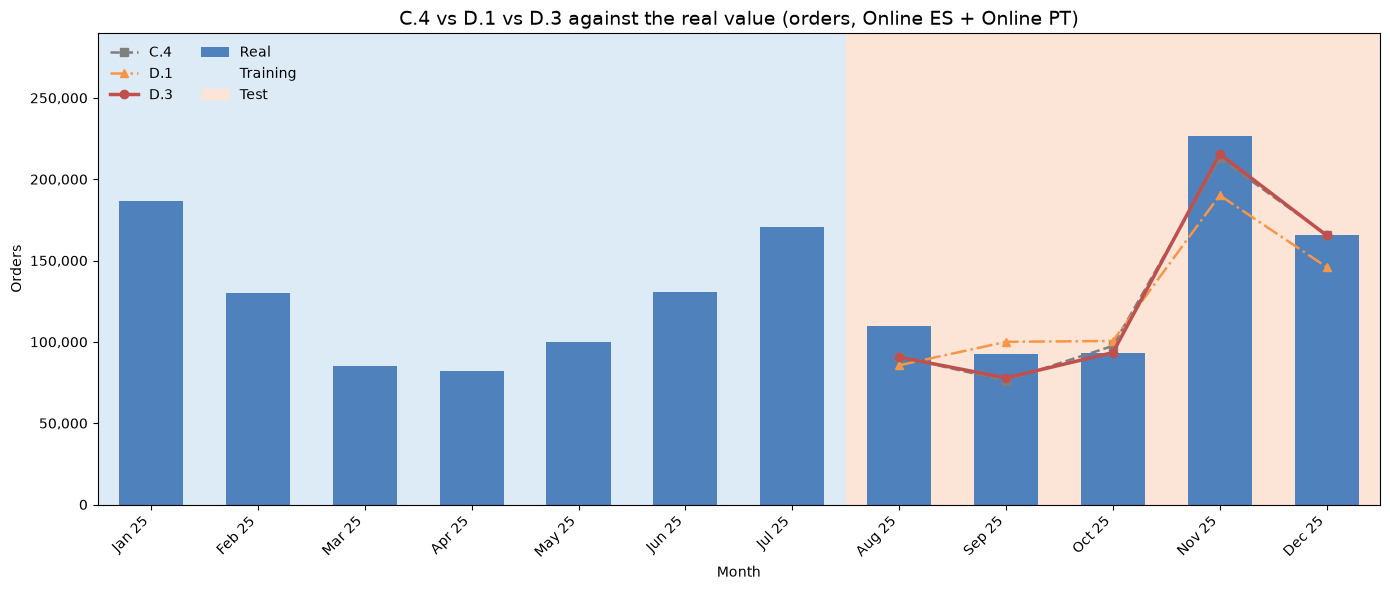

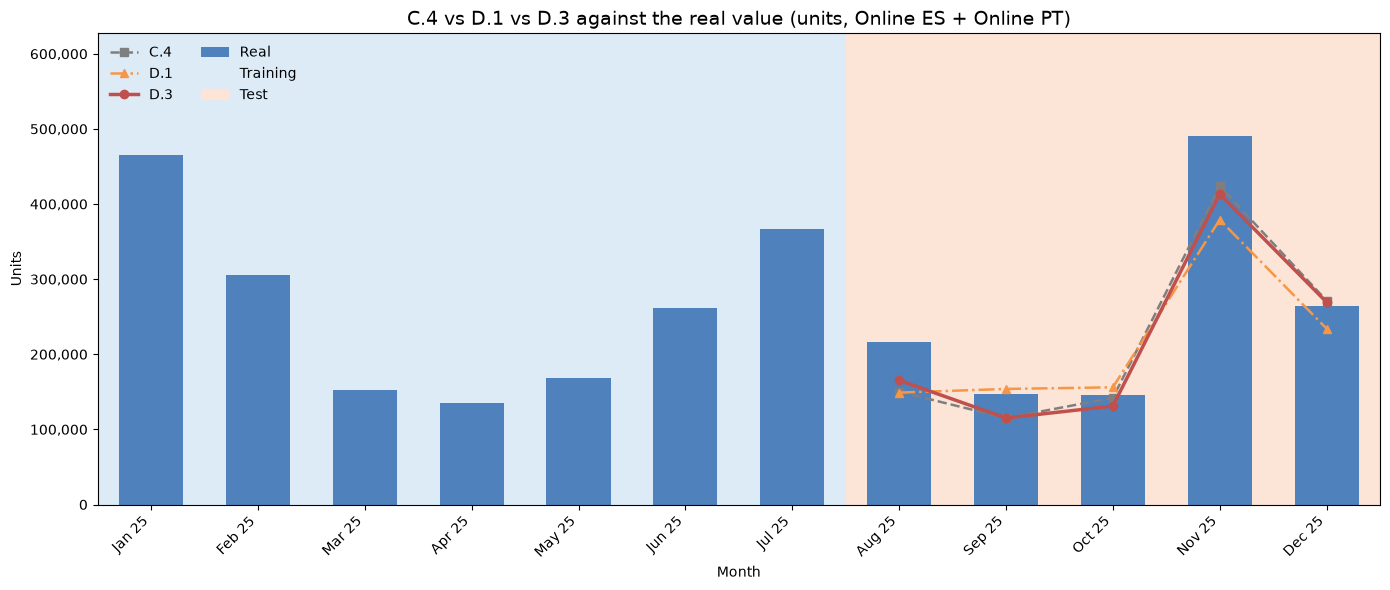

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,C.4,17.47,-6.44,"1,335.42",0.94
units,C.4,22.65,-12.73,"3,970.21",0.91
orders,D.1,18.20,-9.50,"1,639.51",0.90
units,D.1,22.49,-15.15,"4,976.82",0.87
orders,D.3,19.29,-6.51,"1,481.24",0.92
units,D.3,22.87,-13.40,"4,182.27",0.91


2. Change from C.4 to each model (negative WAPE and RMSE changes = better than C.4):


WAPE_pct change  Bias_pct change  RMSE change  R2 change
target model                                                          
orders D.1               0.73            -3.06       304.09      -0.03
       D.3               1.82            -0.07       145.82      -0.01
units  D.1              -0.15            -2.41     1,006.61      -0.05
       D.3               0.23            -0.67       212.07      -0.01

3. Daily error by month - WAPE (%):


model            C.4   D.1   D.3
target month                    
orders 2025-08 19.07 22.98 19.54
       2025-09 18.87  9.27 17.00
       2025-10 13.47 15.14 12.46
       2025-11 13.45 19.29 16.05
       2025-12 23.35 20.24 28.67
units  2025-08 30.91 31.52 25.89
       2025-09 22.08  9.94 22.47
       2025-10 12.92 15.22 16.26
       2025-11 19.44 24.16 20.87
       2025-12 27.49 23.02 27.97

4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):


model             C.4    D.1    D.3
target month                       
orders 2025-08 -17.22 -22.06 -17.46
       2025-09 -17.66   8.16 -15.82
       2025-10   4.67   7.93   0.24
       2025-11  -5.97 -16.04  -4.82
       2025-12   0.06 -11.91  -0.16
units  2025-08 -30.43 -31.02 -23.45
       2025-09 -21.84   4.46 -21.80
       2025-10  -2.19   7.45  -9.75
       2025-11 -13.54 -22.66 -15.70
       2025-12   2.48 -11.58   1.74

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual forecast                  error                 \
model                       C.4     D.1     D.3    C.4     D.1    D.3   
target month                                                            
orders 2025-08  109819    90910   85588   90640 -18909  -24231 -19179   
       2025-09   92480    76147  100028   77850 -16333    7548 -14630   
       2025-10   93177    97526  100563   93402   4349    7386    225   
       2025-11  226443   212916  190132  215520 -13527  -36311 -10923   
       2025-12  165749   165851  146012  165476    102  -19737   -273   
units  2025-08  215951   150227  148955  165302 -65724  -66996 -50649   
       2025-09  147272   115102  153847  115173 -32170    6575 -32099   
       2025-10  145193   142009  156012  131043  -3184   10819 -14150   
       2025-11  490281   423902  379163  413285 -66379 -111118 -76996   
       2025-12  264817   271382  234143  269413   6565  -30674   4596   

               error_pct                
model                C.4    D.1    D.3  
target month                            
orders 2025-08    -17.20 -22.10 -17.50  
       2025-09    -17.70   8.20 -15.80  
       2025-10      4.70   7.90   0.20  
       2025-11     -6.00 -16.00  -4.80  
       2025-12      0.10 -11.90  -0.20  
units  2025-08    -30.40 -31.00 -23.50  
       2025-09    -21.80   4.50 -21.80  
       2025-10     -2.20   7.50  -9.70  
       2025-11    -13.50 -22.70 -15.70  
       2025-12      2.50 -11.60   1.70

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---------- Chart settings ----------
PLOT_FROM = "2025-01"        # first month shown (None = full period); the forecasts only exist in the test months
# model -> (predictions table, colour, line style, marker)
COMPARE = {
    "C.4": ("c4_predictions",  "#7F7F7F", "--", "s"),   # reference: random forest with recent growth and cross-validation
    "D.1": ("d1_predictions",  "#F79646", "-.", "^"),   # gradient boosting (scikit-learn), learning steps of 5%
    "D.3": ("d3_predictions",  "#C0504D", "-",  "o"),   # XGBoost: gradient boosting with regularisation
}
# ------------------------------------

for name, (var, *_style) in COMPARE.items():
    if var not in globals():
        raise RuntimeError(f"{var} not found: run the {name} model cell first.")
preds = pd.concat([globals()[var].assign(model=name) for name, (var, *_s) in COMPARE.items()], ignore_index=True)
preds["day"] = pd.to_datetime(preds["day"])
preds["month_start"] = preds["day"].dt.to_period("M").dt.to_timestamp()
model_names = list(COMPARE)

# 1. Chart: actual monthly totals (bars) and monthly forecast totals of each model (lines)
monthly_fc = preds.pivot_table(index=["month_start"], columns=["model", "target"], values="forecast", aggfunc="sum")
tab_all = d3_daily[TARGETS].resample("MS").sum()
if PLOT_FROM:
    tab_all = tab_all[tab_all.index >= pd.Timestamp(f"{PLOT_FROM}-01")]
months = tab_all.index
x = list(range(len(months)))
first_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[0]}-01"))
last_test = months.get_loc(pd.Timestamp(f"{TEST_MONTHS[-1]}-01"))

for t in TARGETS:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axvspan(-0.5, first_test - 0.5, color='#DDEBF7'); ax.axvspan(first_test - 0.5, last_test + 0.5, color='#FCE4D6')   # training and test
    ax.bar(x, tab_all[t], color='#4F81BD', width=0.6, label='Real')
    values = [tab_all[t].to_numpy(dtype=float)]
    for name in model_names:
        _, colour, style, marker = COMPARE[name]
        series = monthly_fc[(name, t)].reindex(months)
        values.append(series.to_numpy(dtype=float))
        ax.plot(x, series, color=colour, linestyle=style, marker=marker,
                linewidth=2.5 if name == "D.3" else 1.8, label=name)
    ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %y') for m in months], rotation=45, ha='right')
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f'{" vs ".join(model_names)} against the real value ({t}, Online ES + Online PT)', fontsize=14)
    ax.set_xlabel('Month'); ax.set_ylabel(t.capitalize())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.set_ylim(0, np.nanmax(np.concatenate(values)) * 1.28)
    handles, labels = ax.get_legend_handles_labels()
    handles += [Patch(color='#DDEBF7', label='Training'), Patch(color='#FCE4D6', label='Test')]
    ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left', fontsize=10)
    fig.tight_layout()
    plt.show()

# 2. Overall metrics (all test days pooled) and change from the reference model (C.4)
overall = pd.DataFrame([
    {"target": t, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
]).set_index(["target", "model"])
print("1. Overall metrics (all test days pooled):")
display(overall.round(2))

reference = model_names[0]
change = pd.concat({
    m: overall.xs(m, level="model") - overall.xs(reference, level="model") for m in model_names[1:]
}, names=["model"]).swaplevel().sort_index()
change.columns = [f"{c} change" for c in change.columns]
print(f"2. Change from {reference} to each model (negative WAPE and RMSE changes = better than {reference}):")
display(change.round(2))

# 3. Daily error metrics by month: WAPE and Bias side by side
monthly_metrics = pd.DataFrame([
    {"target": t, "month": mo, "model": m, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. Daily error by month - WAPE (%):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Daily error by month - Bias (%) (positive = overestimates, negative = underestimates):")
display(monthly_metrics.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

# 4. Error in the monthly total: actual vs forecast total for the month and the difference
totals = preds.groupby(["target", "month", "model"]).agg(actual=("actual", "sum"), forecast=("forecast", "sum")).reset_index()
totals["error"] = totals["forecast"] - totals["actual"]
totals["error_pct"] = 100 * totals["error"] / totals["actual"]
monthly_totals = totals.pivot_table(index=["target", "month"], columns="model", values=["forecast", "error", "error_pct"])
monthly_totals = monthly_totals[["forecast", "error", "error_pct"]]
for col in monthly_totals.columns:
    monthly_totals[col] = monthly_totals[col].round(1) if col[0] == "error_pct" else monthly_totals[col].round(0).astype(int)
monthly_totals.insert(0, ("actual", ""), totals.groupby(["target", "month"])["actual"].first().round(0).astype(int))
print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
display(monthly_totals)

### D.3: results

The regularised XGBoost brings the forecast back to the level of **C.4** and clearly improves on **D.1**. The two models follow almost the same monthly path. Compared with D.1, D.3 no longer overestimates October and gets much closer to the November and December peaks, especially for orders. September is the exception: like C.4, D.3 underestimates it, while D.1 was closer to the actual volume in that month. The settings chosen by cross-validation show strong regularisation in most months, but weak regularisation in the peak months for orders, and a small number of trees in most months: the forecast stays close to the previous year's value adjusted for recent growth, with limited corrections from the trees.

Some limitations remain, and all models share them:

- **August is underestimated by every model.** The recent growth known at the time of the forecast was close to the growth that actually happened, but the model learned a deviation below the usual level for this period.
- **November units are still underestimated.** Orders are forecast well, but customers buy more units per order during Black Friday than the model expects. Training starts in late March 2025, so it contains no comparable peak to learn from.

## Section D: conclusions

Section D tested whether a more powerful algorithm, **Gradient Boosting**, could improve on the Random Forest of section C. It used the same inputs, the same recent growth and the same target.

**Main findings:**

- **The algorithm is not the bottleneck.** Once the inputs and the target are the same, Random Forest (C.4) and XGBoost (D.3) give very similar results. Changing the algorithm moves the forecast much less than the design choices of sections A to C did (the yearly lag, the recent growth and the deviation target).
- **XGBoost is more stable than the standard implementation.** The plain Gradient Boosting (D.1) was too cautious and underestimated the peaks, as the mini-tests used to choose its settings contain no peak months. XGBoost (D.3) followed the peaks more closely, at least for orders. This is not explained by the regularisation: strong regularisation was chosen in most months, but not in the peak months for orders (November and December), where the weak setting was selected. The difference comes from the other features of the XGBoost implementation, such as the random sampling of the inputs and the way each split is chosen.
- **The remaining errors come from the data, not the model.** Every model shares the same weaknesses: the underestimation of August, the units of Black Friday and the two-month delay in reacting to changes in growth. Training starts in late March 2025 and covers no comparable peak, and a forecast made two months in advance cannot see changes in demand that have not happened yet.

**Model choice:**

**C.4** and **D.3** perform at the same level and are the two best candidates so far:

| | C.4 – Random Forest | D.3 – XGBoost |
|---|---|---|
| Accuracy | Same level overall | Same level overall, slightly better on the peak months for orders |
| Behaviour on peaks | Underestimates the November peak for orders slightly more than D.3, and slightly less for units | Closest to the November and December peaks for orders |
| Simplicity | Easier to explain and to tune | More settings, chosen by cross-validation |

D.3 is retained as the **main model** because it handles the peak months best for orders, which are the most demanding for the warehouse. C.4 is kept as a **simpler alternative** that gives similar accuracy. As more history becomes available, especially a second Black Friday and Christmas in the training data, both models should be retrained and compared again.

## E. Regularised linear model (robustness check)

Section D showed that, with the same inputs, recent growth and target, changing the algorithm moves the forecast very little, and that regularisation helped Gradient Boosting (D.3 vs D.1). One question remains open from section C: did the linear regression (C.3) fail because the model is linear, or because it had no regularisation?

This section answers that question with a single model, a **Ridge regression**, which is a linear regression with regularisation. It is one of the main regression algorithms listed in the scikit-learn documentation. It is compared with the two best models so far, **C.4** (Random Forest) and **D.3** (XGBoost).

Unlike tree-based models, a linear model can forecast values above those seen in training. In theory, this could help on peaks such as Black Friday, where C.4 and D.3 underestimate units. If Ridge does not improve on them, it confirms that the remaining errors come from the data and not from the choice of algorithm.

### E.1: Ridge regression (same inputs and target as D.3, time-series cross-validation)

**How it works:** a linear regression gives each input a weight and adds them up. Ridge adds a penalty on large weights, controlled by the parameter `alpha`. The higher the alpha, the more the weights are pulled towards zero and the more cautious the model becomes. Smaller weights also mean that an unusually large input, such as the Black Friday peak of the previous year carried by the yearly lag, has a smaller effect on the forecast. This is what made the plain linear regression (C.3) fail in November.

**Design (same as D.3, so the comparison is fair):**
- **Inputs:** recent lags (62 to 68), the yearly lag (364) and the fixed campaigns relative to the previous year.
- **Target:** the deviation from the previous year adjusted for recent growth. The forecast is converted back to orders and units with deviation × recent growth × previous year.
- **Scaling:** the inputs are standardised (mean 0, standard deviation 1) before fitting. Ridge penalises all weights equally, so inputs measured in thousands of orders and campaign indicators of ±1 must be on the same scale.
- **Choice of alpha:** for each test month, alpha is chosen with the same cross-validation as C.4.
- Negative forecasts, which a linear model can produce, are set to zero.

In [33]:
# ============================================================
# E.1 - Ridge regression: linear regression with regularisation, same inputs, recent growth and target as D.3
# The inputs are standardised and alpha (regularisation strength) is chosen for each test month by
# time-series cross-validation inside the training data only (train on the past, one-month gap, validate on 4 weeks).
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# ---------- Configuration ----------
E1_ID = "E.1"                                                            # short name used in the result tables
E1_NAME = "E.1 Ridge regression (D.3 inputs, time-series cross-validation)"   # full name used in charts
E1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
E1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
E1_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
E1_GROWTH_END_LAG = 62                    # ...ending 62 days before the day (always known at the time of the forecast)
E1_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
E1_ALPHAS = [0.1, 1, 10, 100, 1000, 10000]   # regularisation strengths compared by cross-validation
E1_DEFAULT_ALPHA = 10                        # used if the training period is too short
E1_CV_FOLDS = 3          # up to 3 mini-tests per test month
E1_CV_VALID_DAYS = 28    # each mini-test covers 4 weeks...
E1_CV_GAP_DAYS = 30      # ...starting one month after the end of its training data, as in the forecasting rule
E1_CV_MIN_TRAIN = 28     # minimum training days in a mini-test
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist (temporary views, lost when the kernel restarts)
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
e1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
e1_daily["day"] = pd.to_datetime(e1_daily["day"])
e1_daily = e1_daily.set_index("day").asfreq("D", fill_value=0)   # every day present, missing days = 0
print(f"Daily series: {len(e1_daily)} days, from {e1_daily.index.min().date()} to {e1_daily.index.max().date()}")

# 2. Lag features, recent growth and target (same definitions as D.3)
for t in TARGETS:
    for lag in E1_RECENT_LAGS + [E1_YEARLY_LAG]:
        e1_daily[f"{t}_lag_{lag}"] = e1_daily[t].shift(lag)
    recent = e1_daily[t].rolling(E1_GROWTH_WINDOW).sum().shift(E1_GROWTH_END_LAG)
    recent_last_year = recent.shift(E1_YEARLY_LAG)
    e1_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    e1_daily[f"{t}_ratio"] = e1_daily[t] / e1_daily[f"{t}_lag_{E1_YEARLY_LAG}"].replace(0, np.nan)
    e1_daily[f"{t}_deviation"] = e1_daily[f"{t}_ratio"] / e1_daily[f"{t}_recent_growth"]

# 3. Fixed campaigns relative to the previous year (+1 / -1 / 0, same design as in section B)
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=e1_daily.index, columns=list(E1_CAMPAIGNS.values()))
for family, col in E1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(E1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
e1_daily = e1_daily.join(camp_diff)
E1_CAMP = list(camp_diff.columns)

def e1_features(t):
    return [f"{t}_lag_{lag}" for lag in E1_RECENT_LAGS + [E1_YEARLY_LAG]] + E1_CAMP

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 5. Time-series cross-validation inside the training data (same logic as TimeSeriesSplit with gap)
def e1_cv_folds(n_days):
    """Positions (train, validation) of up to E1_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    folds = []
    for k in range(E1_CV_FOLDS):
        valid_end = n_days - k * E1_CV_VALID_DAYS
        valid_start = valid_end - E1_CV_VALID_DAYS
        train_end = valid_start - E1_CV_GAP_DAYS
        if train_end < E1_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def e1_to_volume(deviation, part, t):
    """Convert a forecast deviation into orders/units (deviation x recent growth x previous year); no negatives."""
    volume = (deviation * part[f"{t}_recent_growth"].to_numpy()
              * part[f"{t}_lag_{E1_YEARLY_LAG}"].to_numpy())
    return np.clip(volume, 0, None)

def e1_model(alpha):
    """Standardise the inputs, then fit a Ridge regression."""
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

def e1_choose_alpha(train_t, t):
    """Choose the alpha with the lowest average WAPE (in orders/units) in the mini-tests."""
    folds = e1_cv_folds(len(train_t))
    if not folds:
        return E1_DEFAULT_ALPHA, np.nan, 0
    features = e1_features(t)
    best = (None, np.inf)
    for alpha in E1_ALPHAS:
        wapes = []
        for tr, va in folds:
            part_tr, part_va = train_t.iloc[tr], train_t.iloc[va]
            model = e1_model(alpha).fit(part_tr[features], part_tr[f"{t}_deviation"])
            forecast = e1_to_volume(model.predict(part_va[features]), part_va, t)
            actual = part_va[t].to_numpy()
            wapes.append(100 * np.abs(forecast - actual).sum() / actual.sum())
        if np.mean(wapes) < best[1]:
            best = (alpha, np.mean(wapes))
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month (alpha chosen by cross-validation, then final model on all training days)
e1_results, e1_predictions, e1_coefs, e1_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    train = e1_daily[e1_daily.index <= cutoff]
    test = e1_daily[(e1_daily.index >= month_start) & (e1_daily.index <= month_end)]

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (test.index - pd.Timedelta(days=min(E1_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = e1_features(t)
        train_t = train.dropna(subset=features + [f"{t}_deviation"])   # recent growth exists from late March 2025

        alpha, cv_wape, n_folds = e1_choose_alpha(train_t, t)
        model = e1_model(alpha).fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = e1_to_volume(model.predict(test[features]), test, t)
        actual = test[t].to_numpy()
        e1_coefs[(t, month)] = pd.Series(model.named_steps["ridge"].coef_, index=features)
        e1_chosen.append({"target": t, "month": month, "cv_folds": n_folds, "alpha": alpha, "cv_WAPE_pct": cv_wape})

        e1_results.append({
            "model": E1_ID,
            "target": t,
            "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),
            "actual_growth": test[t].sum() / test[f"{t}_lag_{E1_YEARLY_LAG}"].sum(),
            **error_metrics(actual, forecast),
        })
        e1_predictions.append(pd.DataFrame({
            "model": E1_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

e1_results = pd.DataFrame(e1_results)
e1_predictions = pd.concat(e1_predictions, ignore_index=True)
e1_chosen = pd.DataFrame(e1_chosen)

print("\nAlpha chosen by cross-validation for each test month (cv_folds = number of mini-tests;")
print("0 = training period too short, default alpha used):")
display(e1_chosen)

# 7. Results
print("\nResults by month:")
display(e1_results)

print("Overall results (all test days pooled):")
e1_overall = pd.DataFrame([
    {"model": E1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in e1_predictions.groupby("target")
])
display(e1_overall)

# 8. Standardised coefficients (average over the test months): effect of one standard deviation of each input
#    on the deviation; positive = pushes the forecast up, negative = pushes it down
print("Standardised coefficients (average over the test months):")
coefs = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in e1_coefs.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
})
display(coefs.reindex(coefs[TARGETS[0]].abs().sort_values(ascending=False).index).round(4))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Alpha chosen by cross-validation for each test month (cv_folds = number of mini-tests;
0 = training period too short, default alpha used):


,target,month,cv_folds,alpha,cv_WAPE_pct
0,orders,2025-08,1,10000,29.42
1,units,2025-08,1,10000,31.57
2,orders,2025-09,2,10000,39.49
3,units,2025-09,2,10000,43.47
4,orders,2025-10,3,10000,33.42
5,units,2025-10,3,10000,38.90
6,orders,2025-11,3,10000,23.39
7,units,2025-11,3,10000,28.15
8,orders,2025-12,3,1000,14.99
9,units,2025-12,3,100,17.99



Results by month:


,model,target,month,data_up_to,train_from,train_days,recent_growth,actual_growth,WAPE_pct,Bias_pct,RMSE,R2
0,E.1,orders,2025-08,2025-06-30,2025-03-29,94,1.18,1.15,23.61,-22.79,948.31,-1.19
1,E.1,units,2025-08,2025-06-30,2025-03-29,94,1.22,1.22,31.47,-31.07,"2,453.92",-1.87
2,E.1,orders,2025-09,2025-07-31,2025-03-29,125,1.34,1.07,9.70,8.54,373.80,-0.28
3,E.1,units,2025-09,2025-07-31,2025-03-29,125,1.41,1.10,10.39,4.36,605.82,-0.58
4,E.1,orders,2025-10,2025-08-31,2025-03-29,156,1.26,1.04,16.86,9.71,585.53,-1.68
5,E.1,units,2025-10,2025-08-31,2025-03-29,156,1.37,1.04,19.78,14.19,"1,083.94",-2.24
6,E.1,orders,2025-11,2025-09-30,2025-03-29,186,1.12,1.25,22.07,-19.70,"3,660.40",0.89
7,E.1,units,2025-11,2025-09-30,2025-03-29,186,1.17,1.33,25.78,-24.30,"11,138.18",0.85
8,E.1,orders,2025-12,2025-10-31,2025-03-29,217,1.03,1.13,22.45,-15.93,"1,586.87",-0.33
9,E.1,units,2025-12,2025-10-31,2025-03-29,217,1.03,1.08,23.84,-9.47,"3,196.06",-1.29


Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,E.1,orders,20.04,-11.50,"1,848.36",0.88
1,E.1,units,23.86,-14.59,"5,284.42",0.85


Standardised coefficients (average over the test months):


,orders,units
camp_easter_holy_week_vs_ly,-0.00,-0.01
lag_364,0.00,0.01
lag_68,-0.00,-0.01
lag_67,-0.00,-0.00
camp_mothers_day_vs_ly,-0.00,-0.01
lag_66,-0.00,-0.00
lag_65,-0.00,0.00
lag_63,-0.00,0.00
lag_62,-0.00,-0.00
lag_64,-0.00,0.00


Models compared: ['C.4', 'D.3', 'E.1'] | test months: 2025-08 to 2025-12


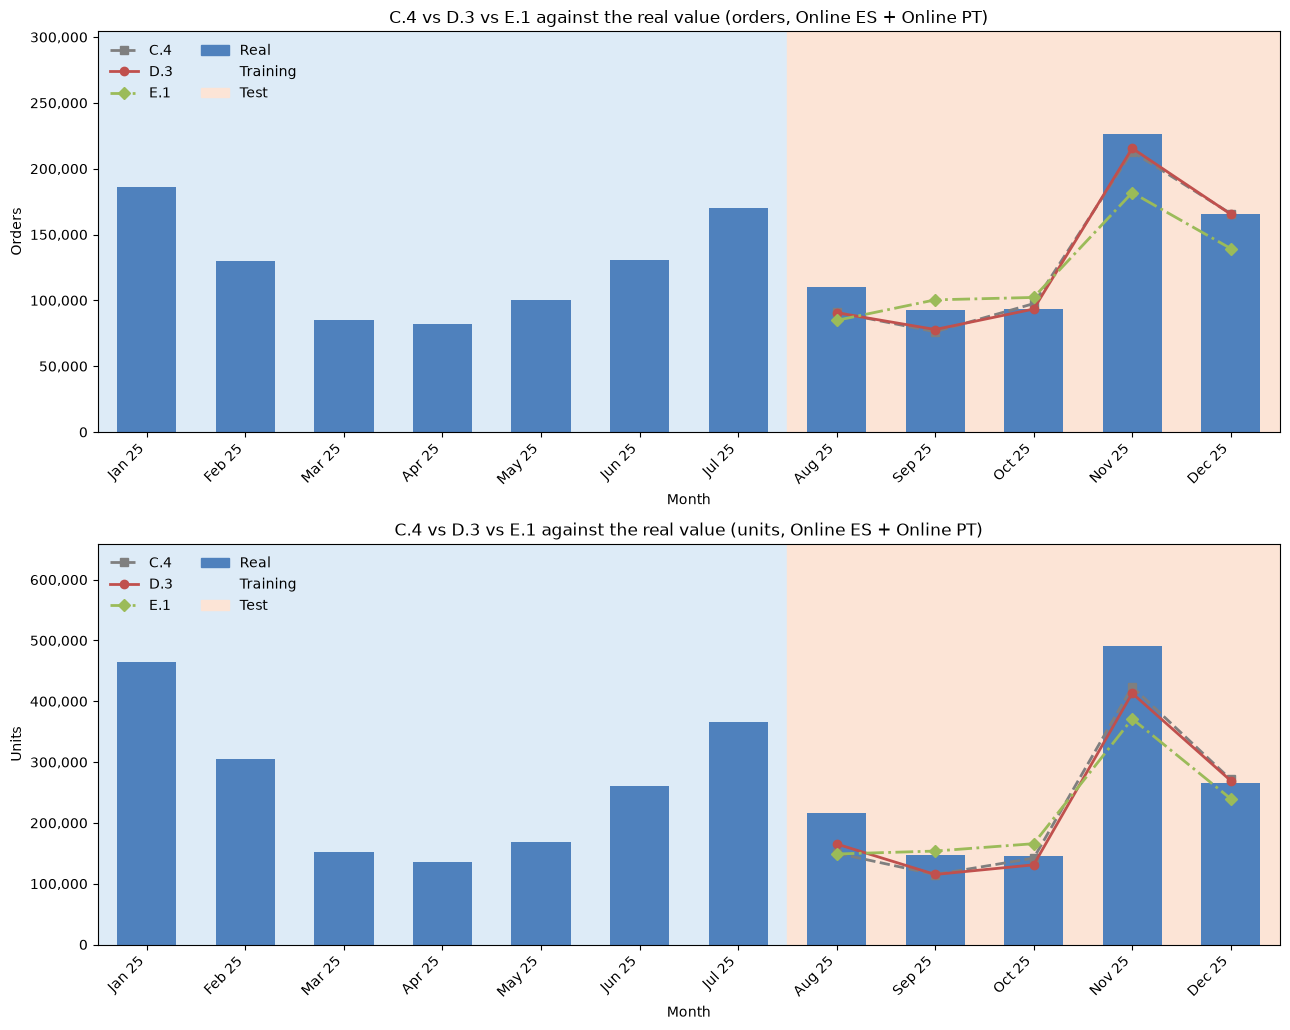

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,C.4,17.47,-6.44,"1,335.42",0.94
units,C.4,22.65,-12.73,"3,970.21",0.91
orders,D.3,19.29,-6.51,"1,481.24",0.92
units,D.3,22.87,-13.40,"4,182.27",0.91
orders,E.1,20.04,-11.50,"1,848.36",0.88
units,E.1,23.86,-14.59,"5,284.42",0.85


2. Change vs D.3 (percentage points for WAPE and Bias; negative WAPE change = better than D.3):


,,WAPE_change_pp,Bias_change_pp
target,model,,
orders,C.4,-1.82,0.07
units,C.4,-0.23,0.67
orders,E.1,0.75,-4.99
units,E.1,0.99,-1.19


3. WAPE by month (%):


model            C.4   D.3   E.1
target month                    
orders 2025-08 19.07 19.54 23.61
       2025-09 18.87 17.00  9.70
       2025-10 13.47 12.46 16.86
       2025-11 13.45 16.05 22.07
       2025-12 23.35 28.67 22.45
units  2025-08 30.91 25.89 31.47
       2025-09 22.08 22.47 10.39
       2025-10 12.92 16.26 19.78
       2025-11 19.44 20.87 25.78
       2025-12 27.49 27.97 23.84

4. Bias by month (%; > 0 overestimates, < 0 underestimates):


model             C.4    D.3    E.1
target month                       
orders 2025-08 -17.22 -17.46 -22.79
       2025-09 -17.66 -15.82   8.54
       2025-10   4.67   0.24   9.71
       2025-11  -5.97  -4.82 -19.70
       2025-12   0.06  -0.16 -15.93
units  2025-08 -30.43 -23.45 -31.07
       2025-09 -21.84 -21.80   4.36
       2025-10  -2.19  -9.75  14.19
       2025-11 -13.54 -15.70 -24.30
       2025-12   2.48   1.74  -9.47

5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual   forecast                            error  \
                                 C.4        D.3        E.1        C.4   
target month                                                            
orders 2025-08 109,819.00  90,910.00  90,640.00  84,787.00 -18,909.00   
       2025-09  92,480.00  76,147.00  77,850.00 100,381.00 -16,333.00   
       2025-10  93,177.00  97,526.00  93,402.00 102,220.00   4,349.00   
       2025-11 226,443.00 212,916.00 215,520.00 181,840.00 -13,527.00   
       2025-12 165,749.00 165,851.00 165,476.00 139,351.00     102.00   
units  2025-08 215,951.00 150,227.00 165,302.00 148,852.00 -65,724.00   
       2025-09 147,272.00 115,102.00 115,173.00 153,688.00 -32,170.00   
       2025-10 145,193.00 142,009.00 131,043.00 165,799.00  -3,184.00   
       2025-11 490,281.00 423,902.00 413,285.00 371,153.00 -66,379.00   
       2025-12 264,817.00 271,382.00 269,413.00 239,729.00   6,565.00   

                                      error_pct                
                      D.3         E.1       C.4    D.3    E.1  
target month                                                   
orders 2025-08 -19,179.00  -25,032.00    -17.20 -17.50 -22.80  
       2025-09 -14,630.00    7,901.00    -17.70 -15.80   8.50  
       2025-10     225.00    9,043.00      4.70   0.20   9.70  
       2025-11 -10,923.00  -44,603.00     -6.00  -4.80 -19.70  
       2025-12    -273.00  -26,398.00      0.10  -0.20 -15.90  
units  2025-08 -50,649.00  -67,099.00    -30.40 -23.50 -31.10  
       2025-09 -32,099.00    6,416.00    -21.80 -21.80   4.40  
       2025-10 -14,150.00   20,606.00     -2.20  -9.70  14.20  
       2025-11 -76,996.00 -119,128.00    -13.50 -15.70 -24.30  
       2025-12   4,596.00  -25,088.00      2.50   1.70  -9.50

In [34]:
# ============================================================
# Comparison: C.4 vs D.3 vs E.1 against the real value (monthly totals)
# Training months shown as bars only; test months show the forecast of each model
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

# ---------- Configuration ----------
COMPARE = {                       # model -> (predictions variable, colour, line style, marker)
    "C.4": ("c4_predictions", "#7F7F7F", "--", "s"),
    "D.3": ("d3_predictions", "#C0504D", "-",  "o"),
    "E.1": ("e1_predictions", "#9BBB59", "-.", "D"),
}
REFERENCE = "D.3"                 # model used as reference in table 2
PLOT_FROM = "2025-01"             # first month shown in the chart
MIN_COVERAGE = 0.9                # months with less than 90% of their days in the data are not shown
TARGETS = ["orders", "units"]
# ----------------------------------

missing = [v for v, *_ in COMPARE.values() if v not in globals()]
if missing:
    raise RuntimeError(f"Run the model cells first: {missing} not found.")

preds = pd.concat([globals()[v] for v, *_ in COMPARE.values()], ignore_index=True)
test_months = sorted(preds["month"].unique())
print(f"Models compared: {list(COMPARE)} | test months: {test_months[0]} to {test_months[-1]}")

# 1. Monthly actual values from the daily series (training + test months)
monthly_actual = e1_daily[TARGETS].copy()
monthly_actual["month"] = monthly_actual.index.to_period("M").astype(str)
coverage = monthly_actual.groupby("month").size() / monthly_actual.groupby("month").apply(
    lambda g: g.index[0].days_in_month)
monthly_actual = monthly_actual.groupby("month")[TARGETS].sum()
monthly_actual = monthly_actual[(monthly_actual.index >= PLOT_FROM) & (monthly_actual.index <= test_months[-1])
                                & (coverage.reindex(monthly_actual.index) >= MIN_COVERAGE)]

monthly_fc = preds.groupby(["model", "target", "month"])["forecast"].sum()

# 2. Chart
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(13, 5.2 * len(TARGETS)))
for ax, t in zip(np.atleast_1d(axes), TARGETS):
    months = list(monthly_actual.index)
    x = np.arange(len(months))
    first_test = months.index(test_months[0])

    ax.axvspan(-0.5, first_test - 0.5, color="#DDEBF7", zorder=0)
    ax.axvspan(first_test - 0.5, len(months) - 0.5, color="#FCE4D6", zorder=0)
    ax.bar(x, monthly_actual[t].values, width=0.6, color="#4F81BD", zorder=2)

    for model, (_, colour, style, marker) in COMPARE.items():
        fc = [monthly_fc.get((model, t, m), np.nan) for m in months]
        ax.plot(x, fc, color=colour, linestyle=style, marker=marker, linewidth=2, markersize=6, zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels(pd.to_datetime(months).strftime("%b %y"), rotation=45, ha="right")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.28)
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f"{' vs '.join(COMPARE)} against the real value ({t}, Online ES + Online PT)")
    ax.set_xlabel("Month")
    ax.set_ylabel(t.capitalize())

    handles = [Line2D([0], [0], color=c, linestyle=s, marker=mk, linewidth=2) for _, c, s, mk in COMPARE.values()]
    handles += [Patch(color="#4F81BD"), Patch(color="#DDEBF7"), Patch(color="#FCE4D6")]
    labels = list(COMPARE) + ["Real", "Training", "Test"]
    ax.legend(handles, labels, loc="upper left", ncol=2, frameon=False)

plt.tight_layout()
plt.show()

# 3. Tables
overall = pd.DataFrame([
    {"model": m, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for (m, t), g in preds.groupby(["model", "target"])
])
print("1. Overall metrics (all test days pooled):")
display(overall.set_index(["target", "model"]).round(2))

print(f"2. Change vs {REFERENCE} (percentage points for WAPE and Bias; negative WAPE change = better than {REFERENCE}):")
ref = overall[overall["model"] == REFERENCE].set_index("target")
change = overall[overall["model"] != REFERENCE].copy()
change["WAPE_change_pp"] = change["WAPE_pct"] - change["target"].map(ref["WAPE_pct"])
change["Bias_change_pp"] = change["Bias_pct"] - change["target"].map(ref["Bias_pct"])
display(change.set_index(["target", "model"])[["WAPE_change_pp", "Bias_change_pp"]].round(2))

by_month = pd.DataFrame([
    {"model": m, "target": t, "month": mo, **error_metrics(g["actual"], g["forecast"])}
    for (m, t, mo), g in preds.groupby(["model", "target", "month"])
])
print("3. WAPE by month (%):")
display(by_month.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("4. Bias by month (%; > 0 overestimates, < 0 underestimates):")
display(by_month.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

print("5. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
totals = preds.groupby(["target", "month", "model"])[["actual", "forecast"]].sum().reset_index()
fc_wide = totals.pivot_table(index=["target", "month"], columns="model", values="forecast")
actual_m = totals.groupby(["target", "month"])["actual"].first()
err = fc_wide.sub(actual_m, axis=0)
err_pct = 100 * err.div(actual_m, axis=0)
table5 = pd.concat({"actual": actual_m.to_frame("") , "forecast": fc_wide, "error": err, "error_pct": err_pct}, axis=1)
display(table5.round({c: 0 for c in table5.columns if c[0] != "error_pct"}).round(
    {c: 1 for c in table5.columns if c[0] == "error_pct"}))

### E.1: results

The regularisation solved the instability of the plain linear regression. Unlike C.3, the Ridge model no longer produces extreme forecasts. This suggests that C.3 failed mainly because its weights were not constrained, rather than because the model is linear (E.1 also standardises the inputs and chooses alpha by cross-validation, which contributes to its stability).

Ridge still does not reach the level of the tree-based models. Overall it is less accurate than C.4 and D.3 for both targets, and its monthly path is flatter:

- **It overestimates September and October,** when growth slowed down, much as D.1 did. September is the only month where it does better than the trees, because the trees underestimated that month.
- **It underestimates the November and December peaks** more than C.4 and D.3, and the expected advantage did not appear. Even though a linear model can forecast above the values seen in training, the regularisation pulls the weights towards zero. Without a comparable peak in the training data, the model has no reason to push the forecast up.

In practice, Ridge behaves close to a rule of "same day last year × recent growth" with small corrections. It adapts less than the trees to the differences between months.

## Section E: conclusions

Section E closed the question left open in section C:

- **Regularisation makes a linear model stable,** but not more accurate than the tree-based models.
- **The tree-based models remain the best choice.** C.4 and D.3 adapt better to the level of each month and follow the peaks more closely.
- **The conclusion of section D still holds.** All the models share the same remaining errors: the underestimation of August and the units of Black Friday. Changing the algorithm does not solve them, because they come from the short training history and from changes in demand that cannot be seen two months in advance.

The model choice does not change: **D.3 (XGBoost)** remains the main model and **C.4 (Random Forest)** the simpler alternative.

## F. Units by product category group

The models so far forecast the daily total of units. Section D showed that the main remaining error for units is the Black Friday peak: orders were forecast well, but customers bought more units per order than expected. Part of this comes from changes in the category mix, which are hidden in the daily total. As seen in the category analysis, some groups gain weight while others lose it, and several have their own seasonal peaks.

This section forecasts units by the six category groups defined in the category analysis (Apparel, Bags & Wallets, Jewellery, Footwear, Accessories and Other). The group forecasts are summed to obtain the daily total, so that the results can be compared with D.3. Orders are not affected: they remain forecast as a daily total by D.3.

The goal is twofold:
1. **Business detail:** for each day, the forecast shows how many units of each type of product the warehouse will handle, which supports planning the picking effort by product type.
2. **Accuracy of the total:** the category level is only kept if the sum of the groups is at least as accurate as the direct forecast of total units.

### Forecasting level for units: total or by product category?

Forecasting the daily total of units is enough to estimate the warehouse workload, but it does not show which types of products make up that volume. A forecast by product category would add this detail, which is useful for planning and for a sales dashboard, as long as it does not reduce the accuracy of the total.

Forecasting by individual product (`PROD_SFK`) is not considered. In fast fashion, products have short life cycles and many of the items sold in the coming weeks are not yet in the history, so they cannot be forecast from their own past sales. In addition, most product-day combinations have no sales at all. The product category (`CAT_DES_EN`) is a more stable level: categories persist across collections and have enough volume to show regular patterns.

A machine learning model can work at this level by using one row per day and category, with the category as a feature, so that a single model learns from all categories at once. The category forecasts can then be summed to obtain the daily total, which keeps the results comparable with the baseline and the deep learning models, as these forecast the total.

Before choosing the level for units, the categories are analysed using `SALE` lines only, in line with the target definition:
1. **Size and coverage of each category**: share of total units, share of days with sales, and whether the category is present in both years. Small or intermittent categories are hard to forecast on their own and may need to be grouped.
2. **Stability of the category mix over time**: the monthly share of units of each category. If shares change with the season, a model by category can capture patterns that are not visible in the total.
3. **Number of categories per order**: to confirm how often a single order includes products from different categories.

In [35]:
# Category analysis - SALE lines only (PT + ES, 2024-2025)

# 1. Summary by category: size, coverage and year-on-year change
cat_summary = con_b.sql("""
    WITH s AS (
        SELECT CAT_DES_EN AS category, CAST(ORDER_DATE AS DATE) AS day, PROD_QTY
        FROM base_ml WHERE "TYPE" = 'SALE'
    ),
    n_days AS (SELECT COUNT(DISTINCT day) AS total_days FROM s),
    daily AS (SELECT category, day, SUM(PROD_QTY) AS units FROM s GROUP BY 1, 2)
    SELECT d.category,
           SUM(units) AS units_total,
           SUM(units) FILTER (WHERE YEAR(day) = 2024) AS units_2024,
           SUM(units) FILTER (WHERE YEAR(day) = 2025) AS units_2025,
           100 * SUM(units) / SUM(SUM(units)) OVER () AS share_pct,
           COUNT(*) AS days_with_sales,
           100 * COUNT(*) / MAX(n.total_days) AS pct_days_with_sales,
           SUM(units) / MAX(n.total_days) AS avg_daily_units,
           MIN(day) AS first_day,
           MAX(day) AS last_day
    FROM daily d CROSS JOIN n_days n
    GROUP BY d.category
    ORDER BY units_total DESC
""").df()
cat_summary["cum_share_pct"] = cat_summary["share_pct"].cumsum()
cat_summary["yoy_change_pct"] = (cat_summary["units_2025"] / cat_summary["units_2024"] - 1) * 100

print("1. Summary by category:")
print("Number of categories:", len(cat_summary))
display(cat_summary)

# 2. Monthly share of each category (% of units sold in the month)
monthly = con_b.sql("""
    SELECT CAST(DATE_TRUNC('month', ORDER_DATE) AS DATE) AS month,
           CAT_DES_EN AS category,
           SUM(PROD_QTY) AS units
    FROM base_ml WHERE "TYPE" = 'SALE'
    GROUP BY 1, 2
""").df()
share = monthly.pivot_table(index="category", columns="month", values="units",
                            aggfunc="sum", fill_value=0)
share = share.div(share.sum(axis=0), axis=1) * 100
share = share.loc[cat_summary["category"]]
share.columns = [c.strftime("%Y-%m") for c in pd.to_datetime(share.columns)]

print("2. Monthly share of units by category (%):")
display(share.round(1))

# 3. Number of distinct categories per order
print("3. Orders by number of distinct categories:")
display(con_b.sql("""
    WITH o AS (
        SELECT ORDER_ID, COUNT(DISTINCT CAT_DES_EN) AS n_categories
        FROM base_ml WHERE "TYPE" = 'SALE'
        GROUP BY 1
    )
    SELECT n_categories,
           COUNT(*) AS n_orders,
           100 * COUNT(*) / SUM(COUNT(*)) OVER () AS pct_orders
    FROM o GROUP BY 1 ORDER BY 1
""").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

1. Summary by category:
Number of categories: 19


,category,units_total,units_2024,units_2025,share_pct,days_with_sales,pct_days_with_sales,avg_daily_units,first_day,last_day,cum_share_pct,yoy_change_pct
0,Apparel,"1,466,847.00","558,625.00","908,222.00",27.45,731,100.00,"2,006.63",2024-01-01,2025-12-31,27.45,62.58
1,Hand Bag,"1,050,873.00","433,579.00","617,294.00",19.67,731,100.00,"1,437.58",2024-01-01,2025-12-31,47.12,42.37
2,Jewellery,"805,787.00","383,552.00","422,235.00",15.08,731,100.00,"1,102.31",2024-01-01,2025-12-31,62.20,10.09
3,Footwear,"805,191.00","318,555.00","486,636.00",15.07,731,100.00,"1,101.49",2024-01-01,2025-12-31,77.26,52.76
4,Wallet,"240,869.00","104,658.00","136,211.00",4.51,731,100.00,329.51,2024-01-01,2025-12-31,81.77,30.15
5,Stainless Steel,"130,306.00","58,169.00","72,137.00",2.44,731,100.00,178.26,2024-01-01,2025-12-31,84.21,24.01
6,Party,"124,466.00","55,827.00","68,639.00",2.33,731,100.00,170.27,2024-01-01,2025-12-31,86.54,22.95
7,Night,"116,478.00","47,694.00","68,784.00",2.18,731,100.00,159.34,2024-01-01,2025-12-31,88.72,44.22
8,Travel,"103,071.00","45,726.00","57,345.00",1.93,731,100.00,141.00,2024-01-01,2025-12-31,90.65,25.41
9,Winter Textiles,"93,806.00","32,350.00","61,456.00",1.76,370,50.62,128.33,2024-01-01,2025-12-31,92.40,89.97


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2. Monthly share of units by category (%):


,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
category,,,,,,,,,,,,,,,,,,,,,,,,
Apparel,20.50,21.90,27.40,20.50,26.10,33.80,27.60,30.30,22.40,32.50,23.00,19.50,27.50,33.80,36.20,31.60,32.60,32.60,30.60,33.50,27.80,28.90,23.90,20.50
Hand Bag,24.20,18.40,16.80,17.40,14.60,15.30,18.20,19.60,18.40,16.50,21.90,23.10,24.30,20.20,13.60,14.20,12.50,13.50,20.50,21.30,20.60,16.70,22.90,22.00
Jewellery,26.10,23.30,16.10,17.10,18.10,18.00,19.80,15.70,14.10,11.20,13.40,13.60,16.10,12.60,14.40,13.40,14.60,15.60,12.90,11.10,12.50,11.50,12.50,13.60
Footwear,6.70,11.70,17.10,20.10,18.00,14.00,14.50,13.30,21.20,20.40,14.50,11.50,13.90,14.10,15.20,19.90,18.70,18.90,17.50,13.70,17.90,21.90,14.60,9.40
Wallet,6.10,4.80,3.90,3.90,3.30,3.60,3.60,3.50,5.10,3.50,5.00,7.30,4.70,4.20,3.50,3.40,3.20,4.10,5.40,4.70,3.40,2.90,4.20,5.90
Stainless Steel,1.90,2.70,2.50,2.90,2.60,2.80,2.50,2.80,2.40,2.00,2.60,3.40,1.80,2.50,3.00,2.40,2.30,2.20,2.10,2.50,2.40,2.10,2.00,3.60
Party,1.20,1.50,2.30,4.40,6.10,3.00,3.00,3.10,3.80,2.10,1.40,1.40,0.70,0.90,2.20,3.30,5.20,3.50,2.30,3.40,4.30,2.90,1.40,1.30
Night,2.20,2.60,1.50,1.30,1.40,1.30,1.50,1.60,2.70,1.80,3.30,2.90,1.40,1.70,1.80,1.50,1.50,1.70,1.90,2.30,1.80,2.00,3.80,3.60
Travel,1.50,1.80,2.90,2.40,1.60,1.30,1.60,1.80,1.60,1.40,3.60,2.30,1.70,1.30,1.70,2.40,1.80,2.10,1.60,1.20,1.60,1.40,2.50,2.30


3. Orders by number of distinct categories:


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_categories,n_orders,pct_orders
0,1,2095593,74.86
1,2,515502,18.42
2,3,139345,4.98
3,4,35548,1.27
4,5,9561,0.34
5,6,2620,0.09
6,7,735,0.03
7,8,262,0.01
8,9,72,0.00
9,10,23,0.00


### Category analysis: summary

The analysis of the 19 product categories led to three conclusions:

1. **Units can be modelled by category.** Sales are concentrated in a few categories, and the category mix changes over time: some categories gain weight while others lose it, and several have their own seasonal peaks. Modelling units by category allows the model to learn these patterns, which are partly hidden in the daily total.
2. **Impact of smaller categories.** Most categories have a small share of units, and modelling each of them separately would produce small and noisy series. Possible ways of grouping them are therefore analysed below, based on volume, business affinity and seasonal pattern.
3. **Orders remain a daily total.** Unlike units, which can be assigned to a single category, an order can include products from several categories: about a quarter of the orders do. Splitting orders by category would count these orders more than once, so the category level applies only to the units target.

As a result, units are modelled with one row per day and category group, and the group forecasts are summed to obtain the daily total, which is compared with the baseline and the deep learning models. 

The forecast therefore provides, for each day, the total number of orders and the number of units in each category group. The average composition of the orders, such as the number of units per order overall and by category group, is derived by dividing the unit forecasts by the order forecast. Individual orders cannot be forecast, but this average profile gives the warehouse the information it needs to plan the picking effort by product type.

### Smaller categories / Grouping

The 19 categories were grouped into six groups. Three criteria guided the grouping:

1. **Volume.** Categories with a large share of units are kept on their own, as they have enough volume to show clear patterns and they drive most of the daily total. Only the smaller categories are grouped.
2. **Business affinity.** Categories are grouped with others of the same product family, so that each group represents a recognisable type of product. The client's website was used as a reference for how products are organised.
3. **Seasonal pattern.** Grouping categories with very different seasonal peaks would blur the patterns that a model by category is meant to learn, so this was taken into account when choosing between possible groupings.

| Group | Categories |
|---|---|
| Apparel | Apparel |
| Bags & Wallets | Hand Bag, Wallet |
| Jewellery | Jewellery |
| Footwear | Footwear |
| Accessories | Hair Accessories, Scarves, Sunglasses, Hats, Watches, Belts, Winter Textiles, Stainless Steel, Silver |
| Other | Party, Night, Travel, Waterproof, Fragrances |

**Main categories.** Apparel, Jewellery and Footwear are kept as separate groups. Together with Hand Bag, they account for most of the units, and each has its own trend or seasonal pattern: Apparel gains weight over the period, Jewellery loses it, and Footwear is weaker in winter.

**Bags & Wallets.** Wallets belong to the same product family as handbags and follow the same pattern, with a peak around Christmas and a similar trend over the period. Grouping them simplifies the model without losing information.

**Accessories.** This group brings together the smaller categories of personal accessories. Winter Textiles was included because, as on the client's website, it belongs to the same family as scarves and hats; it adds a winter pattern to the group. Stainless Steel and Silver are jewellery lines, but they are kept out of the Jewellery group because their behaviour is stable, while Jewellery shows a declining trend that would be diluted by merging them. Belts were also placed here, as they are a personal accessory.

**Other.** This is a residual group of categories with very small individual weight, whose behaviour has little impact on the total. It combines different seasonal patterns, so its forecast should not be read as the behaviour of a single product type; its role is to complete the daily total.

The final output that we expect to receive, would have the following detail: 

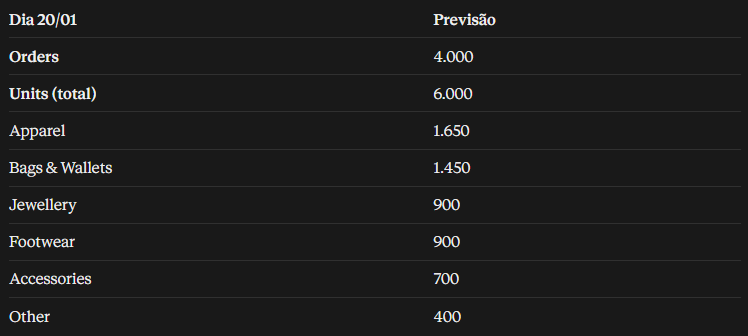

In [36]:
from IPython.display import Image, display

display(Image(filename="Example_forecast_output.png", width=500))

### F.1: XGBoost by category group (D.3 design, one row per day and group)

**Design:** the same design as D.3, applied to each category group:
- **Inputs:** the group's own yearly lag (364) and recent lags (62 to 68), the fixed campaigns relative to the previous year, and the **category group** as an input (one indicator per group).
- **Recent growth and target:** each group has its own recent growth, measured over the same 28-day window, and the target is the deviation of the group from its own previous year adjusted for that growth. If one group grows faster than the others, the model sees it separately instead of averaging it into the total.
- **One model for all groups:** the data has one row per day and group, so a single model learns from all six groups at once. With only a few months of training data, this gives the model six times more examples than separate models per group, and lets it learn patterns shared across groups, such as the effect of campaigns.
- **Weights:** each row is weighted by the group's volume in the previous year, so that the large groups, which drive the daily total, count more than the small ones.
- **Settings:** tree depth, regularisation and number of trees are chosen by time-series cross-validation inside the training data, as in D.3, using the error on the **sum of the groups**.

**Evaluation:**
1. the sum of the groups against the actual total of units, compared with D.3;
2. the error by group, to see which types of products are forecast well.

In [37]:
# ============================================================
# F.1 - XGBoost by category group: D.3 design applied to the units of each category group
# One row per day and group, a single model for all groups, the group as an input,
# rows weighted by the size of the group in the previous year.
# The group forecasts are summed to obtain the daily total of units, compared with D.3.
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
try:
    from xgboost import XGBRegressor
except ModuleNotFoundError:
    raise RuntimeError("xgboost is not installed: run %pip install xgboost in a cell and restart the kernel.")

# ---------- Configuration ----------
F1_ID = "F.1"                                                         # short name used in the result tables
F1_NAME = "F.1 XGBoost by category group (sum of the groups)"         # full name used in charts
F1_GROUPS = {                             # category group -> categories (CAT_DES_EN), as in the category analysis
    "Apparel": ["Apparel"],
    "Bags & Wallets": ["Hand Bag", "Wallet"],
    "Jewellery": ["Jewellery"],
    "Footwear": ["Footwear"],
    "Accessories": ["Hair Accessories", "Scarves", "Sunglasses", "Hats", "Watches", "Belts",
                    "Winter Textiles", "Stainless Steel", "Silver"],
    "Other": ["Party", "Night", "Travel", "Waterproof", "Fragrances"],
}
F1_RECENT_LAGS = list(range(62, 69))      # one full week, always known at the time of the forecast
F1_YEARLY_LAG = 364                       # 52 weeks: same weekday of the previous year
F1_GROWTH_WINDOW = 28                     # recent growth measured over 4 full weeks...
F1_GROWTH_END_LAG = 62                    # ...ending 62 days before the day
F1_CAMPAIGNS = {                          # campaign family (as in events_grouped_v) -> feature name
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
F1_XGB_FIXED = dict(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=7,
                    tree_method="hist", random_state=42, n_jobs=1)          # same as D.3
F1_PARAM_GRID = [{"max_depth": d, "reg_lambda": l} for d in (2, 3) for l in (1, 10)]
F1_MAX_TREES = 600
F1_TREE_STEP = 50
F1_DEFAULT = {"max_depth": 3, "reg_lambda": 1, "n_estimators": 300}
F1_CV_FOLDS = 3
F1_CV_VALID_DAYS = 28
F1_CV_GAP_DAYS = 30
F1_CV_MIN_TRAIN = 28
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

def f1_clean(name):
    """Lower case, single spaces: used to match category names."""
    return " ".join(str(name).lower().split())

F1_MAP = {f1_clean(c): g for g, cats in F1_GROUPS.items() for c in cats}
F1_GROUP_COL = {g: "grp_" + "".join(ch if ch.isalnum() else "_" for ch in g.lower()).replace("__", "_")
                for g in F1_GROUPS}                                          # e.g. "Bags & Wallets" -> grp_bags_wallets

# 0. Check that base_ml and events_grouped_v exist
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily units by category group (SALE lines only)
raw = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day, CAT_DES_EN AS category, SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1, 2
""").df()
raw["group"] = raw["category"].map(lambda c: F1_MAP.get(f1_clean(c)))
unmapped = raw.loc[raw["group"].isna(), "category"].unique()
if len(unmapped):
    raise RuntimeError(f"Categories without a group (add them to F1_GROUPS): {list(unmapped)}")

f1_wide = raw.pivot_table(index="day", columns="group", values="units", aggfunc="sum", fill_value=0)
f1_wide.index = pd.to_datetime(f1_wide.index)
f1_wide = f1_wide.reindex(columns=list(F1_GROUPS), fill_value=0).asfreq("D", fill_value=0)
f1_total = f1_wide.sum(axis=1).rename("units")                 # daily total of units = sum of the groups

total_check = con_b.sql("""SELECT SUM(PROD_QTY) AS u FROM base_ml WHERE "TYPE" = 'SALE'""").df()["u"].iloc[0]
assert abs(f1_total.sum() - total_check) < 1e-6, "The sum of the groups does not match the total units."
print(f"Daily series by group: {len(f1_wide)} days, from {f1_wide.index.min().date()} to {f1_wide.index.max().date()}")

# 2. Fixed campaigns relative to the previous year (+1 / -1 / 0, same design as in section B)
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=f1_wide.index, columns=list(F1_CAMPAIGNS.values()))
for family, col in F1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(F1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
F1_CAMP = list(camp_diff.columns)

# 3. One row per day and group: the group's own lags, recent growth, weight and target
parts = []
for g in F1_GROUPS:
    s = f1_wide[g]
    part = pd.DataFrame({"day": f1_wide.index, "group": g, "units": s.to_numpy()})
    for lag in F1_RECENT_LAGS + [F1_YEARLY_LAG]:
        part[f"lag_{lag}"] = s.shift(lag).to_numpy()
    recent = s.rolling(F1_GROWTH_WINDOW).sum().shift(F1_GROWTH_END_LAG)
    recent_last_year = recent.shift(F1_YEARLY_LAG)
    part["recent_growth"] = (recent / recent_last_year.replace(0, np.nan)).to_numpy()
    part["weight"] = (recent_last_year / F1_GROWTH_WINDOW).to_numpy()   # size of the group in the previous year
    part["deviation"] = (part["units"] / part[f"lag_{F1_YEARLY_LAG}"].replace(0, np.nan)
                         / part["recent_growth"])
    parts.append(part)
f1_long = pd.concat(parts, ignore_index=True)
f1_long = f1_long.merge(camp_diff, left_on="day", right_index=True, how="left")
for g, col in F1_GROUP_COL.items():
    f1_long[col] = (f1_long["group"] == g).astype(int)
f1_long["growth_for_forecast"] = f1_long["recent_growth"].fillna(1.0)   # no growth if the group had no sales last year

F1_FEATURES = ([f"lag_{lag}" for lag in F1_RECENT_LAGS + [F1_YEARLY_LAG]] + F1_CAMP
               + list(F1_GROUP_COL.values()))
F1_LAG_COLS = [f"lag_{lag}" for lag in F1_RECENT_LAGS + [F1_YEARLY_LAG]]

print("\nShare of each group in the units sold in 2025 (%):")
display((100 * f1_wide[f1_wide.index.year == 2025].sum() / f1_total[f1_total.index.year == 2025].sum())
        .round(1).rename("share_pct").to_frame())

# 4. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

def f1_to_volume(deviation, part):
    """Convert a forecast deviation into units (deviation x recent growth x previous year); no negatives."""
    return np.clip(deviation * part["growth_for_forecast"].to_numpy()
                   * part[f"lag_{F1_YEARLY_LAG}"].to_numpy(), 0, None)

def f1_wape_total(part, forecast):
    """WAPE of the daily total (sum of the groups), in units."""
    daily = part.assign(fc=forecast).groupby("day")[["units", "fc"]].sum()
    return 100 * np.abs(daily["fc"] - daily["units"]).sum() / daily["units"].sum()

# 5. Time-series cross-validation inside the training data (on days, all groups of a day stay together)
def f1_cv_folds(days):
    """(train days, validation days) of up to F1_CV_FOLDS mini-tests, the last one ending at the cutoff."""
    n_days, folds = len(days), []
    for k in range(F1_CV_FOLDS):
        valid_end = n_days - k * F1_CV_VALID_DAYS
        valid_start = valid_end - F1_CV_VALID_DAYS
        train_end = valid_start - F1_CV_GAP_DAYS
        if train_end < F1_CV_MIN_TRAIN:
            break
        folds.append((days[:train_end], days[valid_start:valid_end]))
    return folds[::-1]

def f1_choose_params(train_t, known):
    """Choose depth, regularisation and number of trees with the lowest average WAPE of the daily total."""
    folds = f1_cv_folds(np.sort(train_t["day"].unique()))
    if not folds:
        return F1_DEFAULT, np.nan, 0
    tree_counts = list(range(F1_TREE_STEP, F1_MAX_TREES + 1, F1_TREE_STEP))
    best = (None, np.inf)
    for params in F1_PARAM_GRID:
        wape_by_trees = []
        for tr_days, va_days in folds:
            part_tr = train_t[train_t["day"].isin(tr_days)]
            part_va = known[known["day"].isin(va_days)]
            model = XGBRegressor(n_estimators=F1_MAX_TREES, **params, **F1_XGB_FIXED)
            model.fit(part_tr[F1_FEATURES], part_tr["deviation"], sample_weight=part_tr["weight"])
            wape_by_trees.append([
                f1_wape_total(part_va, f1_to_volume(model.predict(part_va[F1_FEATURES],
                                                                  iteration_range=(0, n)), part_va))
                for n in tree_counts
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)
        i = int(np.argmin(mean_wape))
        if mean_wape[i] < best[1]:
            best = ({**params, "n_estimators": tree_counts[i]}, mean_wape[i])
    return best[0], best[1], len(folds)

# 6. Evaluation by calendar month
f1_results, f1_predictions, f1_group_predictions, f1_importance, f1_chosen = [], [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)   # last day of data available

    # leakage check: every lag used in the test month refers to a day on or before the cutoff
    assert (month_end - pd.Timedelta(days=min(F1_RECENT_LAGS))) <= cutoff

    period = f1_long[f1_long["day"] <= cutoff]
    known = period.dropna(subset=F1_LAG_COLS)                                   # rows that can be forecast
    train_t = known[np.isfinite(known["deviation"]) & (known["weight"] > 0)]    # rows with a valid target
    known = known[known["day"] >= train_t["day"].min()]                         # validation from the same start
    test = f1_long[(f1_long["day"] >= month_start) & (f1_long["day"] <= month_end)].dropna(subset=F1_LAG_COLS)

    params, cv_wape, n_folds = f1_choose_params(train_t, known)
    model = XGBRegressor(**params, **F1_XGB_FIXED)
    model.fit(train_t[F1_FEATURES], train_t["deviation"], sample_weight=train_t["weight"])
    forecast = f1_to_volume(model.predict(test[F1_FEATURES]), test)
    f1_importance[month] = pd.Series(model.feature_importances_, index=F1_FEATURES)
    f1_chosen.append({"month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

    by_group = test[["day", "group", "units"]].assign(forecast=forecast, month=month)
    f1_group_predictions.append(by_group)

    daily = by_group.groupby("day")[["units", "forecast"]].sum()
    f1_results.append({
        "model": F1_ID, "target": "units", "month": month,
        "data_up_to": cutoff.date(),
        "train_from": train_t["day"].min().date(),
        "train_days": train_t["day"].nunique(),
        **error_metrics(daily["units"], daily["forecast"]),
    })
    f1_predictions.append(pd.DataFrame({
        "model": F1_ID, "day": daily.index, "target": "units", "month": month,
        "actual": daily["units"].to_numpy(), "forecast": daily["forecast"].to_numpy(),
    }))

f1_results = pd.DataFrame(f1_results)
f1_predictions = pd.concat(f1_predictions, ignore_index=True)
f1_group_predictions = pd.concat(f1_group_predictions, ignore_index=True)
f1_chosen = pd.DataFrame(f1_chosen)

print("\nSettings chosen by cross-validation for each test month:")
display(f1_chosen)

# 7. Results for the daily total of units (sum of the groups)
print("Results by month (daily total of units = sum of the groups):")
display(f1_results)

print("Overall results (all test days pooled):")
f1_overall = pd.DataFrame([{"model": F1_ID, "target": "units",
                            **error_metrics(f1_predictions["actual"], f1_predictions["forecast"])}])
display(f1_overall)

# 8. Error by group (all test days pooled)
print("Error by category group (all test days pooled):")
group_table = pd.DataFrame([
    {"group": g, "share_of_units_pct": 100 * gdf["units"].sum() / f1_group_predictions["units"].sum(),
     **error_metrics(gdf["units"], gdf["forecast"])}
    for g, gdf in f1_group_predictions.groupby("group")
]).set_index("group").reindex(list(F1_GROUPS))
display(group_table.round(2))

# 9. Feature importance (average over the test months)
print("Feature importance (share of the error reduction, average over the test months, %):")
display((100 * pd.concat(f1_importance, axis=1).mean(axis=1)).sort_values(ascending=False).round(1)
        .rename("importance_pct").to_frame())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series by group: 731 days, from 2024-01-01 to 2025-12-31

Share of each group in the units sold in 2025 (%):


,share_pct
group,
Apparel,29.10
Bags & Wallets,24.20
Jewellery,13.50
Footwear,15.60
Accessories,11.00
Other,6.60



Settings chosen by cross-validation for each test month:


,month,cv_folds,max_depth,reg_lambda,n_estimators,cv_WAPE_pct
0,2025-08,1,2,10,50,38.40
1,2025-09,2,2,10,50,46.02
2,2025-10,3,2,1,50,39.31
3,2025-11,3,2,10,50,26.94
4,2025-12,3,2,1,50,17.66


... (4 outputs left out)

Error by category group (all test days pooled):


,share_of_units_pct,WAPE_pct,Bias_pct,RMSE,R2
group,,,,,
Apparel,25.87,31.69,-16.89,"1,194.73",0.82
Bags & Wallets,25.87,24.11,-1.56,870.30,0.95
Jewellery,12.38,21.61,-9.42,497.64,0.92
Footwear,14.57,33.74,2.09,863.28,0.81
Accessories,13.46,21.16,-9.64,607.89,0.91
Other,7.84,20.82,-3.10,367.07,0.91


Feature importance (share of the error reduction, average over the test months, %):


,importance_pct
lag_68,13.50
lag_364,10.80
lag_67,8.80
grp_footwear,8.10
camp_easter_holy_week_vs_ly,8.00
grp_bags__wallets,7.80
grp_apparel,7.30
lag_66,7.20
grp_jewellery,7.20
lag_65,4.90


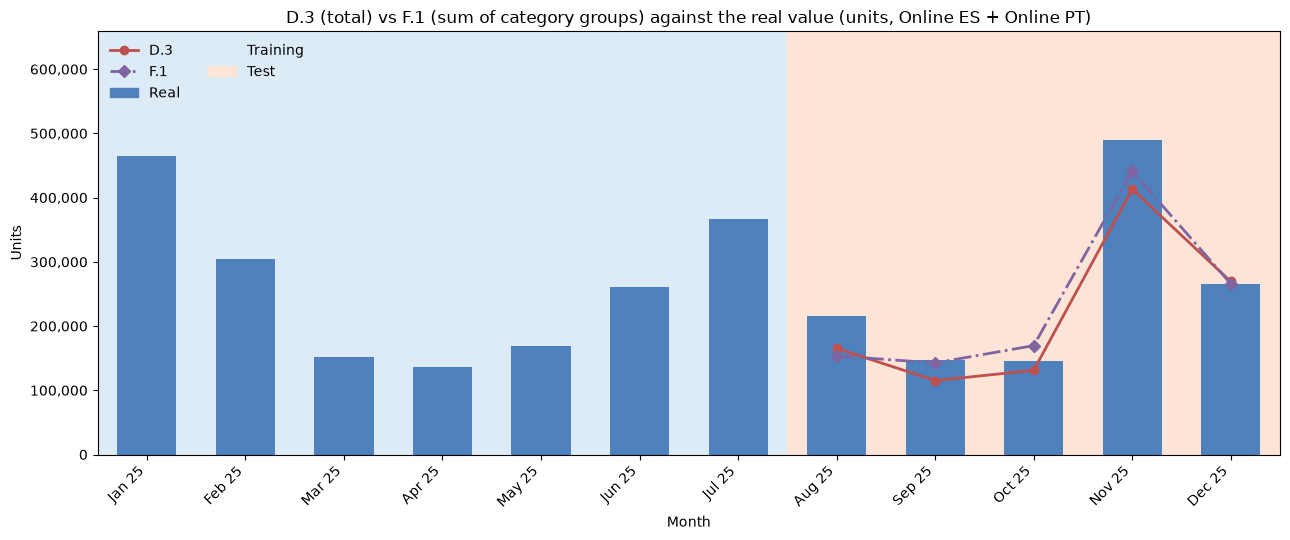

1. Overall metrics (units, all test days pooled):


,WAPE_pct,Bias_pct,RMSE,R2
model,,,,
D.3,22.87,-13.40,"4,182.27",0.91
F.1,19.49,-7.18,"3,801.51",0.92


2. WAPE by month (%):


model,D.3,F.1
month,,
2025-08,25.89,29.69
2025-09,22.47,10.17
2025-10,16.26,22.60
2025-11,20.87,15.94
2025-12,27.97,21.19


3. Bias by month (%; > 0 overestimates, < 0 underestimates):


model,D.3,F.1
month,,
2025-08,-23.45,-28.90
2025-09,-21.80,-3.19
2025-10,-9.75,16.80
2025-11,-15.70,-10.02
2025-12,1.74,0.43


4. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual   forecast                 error            error_pct  \
                          D.3        F.1        D.3        F.1       D.3   
month                                                                      
2025-08 215,951.00 165,302.20 153,539.00 -50,648.80 -62,412.00    -23.50   
2025-09 147,272.00 115,172.70 142,579.10 -32,099.30  -4,692.90    -21.80   
2025-10 145,193.00 131,042.60 169,585.80 -14,150.40  24,392.80     -9.70   
2025-11 490,281.00 413,285.20 441,146.30 -76,995.80 -49,134.70    -15.70   
2025-12 264,817.00 269,413.20 265,947.00   4,596.20   1,130.00      1.70   

                
           F.1  
month           
2025-08 -28.90  
2025-09  -3.20  
2025-10  16.80  
2025-11 -10.00  
2025-12   0.40

In [38]:
# ============================================================
# Comparison: D.3 vs F.1 against the real value (total units, monthly totals)
# D.3 forecasts the total directly; F.1 forecasts each category group and sums them
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

# ---------- Configuration ----------
COMPARE = {                       # model -> (predictions variable, colour, line style, marker)
    "D.3": ("d3_predictions", "#C0504D", "-",  "o"),
    "F.1": ("f1_predictions", "#8064A2", "-.", "D"),
}
REFERENCE = "D.3"
PLOT_FROM = "2025-01"
MIN_COVERAGE = 0.9
T = "units"
# ----------------------------------

missing = [v for v, *_ in COMPARE.values() if v not in globals()]
if missing:
    raise RuntimeError(f"Run the model cells first: {missing} not found.")

preds = pd.concat([globals()[v] for v, *_ in COMPARE.values()], ignore_index=True)
preds = preds[preds["target"] == T]
test_months = sorted(preds["month"].unique())

# 1. Monthly actual units (training + test months)
actual_daily = f1_total.to_frame()
actual_daily["month"] = actual_daily.index.to_period("M").astype(str)
days_in_data = actual_daily.groupby("month").size()
days_in_month = pd.Series({m: pd.Period(m).days_in_month for m in days_in_data.index})
monthly_actual = actual_daily.groupby("month")[T].sum()
monthly_actual = monthly_actual[(monthly_actual.index >= PLOT_FROM) & (monthly_actual.index <= test_months[-1])
                                & ((days_in_data / days_in_month).reindex(monthly_actual.index) >= MIN_COVERAGE)]
monthly_fc = preds.groupby(["model", "month"])["forecast"].sum()

# 2. Chart
fig, ax = plt.subplots(figsize=(13, 5.5))
months = list(monthly_actual.index)
x = np.arange(len(months))
first_test = months.index(test_months[0])
ax.axvspan(-0.5, first_test - 0.5, color="#DDEBF7", zorder=0)
ax.axvspan(first_test - 0.5, len(months) - 0.5, color="#FCE4D6", zorder=0)
ax.bar(x, monthly_actual.values, width=0.6, color="#4F81BD", zorder=2)
for model, (_, colour, style, marker) in COMPARE.items():
    ax.plot(x, [monthly_fc.get((model, m), np.nan) for m in months],
            color=colour, linestyle=style, marker=marker, linewidth=2, markersize=6, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(pd.to_datetime(months).strftime("%b %y"), rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(0, ax.get_ylim()[1] * 1.28)
ax.set_xlim(-0.5, len(months) - 0.5)
ax.set_title("D.3 (total) vs F.1 (sum of category groups) against the real value (units, Online ES + Online PT)")
ax.set_xlabel("Month")
ax.set_ylabel("Units")
handles = [Line2D([0], [0], color=c, linestyle=s, marker=mk, linewidth=2) for _, c, s, mk in COMPARE.values()]
handles += [Patch(color="#4F81BD"), Patch(color="#DDEBF7"), Patch(color="#FCE4D6")]
ax.legend(handles, list(COMPARE) + ["Real", "Training", "Test"], loc="upper left", ncol=2, frameon=False)
plt.tight_layout()
plt.show()

# 3. Tables
overall = pd.DataFrame([{"model": m, **error_metrics(g["actual"], g["forecast"])} for m, g in preds.groupby("model")])
print("1. Overall metrics (units, all test days pooled):")
display(overall.set_index("model").round(2))

by_month = pd.DataFrame([
    {"model": m, "month": mo, **error_metrics(g["actual"], g["forecast"])}
    for (m, mo), g in preds.groupby(["model", "month"])
])
print("2. WAPE by month (%):")
display(by_month.pivot_table(index="month", columns="model", values="WAPE_pct").round(2))
print("3. Bias by month (%; > 0 overestimates, < 0 underestimates):")
display(by_month.pivot_table(index="month", columns="model", values="Bias_pct").round(2))

print("4. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
totals = preds.groupby(["month", "model"])[["actual", "forecast"]].sum().reset_index()
fc_wide = totals.pivot_table(index="month", columns="model", values="forecast")
actual_m = totals.groupby("month")["actual"].first()
err = fc_wide.sub(actual_m, axis=0)
table4 = pd.concat({"actual": actual_m.to_frame(""), "forecast": fc_wide, "error": err,
                    "error_pct": 100 * err.div(actual_m, axis=0)}, axis=1)
display(table4.round(1))

### F.1: results

Forecasting units by category group and summing the groups is **more accurate than forecasting the total directly**. Over the whole test period, F.1 has a lower error than D.3, and its underestimation is roughly halved.

- **Black Friday (November)** was the main weakness of all previous models for units, and F.1 gets clearly closer to it. Each group has its own yearly lag and recent growth, so the model captures that some groups grew more than others during the peak, instead of applying an average growth to the total. This confirms that part of the error came from changes in the category mix that are hidden in the daily total.
- **September and December** are also forecast better, with December almost exact.
- **August is still underestimated,** slightly more than with D.3, as in all previous models.
- **October is overestimated,** while D.3 underestimated it. Some groups were expected to keep their recent growth, but demand slowed down in that month.

Feature importance shows which inputs the model relies on most, including whether the category group itself is used to adjust the forecast.

**Choice for the units target:** F.1 replaces D.3 for units. Its total is the sum of the group forecasts, so the dashboard shows a total that always matches the detail by group. Orders remain forecast by D.3 as a daily total. Combined, the two models give the warehouse, for each day, the number of orders to ship, the number of units to pick, the split of those units by type of product, and the average number of units per order.

## G. Paid media

Paid media investment was listed as a candidate feature with one condition: it is only useful if the future investment is known at the time of the forecast. This section tests how much it would improve the forecast if the investment plan were known two months in advance, as it could be in production if the marketing team shared its plan.

The model starts from D.3, the best model for orders, and forecasts both orders and units. If paid media improves the forecast, applying it to the units model by category group (F.1) can be evaluated afterwards.

### G.1: D.3 + paid media (scenario)

**Scenario.** In the test months, the model uses the actual paid media investment, as if it were the plan known at the time of the forecast. As with B.3, this is not a production model: it measures how much the forecast would improve if the investment plan were provided as an input.

**Feature relative to the previous year.** The yearly lag carries last year's sales, which already include the effect of last year's investment. To avoid counting this effect twice, the feature compares the investment with the previous year: the investment of the last 7 days divided by the same 7 days of the previous year, on a logarithmic scale. It is 0 when the investment is the same as last year, positive when it is higher and negative when it is lower, so the model only reacts when the investment differs from the previous year. A 7-day window is used because daily investment varies a lot and its effect on sales is not limited to the same day.

**Everything else is the same as D.3:** inputs, recent growth, target, settings compared by cross-validation and forecasting rule, so the comparison with D.3 measures only the effect of paid media.

In [39]:
# ============================================================
# G.1 - D.3 + paid media (scenario): XGBoost with the paid media investment relative to the previous year
# Scenario: in the test months the actual investment is used as if it were the plan known in advance.
# Feature: log(investment of the last 7 days / same 7 days of the previous year); 0 = same as last year.
# Everything else is the same as D.3.
# Forecasting rule: each month is forecast with data up to the last day
# of the month two months before (e.g. September 2025 -> data up to 31 July 2025)
# ============================================================
import numpy as np
try:
    from xgboost import XGBRegressor
except ModuleNotFoundError:
    raise RuntimeError("xgboost is not installed: run %pip install xgboost in a cell and restart the kernel.")

# ---------- Configuration ----------
G1_ID = "G.1"
G1_NAME = "G.1 XGBoost (D.3 + paid media vs last year, scenario)"
G1_PM_TABLE = "paid_media"                # folder of the paid media table in the bronze layer
G1_PM_DATE, G1_PM_MARKET, G1_PM_AMOUNT = "date_sfk", "Marketplace", "amount_paid_media"
G1_PM_MARKETS = MARKETS                   # markets to keep (same as base_ml, case-insensitive)
G1_PM_WINDOW = 7                          # investment summed over 7 days before comparing with last year
G1_RECENT_LAGS = list(range(62, 69))
G1_YEARLY_LAG = 364
G1_GROWTH_WINDOW = 28
G1_GROWTH_END_LAG = 62
G1_CAMPAIGNS = {
    "Black Friday": "camp_black_friday",
    "Christmas": "camp_christmas",
    "Mothers Day": "camp_mothers_day",
    "Reyes": "camp_reyes",
    "Valentines": "camp_valentines",
    "Easter and Holy Week": "camp_easter_holy_week",
}
G1_XGB_FIXED = dict(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=7,
                    tree_method="hist", random_state=42, n_jobs=1)          # same as D.3
G1_PARAM_GRID = [{"max_depth": d, "reg_lambda": l} for d in (2, 3) for l in (1, 10)]
G1_MAX_TREES = 600
G1_TREE_STEP = 50
G1_DEFAULT = {"max_depth": 3, "reg_lambda": 1, "n_estimators": 300}
G1_CV_FOLDS = 3
G1_CV_VALID_DAYS = 28
G1_CV_GAP_DAYS = 30
G1_CV_MIN_TRAIN = 28
TARGETS = ["orders", "units"]
TEST_MONTHS = ["2025-08", "2025-09", "2025-10", "2025-11", "2025-12"]
# ----------------------------------

# 0. Check that base_ml and events_grouped_v exist
for view in ["base_ml", "events_grouped_v"]:
    try:
        con_b.sql(f"SELECT 1 FROM {view} LIMIT 1")
    except Exception:
        raise RuntimeError(f"{view} not found: run the cell that creates base_ml (including step 1b) first.")

# 1. Daily series of the two targets (SALE lines only)
g1_daily = con_b.sql("""
    SELECT CAST(ORDER_DATE AS DATE) AS day,
           COUNT(DISTINCT ORDER_ID) AS orders,
           SUM(PROD_QTY) AS units
    FROM base_ml
    WHERE "TYPE" = 'SALE'
    GROUP BY 1
    ORDER BY 1
""").df()
g1_daily["day"] = pd.to_datetime(g1_daily["day"])
g1_daily = g1_daily.set_index("day").asfreq("D", fill_value=0)
print(f"Daily series: {len(g1_daily)} days, from {g1_daily.index.min().date()} to {g1_daily.index.max().date()}")

# 2. Paid media: daily investment in the markets in scope (PT + ES)
pm_src = source(G1_PM_TABLE)
pm_raw = con_b.sql(f"""
    SELECT "{G1_PM_DATE}" AS date_raw,
           TRIM(CAST("{G1_PM_MARKET}" AS VARCHAR)) AS market,
           TRY_CAST("{G1_PM_AMOUNT}" AS DOUBLE) AS amount
    FROM {pm_src}
""").df()

print("\nMarketplace values in paid_media (investment by value):")
display(pm_raw.groupby("market", dropna=False)["amount"].agg(["count", "sum"]))

pm = pm_raw[pm_raw["market"].str.lower().isin([m.lower() for m in G1_PM_MARKETS])].copy()
if pm.empty:
    raise RuntimeError("No paid media rows for the markets in G1_PM_MARKETS: "
                       "set G1_PM_MARKETS to the Marketplace values shown above.")

# date_sfk can be a date or a number such as 20250131
if pd.api.types.is_numeric_dtype(pm["date_raw"]):
    pm["day"] = pd.to_datetime(pm["date_raw"].astype("Int64").astype(str), format="%Y%m%d", errors="coerce")
else:
    pm["day"] = pd.to_datetime(pm["date_raw"], errors="coerce")
if pm["day"].isna().any():
    print(f"Warning: {pm['day'].isna().sum()} paid media rows with an invalid date were ignored.")

pm_daily = pm.dropna(subset=["day"]).groupby("day")["amount"].sum()
pm_daily = pm_daily.reindex(g1_daily.index, fill_value=0)       # days without investment = 0
print(f"\nPaid media covers {pm['day'].min().date()} to {pm['day'].max().date()}")

print("Monthly investment, PT + ES:")
pm_month = pm_daily.groupby(pm_daily.index.to_period("M")).sum()
display(pd.DataFrame({"2024": pm_month[pm_month.index.year == 2024].values},
                     index=[p.strftime("%b") for p in pm_month.index[pm_month.index.year == 2024]])
        .join(pd.DataFrame({"2025": pm_month[pm_month.index.year == 2025].values},
                           index=[p.strftime("%b") for p in pm_month.index[pm_month.index.year == 2025]]),
              how="outer"))

# 3. Paid media feature relative to the previous year (log ratio; 0 = same investment as last year)
#    Missing when there is no investment in either year; XGBoost handles missing values natively.
pm_window = pm_daily.rolling(G1_PM_WINDOW).sum()
pm_window_ly = pm_window.shift(G1_YEARLY_LAG)
g1_daily["paid_media_vs_ly"] = np.log(pm_window.replace(0, np.nan) / pm_window_ly.replace(0, np.nan))

# 4. Lag features, recent growth and target (same definitions as D.3)
for t in TARGETS:
    for lag in G1_RECENT_LAGS + [G1_YEARLY_LAG]:
        g1_daily[f"{t}_lag_{lag}"] = g1_daily[t].shift(lag)
    recent = g1_daily[t].rolling(G1_GROWTH_WINDOW).sum().shift(G1_GROWTH_END_LAG)
    recent_last_year = recent.shift(G1_YEARLY_LAG)
    g1_daily[f"{t}_recent_growth"] = recent / recent_last_year.replace(0, np.nan)
    g1_daily[f"{t}_ratio"] = g1_daily[t] / g1_daily[f"{t}_lag_{G1_YEARLY_LAG}"].replace(0, np.nan)
    g1_daily[f"{t}_deviation"] = g1_daily[f"{t}_ratio"] / g1_daily[f"{t}_recent_growth"]

# 5. Fixed campaigns relative to the previous year (same design as B.1)
camp = con_b.sql(f"""
    SELECT campaign, start_date, end_date
    FROM events_grouped_v
    WHERE LOWER(market) IN ({markets_sql})
""").df()
camp_active = pd.DataFrame(0, index=g1_daily.index, columns=list(G1_CAMPAIGNS.values()))
for family, col in G1_CAMPAIGNS.items():
    for _, row in camp[camp["campaign"] == family].iterrows():
        camp_active.loc[pd.Timestamp(row["start_date"]):pd.Timestamp(row["end_date"]), col] = 1
camp_diff = (camp_active - camp_active.shift(G1_YEARLY_LAG).fillna(0).astype(int)).add_suffix("_vs_ly")
g1_daily = g1_daily.join(camp_diff)
G1_CAMP = list(camp_diff.columns)

def g1_features(t):
    return [f"{t}_lag_{lag}" for lag in G1_RECENT_LAGS + [G1_YEARLY_LAG]] + G1_CAMP + ["paid_media_vs_ly"]

print("\nPaid media vs last year in the test period (share of days with the feature available, average):")
test_period = g1_daily.loc[f"{TEST_MONTHS[0]}-01":f"{TEST_MONTHS[-1]}"]
display(test_period["paid_media_vs_ly"].groupby(test_period.index.to_period("M").astype(str))
        .agg(available_pct=lambda s: 100 * s.notna().mean(), mean_log_ratio="mean").round(2))

# 6. Error metrics (as defined in the "Error metrics" section)
def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

# 7. Time-series cross-validation inside the training data (same as D.3)
def g1_cv_folds(n_days):
    folds = []
    for k in range(G1_CV_FOLDS):
        valid_end = n_days - k * G1_CV_VALID_DAYS
        valid_start = valid_end - G1_CV_VALID_DAYS
        train_end = valid_start - G1_CV_GAP_DAYS
        if train_end < G1_CV_MIN_TRAIN:
            break
        folds.append((np.arange(0, train_end), np.arange(valid_start, valid_end)))
    return folds[::-1]

def g1_to_volume(deviation, part, t):
    return (deviation * part[f"{t}_recent_growth"].to_numpy()
            * part[f"{t}_lag_{G1_YEARLY_LAG}"].to_numpy())

def g1_choose_params(train_t, t):
    folds = g1_cv_folds(len(train_t))
    if not folds:
        return G1_DEFAULT, np.nan, 0
    features = g1_features(t)
    tree_counts = list(range(G1_TREE_STEP, G1_MAX_TREES + 1, G1_TREE_STEP))
    best = (None, np.inf)
    for params in G1_PARAM_GRID:
        wape_by_trees = []
        for tr, va in folds:
            part_tr, part_va = train_t.iloc[tr], train_t.iloc[va]
            model = XGBRegressor(n_estimators=G1_MAX_TREES, **params, **G1_XGB_FIXED)
            model.fit(part_tr[features], part_tr[f"{t}_deviation"])
            actual = part_va[t].to_numpy()
            wape_by_trees.append([
                100 * np.abs(g1_to_volume(model.predict(part_va[features], iteration_range=(0, n)), part_va, t)
                             - actual).sum() / actual.sum()
                for n in tree_counts
            ])
        mean_wape = np.mean(wape_by_trees, axis=0)
        i = int(np.argmin(mean_wape))
        if mean_wape[i] < best[1]:
            best = ({**params, "n_estimators": tree_counts[i]}, mean_wape[i])
    return best[0], best[1], len(folds)

# 8. Evaluation by calendar month
g1_results, g1_predictions, g1_importance, g1_chosen = [], [], {}, []
for month in TEST_MONTHS:
    month_start = pd.Timestamp(f"{month}-01")
    month_end = month_start + pd.offsets.MonthEnd(0)
    cutoff = month_start - pd.DateOffset(months=1) - pd.Timedelta(days=1)

    train = g1_daily[g1_daily.index <= cutoff]
    test = g1_daily[(g1_daily.index >= month_start) & (g1_daily.index <= month_end)]

    # leakage check for the lags (paid media in the test month is the scenario input, known by assumption)
    assert (test.index - pd.Timedelta(days=min(G1_RECENT_LAGS))).max() <= cutoff

    for t in TARGETS:
        features = g1_features(t)
        lag_cols = [f for f in features if f != "paid_media_vs_ly"]
        train_t = train.dropna(subset=lag_cols + [f"{t}_deviation"])   # paid media may be missing (handled by XGBoost)

        params, cv_wape, n_folds = g1_choose_params(train_t, t)
        model = XGBRegressor(**params, **G1_XGB_FIXED).fit(train_t[features], train_t[f"{t}_deviation"])
        forecast = g1_to_volume(model.predict(test[features]), test, t)
        actual = test[t].to_numpy()
        g1_importance[(t, month)] = pd.Series(model.feature_importances_, index=features)
        g1_chosen.append({"target": t, "month": month, "cv_folds": n_folds, **params, "cv_WAPE_pct": cv_wape})

        g1_results.append({
            "model": G1_ID, "target": t, "month": month,
            "data_up_to": cutoff.date(),
            "train_from": train_t.index.min().date(),
            "train_days": len(train_t),
            "recent_growth": test[f"{t}_recent_growth"].mean(),
            "actual_growth": test[t].sum() / test[f"{t}_lag_{G1_YEARLY_LAG}"].sum(),
            **error_metrics(actual, forecast),
        })
        g1_predictions.append(pd.DataFrame({
            "model": G1_ID, "day": test.index, "target": t, "month": month,
            "actual": actual, "forecast": forecast,
        }))

g1_results = pd.DataFrame(g1_results)
g1_predictions = pd.concat(g1_predictions, ignore_index=True)
g1_chosen = pd.DataFrame(g1_chosen)

print("\nSettings chosen by cross-validation for each test month:")
display(g1_chosen)

print("Results by month:")
display(g1_results)

print("Overall results (all test days pooled):")
g1_overall = pd.DataFrame([
    {"model": G1_ID, "target": t, **error_metrics(g["actual"], g["forecast"])}
    for t, g in g1_predictions.groupby("target")
])
display(g1_overall)

# 9. Feature importance (average over the test months)
print("Feature importance (share of the error reduction, average over the test months, %):")
importance = pd.DataFrame({
    t: pd.concat([s.rename(lambda f: f.replace(f"{t}_", "")) for (tt, _), s in g1_importance.items() if tt == t], axis=1).mean(axis=1)
    for t in TARGETS
}).sort_values(TARGETS[0], ascending=False)
display((100 * importance).round(1))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Daily series: 731 days, from 2024-01-01 to 2025-12-31

Marketplace values in paid_media (investment by value):


,count,sum
market,,
Online AT,727,"14,649.43"
Online BE,727,"34,134.19"
Online CH,464,"22,386.34"
Online CZ,538,"8,181.16"
Online DE,727,"95,884.13"
Online DK,258,"10,396.69"
Online EE,478,"3,407.85"
Online ES,731,"3,759,240.68"
Online FR,731,"619,468.18"



Paid media covers 2024-01-01 to 2025-12-31
Monthly investment, PT + ES:


,2024,2025
Apr,"111,604.83","172,848.17"
Aug,"124,067.39","163,742.03"
Dec,"293,243.32","344,861.05"
Feb,"84,067.96","199,864.96"
Jan,"143,333.17","312,912.85"
Jul,"164,756.54","275,589.07"
Jun,"177,491.75","264,954.68"
Mar,"91,621.10","164,748.90"
May,"143,621.72","204,875.51"
Nov,"270,679.25","546,193.33"



Paid media vs last year in the test period (share of days with the feature available, average):


... (5 outputs left out)

Overall results (all test days pooled):


,model,target,WAPE_pct,Bias_pct,RMSE,R2
0,G.1,orders,20.49,-5.76,"1,402.65",0.93
1,G.1,units,21.20,-9.78,"3,952.22",0.92


Feature importance (share of the error reduction, average over the test months, %):


,orders,units
lag_364,26.30,35.90
lag_67,11.80,7.20
lag_68,11.60,13.00
paid_media_vs_ly,10.10,10.80
camp_easter_holy_week_vs_ly,8.50,5.90
lag_66,7.20,6.10
lag_62,7.00,4.80
lag_64,6.20,4.70
lag_65,6.00,6.40
lag_63,5.20,5.10


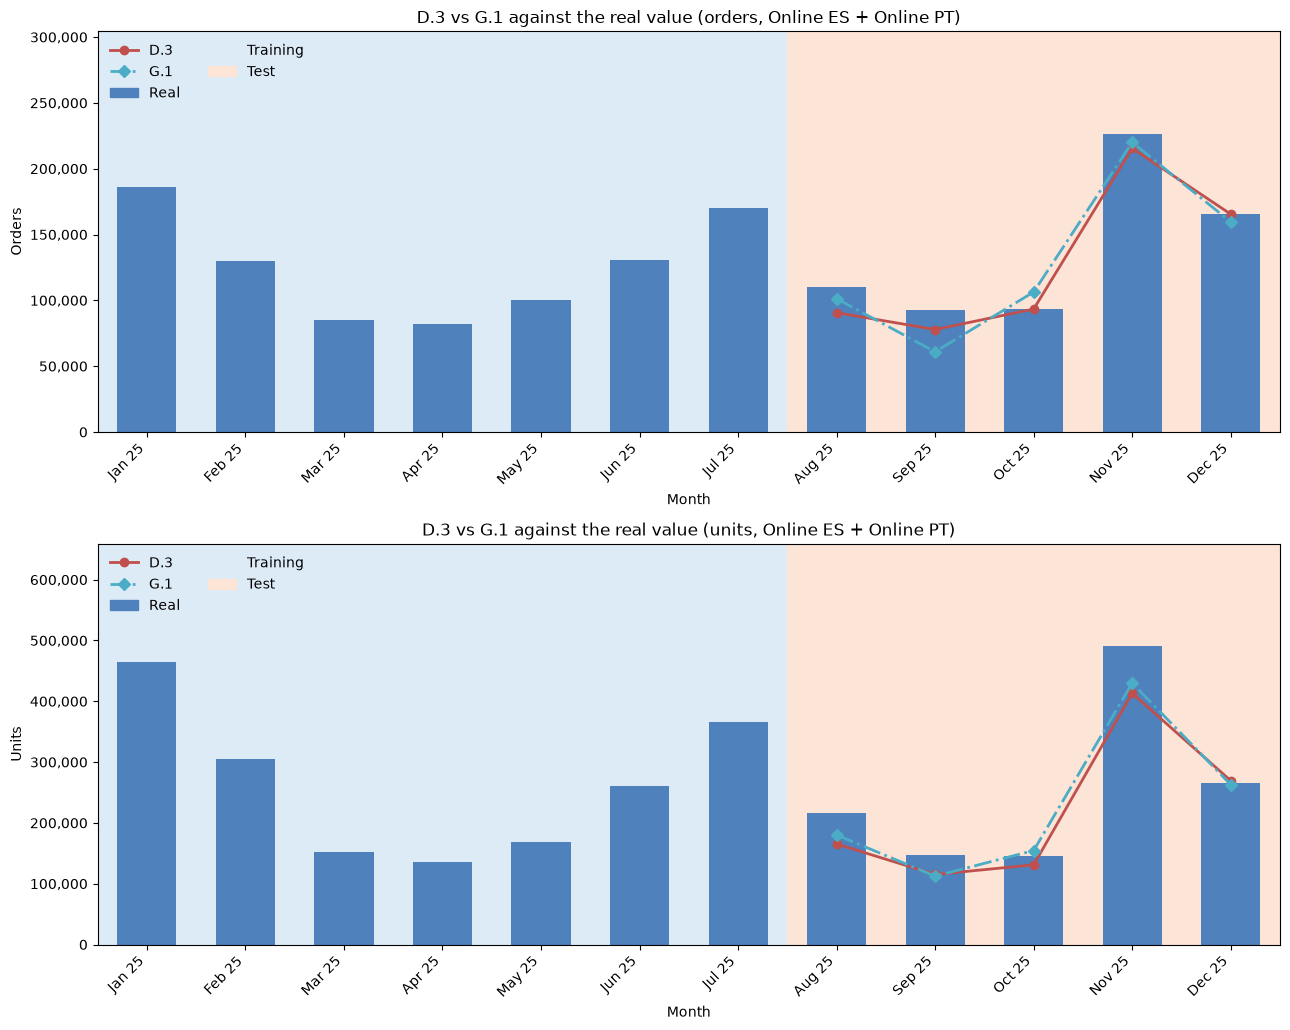

1. Overall metrics (all test days pooled):


,,WAPE_pct,Bias_pct,RMSE,R2
target,model,,,,
orders,D.3,19.29,-6.51,"1,481.24",0.92
units,D.3,22.87,-13.40,"4,182.27",0.91
orders,G.1,20.49,-5.76,"1,402.65",0.93
units,G.1,21.20,-9.78,"3,952.22",0.92


2. WAPE by month (%):


model            D.3   G.1
target month              
orders 2025-08 19.54 17.05
       2025-09 17.00 35.55
       2025-10 12.46 21.68
       2025-11 16.05 14.89
       2025-12 28.67 21.36
units  2025-08 25.89 19.80
       2025-09 22.47 25.99
       2025-10 16.26 18.18
       2025-11 20.87 19.28
       2025-12 27.97 24.89

3. Bias by month (%; > 0 overestimates, < 0 underestimates):


model             D.3    G.1
target month                
orders 2025-08 -17.46  -7.82
       2025-09 -15.82 -34.11
       2025-10   0.24  14.13
       2025-11  -4.82  -2.84
       2025-12  -0.16  -3.73
units  2025-08 -23.45 -16.61
       2025-09 -21.80 -23.67
       2025-10  -9.75   6.45
       2025-11 -15.70 -12.30
       2025-12   1.74  -0.70

4. Monthly totals: actual, forecast and error of each model (error = forecast - actual):


actual   forecast                 error             \
                                 D.3        G.1        D.3        G.1   
target month                                                            
orders 2025-08 109,819.00  90,640.00 101,226.20 -19,179.00  -8,592.80   
       2025-09  92,480.00  77,849.60  60,935.10 -14,630.40 -31,544.90   
       2025-10  93,177.00  93,401.70 106,347.00     224.70  13,170.00   
       2025-11 226,443.00 215,520.30 220,010.20 -10,922.70  -6,432.80   
       2025-12 165,749.00 165,476.20 159,571.20    -272.80  -6,177.80   
units  2025-08 215,951.00 165,302.20 180,091.80 -50,648.80 -35,859.20   
       2025-09 147,272.00 115,172.70 112,408.30 -32,099.30 -34,863.70   
       2025-10 145,193.00 131,042.60 154,555.80 -14,150.40   9,362.80   
       2025-11 490,281.00 413,285.20 429,982.20 -76,995.80 -60,298.80   
       2025-12 264,817.00 269,413.20 262,966.60   4,596.20  -1,850.40   

               error_pct         
                     D.3    G.1  
target month                     
orders 2025-08    -17.50  -7.80  
       2025-09    -15.80 -34.10  
       2025-10      0.20  14.10  
       2025-11     -4.80  -2.80  
       2025-12     -0.20  -3.70  
units  2025-08    -23.50 -16.60  
       2025-09    -21.80 -23.70  
       2025-10     -9.70   6.40  
       2025-11    -15.70 -12.30  
       2025-12      1.70  -0.70

In [40]:
# ============================================================
# Comparison: D.3 vs G.1 against the real value (monthly totals, orders and units)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

COMPARE = {
    "D.3": ("d3_predictions", "#C0504D", "-",  "o"),
    "G.1": ("g1_predictions", "#4BACC6", "-.", "D"),
}
REFERENCE = "D.3"
PLOT_FROM = "2025-01"
MIN_COVERAGE = 0.9
TARGETS = ["orders", "units"]

missing = [v for v, *_ in COMPARE.values() if v not in globals()]
if missing:
    raise RuntimeError(f"Run the model cells first: {missing} not found.")

preds = pd.concat([globals()[v] for v, *_ in COMPARE.values()], ignore_index=True)
test_months = sorted(preds["month"].unique())

monthly_actual = g1_daily[TARGETS].copy()
monthly_actual["month"] = monthly_actual.index.to_period("M").astype(str)
days_in_data = monthly_actual.groupby("month").size()
days_in_month = pd.Series({m: pd.Period(m).days_in_month for m in days_in_data.index})
monthly_actual = monthly_actual.groupby("month")[TARGETS].sum()
monthly_actual = monthly_actual[(monthly_actual.index >= PLOT_FROM) & (monthly_actual.index <= test_months[-1])
                                & ((days_in_data / days_in_month).reindex(monthly_actual.index) >= MIN_COVERAGE)]
monthly_fc = preds.groupby(["model", "target", "month"])["forecast"].sum()

fig, axes = plt.subplots(len(TARGETS), 1, figsize=(13, 5.2 * len(TARGETS)))
for ax, t in zip(np.atleast_1d(axes), TARGETS):
    months = list(monthly_actual.index)
    x = np.arange(len(months))
    first_test = months.index(test_months[0])
    ax.axvspan(-0.5, first_test - 0.5, color="#DDEBF7", zorder=0)
    ax.axvspan(first_test - 0.5, len(months) - 0.5, color="#FCE4D6", zorder=0)
    ax.bar(x, monthly_actual[t].values, width=0.6, color="#4F81BD", zorder=2)
    for model, (_, colour, style, marker) in COMPARE.items():
        ax.plot(x, [monthly_fc.get((model, t, m), np.nan) for m in months],
                color=colour, linestyle=style, marker=marker, linewidth=2, markersize=6, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(pd.to_datetime(months).strftime("%b %y"), rotation=45, ha="right")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.28)
    ax.set_xlim(-0.5, len(months) - 0.5)
    ax.set_title(f"{' vs '.join(COMPARE)} against the real value ({t}, Online ES + Online PT)")
    ax.set_xlabel("Month")
    ax.set_ylabel(t.capitalize())
    handles = [Line2D([0], [0], color=c, linestyle=s, marker=mk, linewidth=2) for _, c, s, mk in COMPARE.values()]
    handles += [Patch(color="#4F81BD"), Patch(color="#DDEBF7"), Patch(color="#FCE4D6")]
    ax.legend(handles, list(COMPARE) + ["Real", "Training", "Test"], loc="upper left", ncol=2, frameon=False)
plt.tight_layout()
plt.show()

overall = pd.DataFrame([{"model": m, "target": t, **error_metrics(g["actual"], g["forecast"])}
                        for (m, t), g in preds.groupby(["model", "target"])])
print("1. Overall metrics (all test days pooled):")
display(overall.set_index(["target", "model"]).round(2))

by_month = pd.DataFrame([{"model": m, "target": t, "month": mo, **error_metrics(g["actual"], g["forecast"])}
                         for (m, t, mo), g in preds.groupby(["model", "target", "month"])])
print("2. WAPE by month (%):")
display(by_month.pivot_table(index=["target", "month"], columns="model", values="WAPE_pct").round(2))
print("3. Bias by month (%; > 0 overestimates, < 0 underestimates):")
display(by_month.pivot_table(index=["target", "month"], columns="model", values="Bias_pct").round(2))

print("4. Monthly totals: actual, forecast and error of each model (error = forecast - actual):")
totals = preds.groupby(["target", "month", "model"])[["actual", "forecast"]].sum().reset_index()
fc_wide = totals.pivot_table(index=["target", "month"], columns="model", values="forecast")
actual_m = totals.groupby(["target", "month"])["actual"].first()
err = fc_wide.sub(actual_m, axis=0)
display(pd.concat({"actual": actual_m.to_frame(""), "forecast": fc_wide, "error": err,
                   "error_pct": 100 * err.div(actual_m, axis=0)}, axis=1).round(1))

### G.1: results

Paid media does not improve the forecast enough to be kept, even in this scenario, where the actual investment is used as if it were known two months in advance.

- **Orders:** G.1 is less accurate than D.3 overall. It improves August and November, but makes large errors in September, which is strongly underestimated, and in October, which is overestimated. The model reacts to differences in investment from the previous year in an unstable way.
- **Units:** G.1 is more accurate than D.3 and underestimates less, with gains in August, November and December. However, it remains less accurate than F.1, which forecasts units by category group without paid media.
- **September** is worse for both targets. With only a few months of training data, the model gives too much weight to the difference in investment between the two years.

**Conclusion.** As this is a scenario, these results are an upper limit of what paid media could add: in production, the investment plan would be less precise than the actual investment. Since the gain is small for units and negative for orders, paid media is not added to the final models. D.3 remains the model for orders and F.1 the model for units. With a longer history, the effect of the investment could be learned from more examples, and paid media could be re-evaluated, provided the marketing plan is available at the time of the forecast.

### Summary of the results:

In [43]:
# ============================================================
# Summary of all models (A.1 to G.1): overall metrics, all test days pooled
# One table for orders and one for units. Metrics as defined in the "Error metrics" section.
# ============================================================
import numpy as np
import pandas as pd

# ---------- Configuration ----------
SUMMARY_MODELS = {          # model -> (predictions variable, short description)
    "A.1": ("it1_predictions", "Linear regression: lags 62-68"),
    "A.2": ("it2_predictions", "Linear regression: lags 62-68 + lag 364"),
    "A.3": ("it3_predictions", "A.2 + average of the previous year's week"),
    "A.4": ("it4_predictions", "Linear regression: calendar only"),
    "B.1": ("b1_predictions",  "A.2 + day of the week + fixed campaigns"),
    "B.2": ("b2_predictions",  "B.1 + public holidays + paydays"),
    "B.3": ("b3_predictions",  "Scenario: A.2 + planned campaign (October)"),
    "C.1": ("c1_predictions",  "Random Forest (ratio to the previous year)"),
    "C.2": ("c2_predictions",  "C.1 + recent growth"),
    "C.3": ("c3_predictions",  "Linear regression with C.2 structure (control)"),
    "C.4": ("c4_predictions",  "C.2 + time-series cross-validation"),
    "D.1": ("d1_predictions",  "Gradient Boosting + cross-validation"),
    "D.2": ("d2_predictions",  "D.1 with 1% learning steps"),
    "D.3": ("d3_predictions",  "XGBoost + cross-validation"),
    "E.1": ("e1_predictions",  "Ridge regression + cross-validation"),
    "F.1": ("f1_predictions",  "XGBoost by category group (units only)"),
    "G.1": ("g1_predictions",  "Scenario: D.3 + paid media"),
}
SCENARIOS = {"B.3", "G.1"}  # models that use information assumed to be known in advance
# ----------------------------------

def error_metrics(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    err = forecast - actual
    return {
        "WAPE_pct": 100 * np.abs(err).sum() / actual.sum(),
        "Bias_pct": 100 * err.sum() / actual.sum(),          # > 0 overestimates, < 0 underestimates
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2),
    }

rows, missing = [], []
for model, (var, description) in SUMMARY_MODELS.items():
    if var not in globals():
        missing.append(model)
        continue
    preds = globals()[var]
    for t, g in preds.groupby("target"):
        rows.append({
            "target": t,
            "model": model,
            "description": description,
            "scenario": "yes" if model in SCENARIOS else "",
            "test_days": len(g),
            **error_metrics(g["actual"], g["forecast"]),
        })

if missing:
    print(f"Not included (run their cells first): {missing}\n")

summary = pd.DataFrame(rows)

# all models must be evaluated on the same test days, otherwise the comparison is not fair
for t, g in summary.groupby("target"):
    if g["test_days"].nunique() > 1:
        print(f"Warning: models for {t} were evaluated on a different number of test days:")
        display(g[["model", "test_days"]])

def show_summary(t):
    table = (summary[summary["target"] == t]
             .drop(columns="target")
             .set_index("model"))
    best_wape = table.loc[table["scenario"] == "", "WAPE_pct"].idxmin()
    table["best"] = np.where(table.index == best_wape, "◄ lowest WAPE", "")
    display(table.style
            .format({"WAPE_pct": "{:.2f}", "Bias_pct": "{:+.2f}", "RMSE": "{:,.0f}", "R2": "{:.2f}"})
            .highlight_min(subset=["WAPE_pct", "RMSE"], color="#E2EFDA")
            .set_caption(f"{t.capitalize()}: overall metrics of all models (all test days pooled, Aug–Dec 2025)"))

print("ORDERS")
show_summary("orders")
print("\nUNITS")
show_summary("units")

print("WAPE and Bias in %; Bias > 0 = overestimates, < 0 = underestimates; RMSE in orders or units per day.")
print("Scenario = uses information assumed to be known in advance (not a production model);")
print("the 'lowest WAPE' mark excludes scenarios. Green = lowest value in the column.")

ORDERS


,description,scenario,test_days,WAPE_pct,Bias_pct,RMSE,R2,best
model,,,,,,,,
A.1,Linear regression: lags 62-68,,153,38.48,-17.47,"5,347",-0.02,
A.2,Linear regression: lags 62-68 + lag 364,,153,23.40,+13.46,"1,625",0.91,
A.3,A.2 + average of the previous year's week,,153,30.73,+23.11,"2,042",0.85,
A.4,Linear regression: calendar only,,153,48.90,+12.16,"5,056",0.09,
B.1,A.2 + day of the week + fixed campaigns,,153,23.57,+13.42,"1,629",0.91,
B.2,B.1 + public holidays + paydays,,153,24.67,+13.32,"1,691",0.90,
B.3,Scenario: A.2 + planned campaign (October),yes,153,23.46,+13.48,"1,631",0.90,
C.1,Random Forest (ratio to the previous year),,153,24.68,+18.31,"1,515",0.92,
C.2,C.1 + recent growth,,153,18.15,-6.44,"1,336",0.94,



UNITS


,description,scenario,test_days,WAPE_pct,Bias_pct,RMSE,R2,best
model,,,,,,,,
A.1,Linear regression: lags 62-68,,153,50.49,-14.45,"13,613",-0.00,
A.2,Linear regression: lags 62-68 + lag 364,,153,32.80,+24.17,"4,264",0.90,
A.3,A.2 + average of the previous year's week,,153,41.79,+33.84,"5,915",0.81,
A.4,Linear regression: calendar only,,153,68.21,+19.78,"13,106",0.07,
B.1,A.2 + day of the week + fixed campaigns,,153,33.20,+24.60,"4,342",0.90,
B.2,B.1 + public holidays + paydays,,153,35.70,+24.89,"4,562",0.89,
B.3,Scenario: A.2 + planned campaign (October),yes,153,32.92,+24.35,"4,281",0.90,
C.1,Random Forest (ratio to the previous year),,153,34.83,+26.48,"4,508",0.89,
C.2,C.1 + recent growth,,153,23.22,-13.01,"4,017",0.91,


WAPE and Bias in %; Bias > 0 = overestimates, < 0 = underestimates; RMSE in orders or units per day.
Scenario = uses information assumed to be known in advance (not a production model);
the 'lowest WAPE' mark excludes scenarios. Green = lowest value in the column.
